# ClimRisk-LATAM: climate-conditioned robust portfolios in Latin American equity markets
Replication notebook with real data

This notebook implements, end to end, a portfolio selection model based on distributionally robust optimization (DRO) over type-2 Wasserstein balls, in which climate enters through three channels: (i) the nominal scenario measure, which weights historical months by the similarity of their climate state with the current one; (ii) the metric of the transport cost, which makes adverse displacements cheaper along the risk directions induced by the climate innovations filtered with a state-space model; and (iii) the feasible set, which imposes a decarbonization path aligned with the European Union benchmarks and a limit on the physical exposure measured from data. The model is evaluated with a rolling-origin protocol in Brazil, Mexico, Colombia and Chile (2018–2025, 96 months), against five benchmark strategies and the ETF of each country.

All series are downloaded from their official source or read from the official file provided by the user (Aqueduct). The only randomness is the bootstrap resampling, which belongs to the inference and not to the data. Every download is saved, with its date and hash, in `data_snapshot/` (§E0), so that a later run can reproduce the results with the same data vintage.

| Variable | Source | Access |
|---|---|---|
| Prices of 55 issuers | Yahoo Finance (dividend-adjusted monthly bars, month end) | Automatic download |
| Exchange rates, commodities, Treasury bill and country ETFs (EWZ, EWW, ECH, ICOLCAP) | Yahoo Finance (adjusted daily closes, last of the month) | Automatic download |
| ENSO | NOAA PSL, Multivariate ENSO Index v2 (MEI v2) | Automatic download |
| Regional temperature anomaly | NASA GISTEMP v4 via NOAA PSL | Automatic download |
| Carbon price | World Bank, Carbon Pricing Dashboard, and official regulations (DIAN; Chile's Law 20,780) | Automatic download |
| Water risk | WRI Aqueduct 4.0, annual baseline | Official zip uploaded to Colab |
| Transition intensity (CI) | Declared expert prior of the authors | Embedded |
| Physical exposure (PHYS) | Computed: response to ENSO news and water risk in the regions of operation | Computed |

Before running, upload the Aqueduct 4.0 zip (`aqueduct-4-0-water-risk-data.zip`, or the zip that contains it) to `/content`. Approximate running times on a standard Colab CPU runtime: §E (downloads and data assembly) a few minutes, depending on the network; §F0–§F3 about 4 to 6 minutes; §F4 about 45 to 65 minutes; §F6 about 3 minutes; §F8 about 30 to 45 minutes; §F9 about 6 to 10 minutes; the rest a few seconds. The complete notebook takes about 2 to 2.5 hours. Sections F4, F6, F8 and F9 can be switched off with `RUN_F4`, `RUN_F6`, `RUN_F8` and `RUN_F9` and run later without repeating the previous cells. See `README.md` for details.

## Structure of the notebook
| Section | Content |
|---|---|
| §0 | Problem statement and notation |
| §1–§10 | Model engine: protocol, climate state, state-space model, nominal measure, metric, feasible set, robust optimization, metrics, inference and backtest |
| §A | Analysis functions: ablations, radius frontier, panel and figures |
| §D | Documentary data and download functions; measurement of the physical channel |
| §E | Run information and data snapshot; loading of real data, exposures and assembly by market |
| §F0 | Diagnostics before the evaluation |
| §F1–§F10 | Results: backtest, feasible set and radius, inference, ablations, state-space model, robustness, equivalence tests, convergence and sensitivity of the EM algorithm, information available at each decision, and export of tables and saved results |
| §G | Annex for the referees: strategy and radius of the specification of the submitted manuscript |
| References | Methodological and data sources |

## §0. Problem statement and notation
In each market $m$, at the close of month $t$ an investor chooses a weight vector $w_t\in\mathcal W_t\subset\Delta^{N}$ (no short sales) for month $t+1$. Monthly simple returns in USD are $r_{t+1}\in\mathbb R^N$ and the portfolio loss is $\ell_w(r)=-w^\top r$. The risk criterion is the conditional value at risk at level $\alpha$,
$$\operatorname{CVaR}^Q_\alpha(\ell_w)=\min_{\tau\in\mathbb R}\Big\{\tau+\tfrac{1}{\alpha}\,\mathbb E_Q\big[(\ell_w(r)-\tau)^+\big]\Big\},$$
which is the mean of the losses in the $\alpha\cdot100\%$ tail (Rockafellar and Uryasev, 2000). Because the distribution $Q$ of next month is unknown, the robust decision minimizes the worst case over an ambiguity ball centred at a nominal measure $\hat P_t$:
$$w_t^\star=\arg\min_{w\in\mathcal W_t}\ \sup_{Q:\,W_2(Q,\hat P_t)\le\varepsilon_t}\operatorname{CVaR}^Q_\alpha(\ell_w),\qquad W_2(Q,P)=\Big(\inf_{\gamma\in\Gamma(Q,P)}\mathbb E_\gamma\big[(r-r')^\top M_t(r-r')\big]\Big)^{1/2}.$$
Climate enters three objects: the nominal measure $\hat P_t=\sum_s\pi_s(t)\,\delta_{r_s}$ (§4), the transport metric $M_t$ (§5) and the feasible set $\mathcal W_t$ (§6). The radius $\varepsilon_t$ is selected by cross-validation with information available at $t$ (§10). Economic interpretation: the Wasserstein ball represents the distributions that the investor cannot rule out with the available evidence; climate determines which historical scenarios are relevant today, along which directions misspecification is more plausible, and which portfolios are admissible given their climate exposure.

In [ ]:
# Solver and climate-data packages (pip skips those already installed). yfinance and scikit-learn are
# preinstalled in Colab; outside Colab add them to this list.
!pip install -q cvxpy clarabel ecos xarray netCDF4

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import os, warnings, collections
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cvxpy as cp
from scipy import stats
from scipy.optimize import linprog
from sklearn.covariance import OAS
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)

## §1. Information protocol and parameters
The decision at $t$ uses only information published by the close of $t$. Stock, exchange-rate and commodity returns of month $t$ are known at the close of $t$; the climate variables of month $t$ (MEI, GISTEMP) are published with a lag $\ell=$ `PUB_LAG` $=1$, so that at $t$ the last available climate observation is that of $t-\ell$. Physical exposures are re-estimated at the close of each year with an expanding window; the state-space model is re-estimated at the close of each year with the available climate information. The first decision is taken at the close of December 2017, so the first evaluated return is that of January 2018 and the evaluation covers 96 months. Rebalancing is quarterly and transaction costs are proportional to turnover.

The scenario library is expanding: at $t$ it contains all complete months of the investable assets since January 2014. A long library is a necessary condition for conditioning on climate, because the ENSO cycle has a periodicity of two to seven years and a three-year window rarely contains months with a climate state similar to the current one. An asset is investable at $t$ if it has `WINDOW` complete months and is not affected by a corporate event. All strategies use the same library, so the differences between them are due only to the nominal measure, the metric or the decision criterion.

In [ ]:
PARAMS = {
    # --- Sample and information protocol ---
    'PRICE_START': '2014-01-01',  # first monthly stock return
    'CLIMATE_START': '2010-01-01',# first month of the climate state (carbon, temperature, MEI, commodities)
    'IS_END': '2017-12-31',       # close of the first estimation (first decision)
    'OOS_START': '2018-01-01', 'OOS_END': '2025-12-31',    # rolling-origin evaluation (96 months)
    'PUB_LAG': 1,                 # publication lag of the climate variables (months)
    'CURRENCY': 'USD',            # returns in USD; risk-free rate: 13-week US Treasury bill
    'REBAL_EVERY': 3,             # quarterly rebalancing
    'LIBRARY': 'expanding',       # scenario library: 'expanding' (from PRICE_START) or 'rolling' (WINDOW months)
    'WINDOW': 36,                 # complete months required for an asset to be investable; length of the rolling library
    # --- Physical exposures ---
    'PHYS_UPDATE': 'expanding',   # 'expanding': PHYS re-estimated at the close of each year; 'fixed': a single estimate at IS_END
    'ENSO_MIN_OBS': 36,           # minimum months to estimate the ENSO sensitivity of an issuer
    'ENSO_LAGS': 3,               # lags of the ENSO news (dMEI_t, ..., dMEI_{t-L})
    'ENSO_MARKET_CONTROL': True,  # controls for the return of the rest of the market (differential exposure)
    'PHYS_KAPPA': 0.5,            # PHYS = kappa * phi_ENSO + (1 - kappa) * phi_water
    # --- State-space model ---
    'REESTIMATE_EVERY': 12,       # months between re-estimations of the state-space model (year ends)
    'STATE_TOL': 1e-10,           # minimum standard deviation to keep a state component
    # --- Risk and radius ---
    'ALPHA': 0.05,                # CVaR tail level
    'EPS_GRID': [0.0, 0.01, 0.025, 0.05, 0.10, 0.20, 0.40, 0.80, 1.60, 3.20, 6.40, 12.80],
    'CV_VALID': 24,               # validation months to select eps
    'CV_MIN': 12,                 # minimum validation months (first dates)
    'CV_ALPHA': 0.20,             # tail level of the validation criterion (~5 observations out of 24)
    # --- Climate conditioning ---
    'KERNEL_FEATURES': ('MEI', 'dMEI3', 'T_detr', 'Comm_r3'),
    'KERNEL_OMEGA': 0.5,          # uniform/kernel mixture: pi = (1-omega) u + omega k
    'KERNEL_H': 1.0,              # bandwidth in Mahalanobis units of the features
    'EWMA_HALFLIFE': 6,           # half-life (months) of the covariance of the climate innovations
    'KAPPA_CLIM': 1.0,            # weight of the climate block B Lambda B' in the transport metric
    'RIDGE_BETA': 1.0,            # ridge penalty of the climate betas
    # --- Feasible set (Delegated Regulation (EU) 2020/1818) ---
    'BENCH_REDUCTION': 0.50,      # 0.50 = PAB; 0.30 = CTB
    'DECARB_RATE': 0.07,          # annual self-decarbonization
    'PHYS_REDUCTION': 0.0,        # reduction of the physical exposure relative to the benchmark
    'W_MAX': 0.35,                # cap per asset (None to disable)
    'PHYS_SLACK': 0.10,           # bounded physical limit: PHYS_min + 10% of the margin to the benchmark
    'ENSO_THRESHOLD_MEI': 1.0,    # |MEI| threshold (MEI v2 units) for the physical tightening
    'ENSO_ETA': 0.10,             # tightening of the physical limit in ENSO episodes
    # --- Costs ---
    'TC_BPS': 25,                 # transaction cost per unit of turnover (basis points)
    # --- Inference ---
    'BOOT_B': 2000, 'BOOT_BLOCK': 'auto', 'BOOT_BLOCK_SENS': (3, 6, 12),
}


# Seed used exclusively by the stationary bootstrap (resampling for inference).
SEED = 20261030


In [ ]:
PARAM_DESC = {
    'PRICE_START': 'First stock return', 'CLIMATE_START': 'First month of the climate state',
    'IS_END': 'Close of the first estimation', 'OOS_START': 'Start of the out-of-sample evaluation',
    'OOS_END': 'End of the evaluation', 'PUB_LAG': 'Publication lag (months)', 'CURRENCY': 'Return currency',
    'REBAL_EVERY': 'Months between rebalancings', 'LIBRARY': 'Scenario library (expanding or rolling)',
    'WINDOW': 'Complete months required to invest in an asset / rolling library',
    'PHYS_UPDATE': 'PHYS update', 'ENSO_MIN_OBS': 'Minimum months for the ENSO sensitivity',
    'ENSO_LAGS': 'Lags of the ENSO news', 'ENSO_MARKET_CONTROL': 'Control for the return of the rest of the market',
    'PHYS_KAPPA': 'Weight of the ENSO component in PHYS', 'REESTIMATE_EVERY': 'Months between re-estimations of the state-space model',
    'STATE_TOL': 'Minimum standard deviation of a state component', 'ALPHA': 'CVaR tail level',
    'EPS_GRID': 'Radius grid (Mahalanobis units)', 'CV_VALID': 'Validation months for eps',
    'CV_MIN': 'Minimum validation months', 'CV_ALPHA': 'Tail level of the validation criterion',
    'KERNEL_FEATURES': 'Climate features of the kernel', 'KERNEL_OMEGA': 'Weight of the climate kernel',
    'KERNEL_H': 'Kernel bandwidth', 'EWMA_HALFLIFE': 'EWMA half-life of the innovations (months)',
    'KAPPA_CLIM': 'Weight of the climate block in the metric', 'RIDGE_BETA': 'Ridge penalty of the climate betas',
    'BENCH_REDUCTION': 'Intensity reduction relative to the benchmark', 'DECARB_RATE': 'Annual self-decarbonization',
    'PHYS_REDUCTION': 'Reduction of physical exposure', 'W_MAX': 'Position cap',
    'PHYS_SLACK': 'Slack of the bounded physical limit', 'ENSO_THRESHOLD_MEI': '|MEI| threshold of the physical tightening',
    'ENSO_ETA': 'Physical tightening in ENSO episodes', 'TC_BPS': 'Transaction cost (bp)',
    'BOOT_B': 'Bootstrap replications', 'BOOT_BLOCK': 'Mean bootstrap block (auto = Politis-White)',
    'BOOT_BLOCK_SENS': 'Bootstrap sensitivity blocks',
}

def params_table(P=PARAMS):
    return pd.DataFrame([{'Parameter': k, 'Value': str(v), 'Definition': PARAM_DESC.get(k, '')} for k, v in P.items()])

def month_shift(t, k):
    """End of the month that is k months before t (k >= 0)."""
    return pd.Timestamp(t) - pd.DateOffset(months=k) + pd.offsets.MonthEnd(0)

## §2. Climate state: natural scales and stationary features
The state vector of each market groups the carbon price $P_C$ (USD/tCO$_2$e), the regional temperature anomaly $T$ (°C), the multivariate ENSO index (MEI v2) and the price of the dominant commodity. The state-space model uses natural, unbounded scales: $\operatorname{asinh}(P_C)$, which admits zero prices and behaves as $\log(2P_C)$ for high prices; $\log(\text{Comm})$; and MEI and $T$ in levels. A component without variation in the estimation sample (for example, an explicit carbon price equal to zero over the whole period) is excluded from the state: it carries no information, and its inclusion makes the transition covariance $Q$ singular (§3).

The nominal measure (§4) is conditioned not on the levels of the state but on stationary features $f_t$: the MEI level (ENSO phase), its three-month change (direction of the phase), the temperature anomaly minus its linear trend estimated with data up to $t-\ell$, and the three-month log return of the commodity. The reason is statistical: if a variable has a trend, $x_s=a+bs+u_s$, the distance $|x_s-x_t|\approx|b|\,|t-s|$ measures proximity in time rather than similarity of states, so a kernel on trending levels amounts to weighting by recency. The carbon price is excluded from the features because it changes through discrete policy decisions (annual rate changes) that do not define comparable climate states across months.

In [ ]:
def transform_state(raw: pd.DataFrame) -> pd.DataFrame:
    """State-space variables in natural, unbounded scales:
    P_C (USD/t, admits 0) -> asinh;  Comm (price) -> log;  MEI and T_anom in levels."""
    if (raw['Comm'].dropna() <= 0).any():
        raise ValueError('Comm contains prices <= 0; log(Comm) is undefined. Check the commodity series.')
    out = pd.DataFrame(index=raw.index)
    out['P_C'] = np.arcsinh(raw['P_C'])
    out['T_anom'] = raw['T_anom']
    out['ENSO'] = raw['MEI']
    out['Comm'] = np.log(raw['Comm'])
    return out

def informative_columns(X: pd.DataFrame, tol=1e-10):
    """Components with variation in the estimation sample. A constant component (e.g., a carbon price equal
    to zero over the whole sample) carries no information, makes the transition covariance Q singular and is excluded."""
    keep, drop = [], []
    for c in X:
        s = X[c].dropna()
        (keep if (s.nunique() > 1 and s.std(ddof=1) > tol) else drop).append(c)
    return keep, drop

def kernel_features(raw: pd.DataFrame, t_info, features=('MEI', 'dMEI3', 'T_detr', 'Comm_r3')):
    """Stationary features of the climate state with the information available up to t_info:
       MEI        index level (ENSO phase; stationary),
       dMEI3      3-month change of the MEI (direction of the phase),
       T_detr     temperature anomaly minus its linear trend estimated with data up to t_info,
       Comm_r3    3-month log return of the dominant commodity.
    Trending levels (temperature, log price, carbon price) are excluded: a distance between trending
    levels measures proximity in time, not similarity of the climate state."""
    Z = raw.loc[:t_info]
    mei = Z['MEI']; ta = Z['T_anom']; lc = np.log(Z['Comm'])
    x = np.arange(len(ta), dtype=float); ok = ta.notna().values
    tdet = pd.Series(np.nan, index=ta.index)
    if ok.sum() > 2:
        b = np.polyfit(x[ok], ta.values[ok], 1); tdet = ta - np.polyval(b, x)
    F = pd.DataFrame({'MEI': mei, 'dMEI3': mei - mei.shift(3), 'T_detr': tdet, 'Comm_r3': lc - lc.shift(3)})
    return F[list(features)].dropna()

## §3. Linear Gaussian state-space model
Let $y_t\in\mathbb R^k$ be the standardized climate state. The model is
$$x_t=c+\Phi x_{t-1}+\eta_t,\quad \eta_t\sim\mathcal N(0,Q);\qquad y_t=x_t+v_t,\quad v_t\sim\mathcal N(0,R),\ R\ \text{diagonal}.$$
The Kalman filter yields the prediction $x_{t\mid t-1}$, the innovation $\nu_t=y_t-x_{t\mid t-1}$ with covariance $S_t=P_{t\mid t-1}+R$, the gain $K_t=P_{t\mid t-1}S_t^{-1}$ and the update $x_{t\mid t}=x_{t\mid t-1}+K_t\nu_t$. With missing observations in a component (for example, years without carbon-price data) the update uses only the observed rows. The parameters $(c,\Phi,Q,R)$ are estimated by the EM algorithm of Shumway and Stoffer (1982): the E step computes the smoothed moments with the Rauch–Tung–Striebel smoother and the M step updates the parameters in closed form; the spectral radius of $\Phi$ is bounded at 0.97 to ensure stationarity (Durbin and Koopman, 2012).

The innovations $\nu_t$ are the climate news of the month: the part of the observation not anticipated by the model. They are the object that transmits climate to returns in the transport metric (§5). If a component is constant, its smoothed variance is zero, the M step drives $Q_{jj}$ and $R_{jj}$ to zero and the likelihood becomes unbounded; this is why it is excluded before estimation and the condition number of $Q$ is reported. In a time-invariant system, $P_{t\mid t}$ converges to the stationary solution of the Riccati equation regardless of the data (§F5); the data-dependent information is in $\nu_t$.

In [ ]:
def kalman_filter(Y, c, Phi, Q, R, x0, P0):
    """Kalman filter with H = I and component-wise missing observations (NaN)."""
    T, k = Y.shape
    xp = np.zeros((T, k)); Pp = np.zeros((T, k, k))
    xf = np.zeros((T, k)); Pf = np.zeros((T, k, k))
    nu = np.full((T, k), np.nan); loglik = 0.0
    x, P = x0.copy(), P0.copy()
    for t in range(T):
        x = c + Phi @ x; P = Phi @ P @ Phi.T + Q
        xp[t], Pp[t] = x, P
        obs = ~np.isnan(Y[t])
        if obs.any():
            Hm = np.eye(k)[obs]
            S = Hm @ P @ Hm.T + R[np.ix_(obs, obs)]
            K = np.linalg.solve(S, Hm @ P).T
            v = Y[t, obs] - Hm @ x
            x = x + K @ v; P = (np.eye(k) - K @ Hm) @ P
            nu[t, obs] = v
            _, logdet = np.linalg.slogdet(S)
            loglik += -0.5 * (obs.sum() * np.log(2 * np.pi) + logdet + v @ np.linalg.solve(S, v))
        xf[t], Pf[t] = x, P
    return dict(xp=xp, Pp=Pp, xf=xf, Pf=Pf, nu=nu, loglik=loglik)

def rts_smoother(kf, Phi):
    xf, Pf, xp, Pp = kf['xf'], kf['Pf'], kf['xp'], kf['Pp']
    T, k = xf.shape
    xs = xf.copy(); Ps = Pf.copy(); J = np.zeros((T, k, k))
    for t in range(T - 2, -1, -1):
        J[t] = Pf[t] @ Phi.T @ np.linalg.inv(Pp[t + 1])
        xs[t] = xf[t] + J[t] @ (xs[t + 1] - xp[t + 1])
        Ps[t] = Pf[t] + J[t] @ (Ps[t + 1] - Pp[t + 1]) @ J[t].T
    return xs, Ps, J

EM_OPTIONS = {}      # overrides of fit_state_space_em used by fit_climate_state; empty = specification of the paper

def fit_state_space_em(Y, names=None, n_iter=200, tol=1e-6, rho_max=0.97, init='ols'):
    """Shumway and Stoffer (1982) EM for (c, Phi, Q, diagonal R) with H = I and missing data.
    Stopping rule: |l_k - l_{k-1}| < tol (1 + |l_{k-1}|), with l_k the Kalman-filter log-likelihood at iteration k,
    or n_iter iterations. At the start of every iteration Phi is rescaled so that rho(Phi) <= rho_max (projected EM;
    rho_max=None removes the projection). init: 'ols' (VAR(1) by OLS, Q and R split half and half; the paper),
    'signal' (90% of the OLS residual variance in Q), 'noise' (90% in R) or 'identity' (c = 0, Phi = 0.5 I,
    Q = R = 0.5 I on the standardized data). Returns, besides the parameters, the log-likelihood path (ll_path),
    whether the stopping rule was met (converged) and the number of iterations in which the projection was active."""
    Y = np.asarray(Y, float); Y[~np.isfinite(Y)] = np.nan; T, k = Y.shape
    names = list(names) if names is not None else [str(j) for j in range(k)]
    empty = [names[j] for j in range(k) if np.isnan(Y[:, j]).all()]
    if empty:
        raise ValueError(f'State components without finite data in the window: {empty}. '
                         'Usual cause: misaligned date indices (time zone or day of month); use to_month_end.')
    if T < 2 * k + 2:
        raise ValueError(f'Estimation window too short for the state-space model: T = {T}.')
    Yf = pd.DataFrame(Y).ffill().bfill().values
    A = np.column_stack([np.ones(T - 1), Yf[:-1]]); B = np.linalg.lstsq(A, Yf[1:], rcond=None)[0]
    c, Phi = B[0], B[1:].T
    E = Yf[1:] - A @ B; CE = np.atleast_2d(np.cov(E.T))
    share_q = {'ols': 0.5, 'signal': 0.9, 'noise': 0.1, 'identity': None}
    if init not in share_q: raise ValueError(f'Unknown init: {init}')
    if init == 'identity':
        c, Phi = np.zeros(k), 0.5 * np.eye(k); Q = 0.5 * np.eye(k); R = 0.5 * np.eye(k)
    else:
        sq = share_q[init]
        Q = CE * sq + 1e-6 * np.eye(k); R = np.diag(np.diag(CE) * (1 - sq) + 1e-6)
    x0, P0 = Yf[0].copy(), np.eye(k)
    ll_old = -np.inf; ll_path = []; converged = False; n_proj = 0
    for it in range(n_iter):
        rho = np.max(np.abs(np.linalg.eigvals(Phi)))
        if rho_max is not None and rho > rho_max: Phi = Phi * rho_max / rho; n_proj += 1
        kf = kalman_filter(Y, c, Phi, Q, R, x0, P0); ll_path.append(kf['loglik'])
        xs, Ps, J = rts_smoother(kf, Phi)
        S11 = sum(Ps[t] + np.outer(xs[t], xs[t]) for t in range(1, T))
        S00 = sum(Ps[t] + np.outer(xs[t], xs[t]) for t in range(0, T - 1))
        S10 = sum(Ps[t] @ J[t - 1].T + np.outer(xs[t], xs[t - 1]) for t in range(1, T))
        s1 = xs[1:].sum(0); s0 = xs[:-1].sum(0); n = T - 1
        M = np.block([[np.array([[n]]), s0[None, :]], [s0[:, None], S00]])
        Rhs = np.column_stack([s1, S10])
        Bt = np.linalg.solve(M.T, Rhs.T).T; c, Phi = Bt[:, 0], Bt[:, 1:]
        Q = (S11 - Bt @ Rhs.T - Rhs @ Bt.T + Bt @ M @ Bt.T) / n
        Q = 0.5 * (Q + Q.T) + 1e-8 * np.eye(k)
        rdiag = np.zeros(k)
        for j in range(k):
            o = ~np.isnan(Y[:, j])
            rdiag[j] = np.mean((Y[o, j] - xs[o, j]) ** 2 + Ps[o, j, j])
        R = np.diag(np.maximum(rdiag, 1e-6))
        x0, P0 = xs[0], Ps[0] + 1e-6 * np.eye(k)
        if abs(kf['loglik'] - ll_old) < tol * (1 + abs(ll_old)): converged = True; break
        ll_old = kf['loglik']
    rho = np.max(np.abs(np.linalg.eigvals(Phi)))
    if rho_max is not None and rho > rho_max: Phi = Phi * rho_max / rho
    return dict(c=c, Phi=Phi, Q=Q, R=R, x0=x0, P0=P0, loglik=kf['loglik'], n_iter=it + 1, names=names,
                rho=float(np.max(np.abs(np.linalg.eigvals(Phi)))), cond_Q=float(np.linalg.cond(Q)),
                ll_path=np.array(ll_path), converged=converged, n_projections=n_proj,
                init=init, rho_max=rho_max, tol=tol, max_iter=n_iter)

def fit_climate_state(Zt: pd.DataFrame, t_end, tol=1e-10):
    """Estimates the state-space model with information up to t_end: excludes constant components, standardizes with
    the mean and standard deviation of the estimation sample and fits by EM. Returns the model and its scale."""
    hist = Zt.loc[:t_end]
    keep, drop = informative_columns(hist, tol)
    mu, sd = hist[keep].mean(), hist[keep].std(ddof=1)
    mdl = fit_state_space_em(((hist[keep] - mu) / sd).values, names=keep, **EM_OPTIONS)
    mdl.update(cols=keep, dropped=drop, mu=mu, sd=sd, t_end=pd.Timestamp(t_end))
    return mdl

def filter_climate_state(mdl, Zt: pd.DataFrame, t_info):
    """Filters the data available up to t_info with an already estimated model; returns states and innovations."""
    hist = Zt.loc[:t_info, mdl['cols']]; Zs = (hist - mdl['mu']) / mdl['sd']
    kf = kalman_filter(Zs.values, mdl['c'], mdl['Phi'], mdl['Q'], mdl['R'], mdl['x0'], mdl['P0'])
    return (pd.DataFrame(kf['xf'], index=hist.index, columns=mdl['cols']),
            pd.DataFrame(kf['nu'], index=hist.index, columns=mdl['cols']), kf)

def riccati_report(model, T):
    """Trajectory of tr(P_t|t) without missing data: in a time-invariant system it is deterministic."""
    k = len(model['c']); P = model['P0'].copy(); tr = []
    for _ in range(T):
        P = model['Phi'] @ P @ model['Phi'].T + model['Q']
        K = P @ np.linalg.inv(P + model['R']); P = (np.eye(k) - K) @ P
        tr.append(np.trace(P))
    return np.array(tr)

## §4. Climate-conditioned nominal measure
The nominal measure assigns to each historical scenario $s$ of the library the weight
$$\pi_s(t)=\frac{1-\omega}{n}+\omega\,\frac{K\big(d_s/h\big)}{\sum_{u}K\big(d_u/h\big)},\qquad d_s^2=\big(f_{s-1-\ell}-f_{t-\ell}\big)^\top S_f^{-1}\big(f_{s-1-\ell}-f_{t-\ell}\big),$$
with $K(u)=e^{-u^2/2}$, $S_f$ the covariance of the features and $\omega\in[0,1]$. Timing is symmetric: the scenario $r_s$ (return of month $s$, decided at the close of $s-1$) is compared through the features known at $s-1$, i.e. $f_{s-1-\ell}$, just as the decision at $t$ knows $f_{t-\ell}$. The kernel component is a Nadaraya–Watson estimator of the conditional distribution of returns given the climate state (Nadaraya, 1964; Watson, 1964); the mixture with the uniform measure prevents the mass from concentrating on a few months. The Kish effective sample size, $\text{ESS}=1/\sum_s\pi_s^2$, measures that concentration: it equals $n$ with uniform weights and, with $\omega=0.5$, does not fall below $1/\big[(n-1)\big(\tfrac{1-\omega}{n}\big)^2+\big(\tfrac{1-\omega}{n}+\omega\big)^2\big]\approx3.8$ even if the kernel puts all its mass on a single month.

Economic interpretation: if the Pacific is today in a warm phase that is intensifying, the historical months with that same phase receive more weight when evaluating the loss tail. With $\omega=0$ the uniform empirical measure is recovered.

In [ ]:
def climate_kernel_weights(X_hist, x_now, S_inv, h=1.0, omega=0.5):
    """pi_s = (1 - omega)/n + omega K(d_s/h) / sum K, with d_s the Mahalanobis distance between the climate features
    of scenario s and the current ones. Rows without features receive only the uniform mass."""
    X_hist = np.asarray(X_hist, float); n = len(X_hist)
    ok = np.isfinite(X_hist).all(1)
    D = np.where(ok[:, None], X_hist - x_now, 0.0)
    d2 = np.einsum('ti,ij,tj->t', D, S_inv, D)
    k = np.where(ok, np.exp(-0.5 * d2 / h ** 2), 0.0)
    k = k / k.sum() if k.sum() > 0 else np.full(n, 1.0 / n)
    return (1 - omega) / n + omega * k

def ess(pi):
    """Kish effective sample size: 1 / sum pi_s^2 (n with uniform weights)."""
    return 1.0 / np.sum(np.asarray(pi) ** 2)

## §5. Transport metric with a climate block
The transport cost is $c(r,r')=(r-r')^\top M_t(r-r')$ with
$$M_t^{-1}=\Sigma_t^{\text{OAS}}+\kappa\,B_t\Lambda_tB_t^\top .$$
$\Sigma_t^{\text{OAS}}$ is the covariance of the library with OAS shrinkage (Chen, Wiesel, Eldar and Hero, 2010); $B_t$ ($N\times k$) are the betas of returns on the standardized climate innovations, estimated by ridge regression with the library months whose innovation has already been published; and $\Lambda_t$ is the EWMA covariance of the innovations (half-life of six months). Both terms are in squared return units. Because the cost of a displacement $\delta$ is $\delta^\top M_t\delta$, directions with larger climate-induced variance are cheaper for the adversary: the Wasserstein ball is elongated along the directions in which climate can move returns jointly. With $\kappa=0$ the metric is the Mahalanobis metric of the OAS covariance. The share of the climate block in the trace of $M_t^{-1}$ is reported.

In [ ]:
def climate_betas(R_win, NU_win, ridge=1.0):
    """B (N x k): sensitivity of returns to the standardized climate innovations (ridge)."""
    X = NU_win - NU_win.mean(0); Yc = R_win - R_win.mean(0)
    k = X.shape[1]
    return np.linalg.solve(X.T @ X + ridge * np.eye(k), X.T @ Yc).T

def transport_metric(Rw, NUw=None, Lam=None, kappa=1.0, ridge=1.0, Rb=None):
    """M^{-1} = Sigma_OAS + kappa B Lambda B'. Sigma_OAS is estimated with the whole library Rw; the betas B with the months
    Rb for which the climate innovation has already been published. Returns G (G G' = M^{-1}) and the share of the
    climate block in the trace of M^{-1}."""
    S = OAS().fit(Rw).covariance_
    if NUw is None or kappa == 0 or NUw.shape[1] == 0:
        Minv = S; share = 0.0
    else:
        B = climate_betas(Rw[:len(NUw)] if Rb is None else Rb, NUw, ridge)
        C = kappa * B @ Lam @ B.T; Minv = S + C; share = float(np.trace(C) / np.trace(Minv))
    Na = Minv.shape[0]
    return np.linalg.cholesky(0.5 * (Minv + Minv.T) + 1e-10 * np.eye(Na)), share

## §6. Feasible set
The feasible set combines a transition constraint and a physical constraint:
$$\mathcal W_t=\Big\{w\ge0,\ \mathbf 1^\top w=1,\ w\le w_{\max},\ \ \text{CI}^\top w\le(1-\rho)(1-g)^{\tau_t}\,\text{CI}^\top b,\ \ \text{PHYS}^\top w\le(1-\rho_F)\big(1-\eta\,\mathbb 1\{|\text{MEI}_{t-\ell}|>\bar m\}\big)\,\text{PHYS}^\top b\Big\},$$
with $b$ the benchmark weights (equally weighted), $\rho=0.5$ and $g=0.07$ (initial reduction and annual self-decarbonization of a Paris-aligned benchmark, Delegated Regulation (EU) 2020/1818; $\rho=0.3$ corresponds to a climate transition benchmark) and $\tau_t$ the years elapsed since the start of the evaluation. The physical limit is tightened by $\eta=10\%$ in strong ENSO episodes. If the target physical limit is below the minimum attainable given the transition limit and the cap, it is set at that minimum plus a slack of 10% of the margin to the benchmark; only if the set is still empty is it relaxed, with a record, first the cap and then the physical constraint. Rescaling the exposures by a common factor on both sides of a constraint leaves it unchanged (homogeneity of degree one), so no rescaling is applied. The slack of each constraint is reported by date and strategy: a constraint that is never active does not shape the portfolios.

In [ ]:
def feasible_limits(chi, bench_w, years_since_base, P=PARAMS, mei_now=0.0):
    """chi: (2, N) [CI, PHYS]; bench_w: benchmark weights.
    Transition: CI'w <= (1 - reduction)(1 - g)^years CI_bench (Delegated Regulation (EU) 2020/1818).
    Physical: PHYS'w <= (1 - PHYS_REDUCTION)(1 - eta 1{|MEI| > threshold}) PHYS_bench."""
    ci_b, ph_b = chi @ bench_w
    lim_ci = (1 - P['BENCH_REDUCTION']) * (1 - P['DECARB_RATE']) ** years_since_base * ci_b
    lim_ph = (1 - P['PHYS_REDUCTION']) * ph_b * (1 - P['ENSO_ETA'] * (abs(mei_now) > P['ENSO_THRESHOLD_MEI']))
    return np.array([lim_ci, lim_ph])

def feasible_set_report(chi, lim, names, w_max=None):
    """Maximum attainable weight per asset (linear programming), maximum N_eff (quadratic program) and feasibility."""
    N = chi.shape[1]; out = []
    for i in range(N):
        cobj = np.zeros(N); cobj[i] = -1
        r = linprog(cobj, A_ub=chi, b_ub=lim, A_eq=np.ones((1, N)), b_eq=[1], bounds=[(0, w_max)] * N, method='highs')
        out.append(-r.fun if r.status == 0 else np.nan)
    w = cp.Variable(N); cons = [cp.sum(w) == 1, w >= 0, chi @ w <= lim]
    if w_max is not None: cons.append(w <= w_max)
    pr = cp.Problem(cp.Minimize(cp.sum_squares(w)), cons)
    for _s in (cp.CLARABEL, cp.ECOS, cp.SCS):
        try:
            with warnings.catch_warnings():
                warnings.filterwarnings('ignore', message='Solution may be inaccurate')
                pr.solve(solver=_s)
        except (cp.error.SolverError, KeyError):
            continue
        if pr.status == 'optimal': break
    neff = 1 / np.sum(w.value ** 2) if w.value is not None else np.nan
    return pd.Series(out, index=names, name='w_max_attainable'), neff, pr.status

## §7. Wasserstein-2 worst case of CVaR: closed form
Proposition. Let $M\succ0$ with $M^{-1}=GG^\top$, $\hat P=\sum_s\pi_s\delta_{r_s}$ and $\ell_w(r)=-w^\top r$. Then, for every $\varepsilon\ge0$,
$$\sup_{Q:\,W_2(Q,\hat P)\le\varepsilon}\operatorname{CVaR}^Q_\alpha(\ell_w)=\operatorname{CVaR}^{\hat P}_\alpha(\ell_w)+\frac{\varepsilon}{\sqrt\alpha}\,\|G^\top w\|_2 .$$
Sketch of the proof. Upper bound: for $Q$ in the ball there is a coupling with $\mathbb E\|r'-r\|_M^2\le\varepsilon^2$; by Cauchy–Schwarz, $\ell_w(r')-\ell_w(r)=-w^\top(r'-r)\le\|G^\top w\|_2\,\|r'-r\|_M$. With the dual representation $\operatorname{CVaR}_\alpha(\ell)=\sup\{\mathbb E[\zeta\ell]:0\le\zeta\le1/\alpha,\ \mathbb E\zeta=1\}$ and $\mathbb E\zeta^2\le1/\alpha$, one obtains $\operatorname{CVaR}^Q_\alpha\le\operatorname{CVaR}^{\hat P}_\alpha+\|G^\top w\|_2\,\varepsilon/\sqrt\alpha$. Attainment: moving the $\alpha$-mass of the tail of $\hat P$ in the direction $\delta=-c\,M^{-1}w/\|G^\top w\|_2$, with $c=\varepsilon/\sqrt\alpha$, costs $\alpha c^2=\varepsilon^2$ and raises each tail loss by $c\,\|G^\top w\|_2$. The result coincides with the Lagrangian dual of Wasserstein problems (Blanchet and Murthy, 2019; Gao and Kleywegt, 2023; Kuhn et al., 2019), which is verified numerically in §F0.

The robust problem is therefore the second-order cone program
$$\min_{w\in\mathcal W_t,\ \tau,\ s\ge0}\ \tau+\frac1\alpha\sum_s\pi_s s_s+\frac{\varepsilon}{\sqrt\alpha}\,\|G^\top w\|_2\quad\text{s.t.}\quad s_s\ge-r_s^\top w-\tau .$$
This form does not contain the dual multiplier $\lambda$, whose optimal value $\lambda^\star=\|G^\top w\|_2/(2\varepsilon\sqrt\alpha)$ goes to zero as $\varepsilon$ grows and degrades the numerical scaling of the constraint $q\ge\|G^\top w\|^2/(4\lambda\alpha^2)$.

Economic interpretation. The worst case is the nominal CVaR plus a penalty proportional to the portfolio volatility measured with the metric $M^{-1}$. The radius $\varepsilon$ is the root-mean-square displacement granted to the adversary, in Mahalanobis units. As $\varepsilon\to0$ the decision minimizes the $\pi$-weighted CVaR, and climate acts through the scenarios that form the tail; as $\varepsilon\to\infty$ the decision converges to the minimum-variance portfolio under $\Sigma^{\text{OAS}}+\kappa B\Lambda B^\top$, and climate acts only through the metric. The share of the penalty in the objective, reported in §F2, indicates in which of the two regimes the model operates.

In [ ]:
class SolverFailure(RuntimeError):
    pass

SOLVER_STATS = collections.Counter()

def _base_cons(w, chi, lim, w_max):
    cons = [cp.sum(w) == 1, w >= 0]
    if chi is not None: cons.append(chi @ w <= lim)
    if w_max is not None: cons.append(w <= w_max)
    return cons

def _solve(prob, w):
    """CLARABEL -> ECOS -> SCS. An 'optimal_inaccurate' solution is accepted only if no solver returns 'optimal'."""
    fallback = None
    for s in (cp.CLARABEL, cp.ECOS, cp.SCS):
        if s not in cp.installed_solvers(): continue
        try:
            with warnings.catch_warnings():
                warnings.filterwarnings('ignore', message='Solution may be inaccurate')
                prob.solve(solver=s)
        except cp.error.SolverError:
            continue
        if w.value is None: continue
        wv = np.clip(w.value, 0, None); wv = wv / wv.sum()
        if prob.status == 'optimal':
            SOLVER_STATS['optimal_' + s] += 1
            if fallback is not None: SOLVER_STATS['retry'] += 1
            return wv, s, prob.status
        if prob.status == 'optimal_inaccurate' and fallback is None:
            fallback = (wv, s, prob.status)
    if fallback is not None:
        SOLVER_STATS['inaccurate_accepted'] += 1; return fallback
    raise SolverFailure(f'Problem status: {prob.status}')

def worst_case_cvar(Rw, pi, G, w, eps, alpha):
    """sup_{Q: W2(Q, P_pi) <= eps} CVaR_alpha^Q(-w'r) = CVaR_alpha^{P_pi}(-w'r) + (eps/sqrt(alpha)) ||G'w||_2."""
    loss = -Rw @ w; o = np.argsort(-loss); cum = np.cumsum(pi[o])
    tail = np.minimum(pi[o], np.maximum(alpha - np.r_[0, cum[:-1]], 0))
    cvar = float(tail @ loss[o]) / alpha
    return cvar + eps / np.sqrt(alpha) * float(np.linalg.norm(G.T @ w))

def dro_cvar_w2(Rw, pi, G, eps, alpha, chi=None, lim=None, w_max=None):
    """min_w  tau + alpha^{-1} sum_s pi_s s_s + (eps/sqrt(alpha)) ||G'w||_2
       s.t.   s_s >= -r_s'w - tau,  s_s >= 0,  w in the feasible set.
    Second-order cone program equivalent to the Lagrangian dual of the Wasserstein-2 problem with cost
    c(r, r') = (r - r')' M (r - r'), M^{-1} = G G' (see dro_cvar_w2_dual)."""
    n, N = Rw.shape
    w = cp.Variable(N); tau = cp.Variable(); s = cp.Variable(n, nonneg=True)
    cons = _base_cons(w, chi, lim, w_max) + [s >= -Rw @ w - tau]
    obj = tau + (pi @ s) / alpha
    if eps > 0: obj = obj + (eps / np.sqrt(alpha)) * cp.norm(G.T @ w, 2)
    prob = cp.Problem(cp.Minimize(obj), cons)
    wv, solver, status = _solve(prob, w)
    pen = eps / np.sqrt(alpha) * float(np.linalg.norm(G.T @ wv))
    return wv, dict(obj=float(prob.value), penalty=pen, cvar_term=float(prob.value) - pen, solver=solver, status=status)

def dro_cvar_w2_dual(Rw, pi, G, eps, alpha, chi=None, lim=None, w_max=None):
    """Lagrangian dual (Blanchet and Murthy, 2019; Gao and Kleywegt, 2023), used only to verify the closed form:
      min lam eps^2 + tau + sum pi_s s_s,  s_s >= 0,  s_s >= (-r_s'w - tau)/alpha + q,  q >= ||G'w||^2/(4 lam alpha^2)."""
    n, N = Rw.shape
    w = cp.Variable(N); tau = cp.Variable(); s = cp.Variable(n, nonneg=True)
    lam = cp.Variable(nonneg=True); q = cp.Variable()
    cons = _base_cons(w, chi, lim, w_max) + [q >= cp.quad_over_lin(G.T @ w, lam) / (4 * alpha ** 2),
                                              s >= (-Rw @ w - tau) / alpha + q]
    prob = cp.Problem(cp.Minimize(lam * eps ** 2 + tau + pi @ s), cons)
    wv, solver, status = _solve(prob, w)
    return wv, dict(obj=float(prob.value), lam=float(lam.value), solver=solver, status=status)

def dro_paper(Rw, eps, alpha, chi, lim, w_max=None):
    """Original specification of the submitted manuscript (annex G): empirical CVaR + eps ||w||_2, with uniform measure and
    Euclidean metric. It differs from the exact worst case with G = I, CVaR + (eps/sqrt(alpha)) ||w||_2, by the factor alpha^{-1/2}."""
    n, N = Rw.shape
    w = cp.Variable(N); tau = cp.Variable(); s = cp.Variable(n, nonneg=True)
    cons = _base_cons(w, chi, lim, w_max) + [s >= -Rw @ w - tau]
    prob = cp.Problem(cp.Minimize(tau + cp.sum(s) / (n * alpha) + eps * cp.norm(w, 2)), cons)
    wv, solver, status = _solve(prob, w)
    return wv, dict(obj=float(prob.value), solver=solver, status=status)

def mvo_oas(Rw, chi, lim, w_max=None):
    S = OAS().fit(Rw).covariance_; N = Rw.shape[1]
    w = cp.Variable(N)
    prob = cp.Problem(cp.Minimize(cp.quad_form(w, cp.psd_wrap(S))), _base_cons(w, chi, lim, w_max))
    wv, solver, _ = _solve(prob, w); return wv, dict(solver=solver)

def constrained_equal_weight(N, chi, lim, w_max=None):
    """Euclidean projection of 1/N onto the feasible set."""
    w = cp.Variable(N)
    prob = cp.Problem(cp.Minimize(cp.sum_squares(w - 1.0 / N)), _base_cons(w, chi, lim, w_max))
    wv, solver, _ = _solve(prob, w); return wv, dict(solver=solver)

## §8. Performance metrics, turnover and costs
For a series of monthly net returns $\{r_t\}_{t=1}^T$: annual geometric return $\big(\prod_t(1+r_t)\big)^{12/T}-1$; annual volatility $\sqrt{12}\,\hat\sigma$; annual Sharpe ratio $\sqrt{12}\,\overline{(r-r^f)}/\hat\sigma_{r-r^f}$ with the 13-week Treasury bill; empirical CVaR at 5% and 10% (mean of the returns in the tail, sign changed); and maximum drawdown. The turnover of a rebalancing is $\|w_t-\tilde w_{t^-}\|_1$, with $\tilde w_{t^-}$ the weights after the price drift since the previous rebalancing, and the cost is 25 bp per unit of turnover. Diversification is measured with $N_{\text{eff}}=1/\sum_iw_i^2$.

In [ ]:
def portfolio_path(weights: pd.DataFrame, R: pd.DataFrame, tc_bps=25):
    """weights: weights decided at the close of t (index = decision date) applied from t+1; intra-period drift."""
    dates = weights.index; rows = []; w_prev_drift = None
    for d, nxt in zip(dates[:-1], dates[1:]):
        w = weights.loc[d].values
        period = R.loc[(R.index > d) & (R.index <= nxt)]
        turn = np.abs(w - w_prev_drift).sum() if w_prev_drift is not None else np.abs(w).sum()
        cost = tc_bps / 1e4 * turn
        wd = w.copy(); first = True
        for t, r in period.iterrows():
            gross = float(wd @ r.values)
            rows.append({'date': t, 'gross': gross, 'net': gross - (cost if first else 0.0),
                         'turnover': turn if first else 0.0, 'neff': 1 / np.sum(w ** 2)})
            wd = wd * (1 + r.values); wd = wd / wd.sum(); first = False
        w_prev_drift = wd
    return pd.DataFrame(rows).set_index('date')

def perf_metrics(r: pd.Series, rf: pd.Series = None, alpha=0.05):
    r = r.dropna()
    if len(r) < 12:
        raise ValueError(f'perf_metrics: only {len(r)} valid months (>= 12 required); check the date alignment.')
    ex = r - (rf.reindex(r.index).fillna(0) if rf is not None else 0.0)
    q = np.quantile(r, alpha); cvar = -r[r <= q].mean()
    wealth = (1 + r).cumprod(); mdd = (wealth / wealth.cummax() - 1).min()
    ann_geo = wealth.iloc[-1] ** (12 / len(r)) - 1
    return {'Annual geom. ret. (%)': 100 * ann_geo, 'Annual vol. (%)': 100 * r.std(ddof=1) * np.sqrt(12),
            'Sharpe (annual)': np.sqrt(12) * ex.mean() / ex.std(ddof=1),
            f'CVaR{int(alpha*100)}% monthly (%)': 100 * cvar,
            'CVaR10% monthly (%)': 100 * -r[r <= np.quantile(r, 0.10)].mean(),
            'MaxDD (%)': 100 * mdd, 'N months': len(r)}

## §9. Inference
Performance differences are evaluated over the same dates. The stationary bootstrap of Politis and Romano (1994) resamples blocks of geometric length with mean $b$, which preserves the serial dependence and the volatility clustering that determine the sampling distribution of CVaR. The mean length is chosen with the automatic criterion of Politis and White (2004), as corrected by Patton, Politis and White (2009):
$$\hat b=\Big(\frac{2\hat G^2}{\hat D}\Big)^{1/3}T^{1/3},\qquad \hat G=\sum_{|k|\le M}\lambda(k/M)\,|k|\,\hat\gamma_k,\qquad \hat D=2\Big(\sum_{|k|\le M}\lambda(k/M)\,\hat\gamma_k\Big)^2,$$
with trapezoidal kernel $\lambda$. For each pair of strategies the maximum of $\hat b$ over both series, their difference and the squared difference is used; the sensitivity to fixed blocks of 3, 6 and 12 months is also reported. With $T=96$, a 12-month block leaves about eight independent blocks, so the intervals widen: lengthening the block does not increase power.

The notebook reports 95% percentile intervals, a one-sided p-value in favour of the proposed model and a two-sided one, adjusted by Holm (1979) within each family of comparisons. The Diebold and Mariano (1995) test with the Harvey, Leybourne and Newbold (1997) correction uses a continuous tail loss (lower semivariance) and the Newey and West (1987) long-run variance. The panel inference resamples dates common to the four markets. A narrow interval around zero is an informative result (the strategies do not differ by more than a given margin); a wide interval indicates lack of power.

In [ ]:
def stationary_bootstrap_idx(T, mean_block, rng):
    p = 1.0 / mean_block; idx = np.empty(T, dtype=int); idx[0] = rng.integers(T)
    for t in range(1, T):
        idx[t] = rng.integers(T) if rng.random() < p else (idx[t - 1] + 1) % T
    return idx

def pw_block_length(x):
    """Optimal mean block length of the stationary bootstrap (Politis and White, 2004; Patton, Politis and White,
    2009): b = (2 G^2 / D)^{1/3} n^{1/3}, with G = sum lambda(k/M) |k| gamma_k, D = 2 (sum lambda(k/M) gamma_k)^2,
    trapezoidal kernel lambda and M = 2 m_hat, m_hat the first lag after which k_n consecutive autocorrelations
    fall inside the band +-2 sqrt(log10(n)/n)."""
    x = np.asarray(x, float); x = x[np.isfinite(x)]; n = len(x); e = x - x.mean()
    if n < 12 or e @ e == 0: return 1.0
    kn = max(5, int(np.log10(n))); m_max = int(np.ceil(np.sqrt(n))) + kn
    b_max = np.ceil(min(3 * np.sqrt(n), n / 3)); cv = 2 * np.sqrt(np.log10(n) / n)
    acv = np.array([e[k:] @ e[:n - k] / n for k in range(m_max + kn + 1)]); rho = acv / acv[0]
    m_hat = next((m for m in range(0, m_max + 1) if np.all(np.abs(rho[m + 1:m + 1 + kn]) < cv)), None)
    M = min(2 * max(m_hat, 1), m_max) if m_hat is not None else m_max
    lam = lambda u: 1.0 if u <= 0.5 else 2 * (1 - u)
    G = sum(2 * lam(k / M) * k * acv[k] for k in range(1, M + 1))
    g0 = acv[0] + sum(2 * lam(k / M) * acv[k] for k in range(1, M + 1))
    if g0 <= 0: return 1.0
    b = ((2 * G ** 2) / (2 * g0 ** 2)) ** (1 / 3) * n ** (1 / 3)
    return float(min(max(b, 1.0), b_max))

def auto_block(a, b):
    """Common block for a pair of series: maximum of the Politis-White length of A, B, A - B and (A - B)^2. The
    squared difference captures volatility clustering, which drives the sampling distribution of CVaR."""
    a = np.asarray(a, float); b = np.asarray(b, float); d = a - b
    return int(np.ceil(max(pw_block_length(s) for s in (a, b, d, d ** 2))))

def _cvar(x, a):
    q = np.quantile(x, a); return -x[x <= q].mean()

def _mdd(x):
    w = np.cumprod(1 + x); return (w / np.maximum.accumulate(w) - 1).min()

def bootstrap_differences(rA, rB, rf=None, B=2000, block='auto', alpha=0.05, seed=SEED, return_draws=False):
    """90% and 95% percentile CIs for Delta CVaR, Delta Sharpe and Delta MaxDD (A - B), resampling both
    series jointly with the stationary bootstrap of Politis and Romano (1994)."""
    rng = np.random.default_rng(seed)
    a = np.asarray(rA); b = np.asarray(rB); f = np.zeros_like(a) if rf is None else np.asarray(rf)
    blk = auto_block(a, b) if block == 'auto' else int(block)
    def stats_(x, y, z):
        sx = np.sqrt(12) * (x - z).mean() / (x - z).std(ddof=1); sy = np.sqrt(12) * (y - z).mean() / (y - z).std(ddof=1)
        return np.array([_cvar(x, alpha) - _cvar(y, alpha), sx - sy, _mdd(x) - _mdd(y)])
    point = stats_(a, b, f); T = len(a); draws = np.empty((B, 3))
    for i in range(B):
        ix = stationary_bootstrap_idx(T, blk, rng); draws[i] = stats_(a[ix], b[ix], f[ix])
    # Direction favourable to A: lower CVaR (Delta < 0), higher Sharpe (Delta > 0), shallower maximum drawdown (Delta > 0).
    # p_A_better: share of replications in the unfavourable direction; p_two_sided = 2 min(p, 1 - p). The CI of Delta MaxDD
    # is descriptive: block resampling shortens drawdown episodes.
    fav = np.array([-1.0, 1.0, 1.0])
    p_better = np.array([(fav[j] * draws[:, j] <= 0).mean() for j in range(3)])
    out = pd.DataFrame({'estimate': point,
                        'IC95_inf': np.percentile(draws, 2.5, 0), 'IC95_sup': np.percentile(draws, 97.5, 0),
                        'IC90_inf': np.percentile(draws, 5, 0), 'IC90_sup': np.percentile(draws, 95, 0),
                        'p_A_better': p_better, 'p_two_sided': np.minimum(1.0, 2 * np.minimum(p_better, 1 - p_better)),
                        'block': blk}, index=['Delta CVaR', 'Delta Sharpe', 'Delta MaxDD'])
    return (out, draws) if return_draws else out

def holm_adjust(p):
    """Holm (1979) adjustment: controls the family-wise error rate."""
    p = np.asarray(p, float); m = np.isfinite(p).sum(); order = np.argsort(np.where(np.isfinite(p), p, np.inf))
    adj = np.full_like(p, np.nan); run = 0.0
    for k, i in enumerate(order[:m]):
        run = max(run, min(1.0, (m - k) * p[i])); adj[i] = run
    return adj

def downside_loss(r, threshold=0.0):
    """Continuous monthly tail loss: lower semivariance relative to a fixed threshold."""
    return np.maximum(threshold - np.asarray(r), 0.0) ** 2

def dm_hln(loss_a, loss_b, h=1, hac_lags=None):
    """Diebold-Mariano with the Harvey, Leybourne and Newbold (1997) correction and Newey-West long-run variance
    (Bartlett kernel, floor(4 (T/100)^(2/9)) lags). DM > 0: A has the larger loss. p_A_better: H1 E[d] < 0."""
    d = np.asarray(loss_a) - np.asarray(loss_b); T = len(d); db = d.mean()
    L = int(np.floor(4 * (T / 100) ** (2 / 9))) if hac_lags is None else int(hac_lags)
    L = max(L, h - 1)
    g = [np.mean((d[j:] - db) * (d[:T - j] - db)) for j in range(L + 1)]
    var = (g[0] + 2 * sum((1 - j / (L + 1)) * g[j] for j in range(1, L + 1))) / T
    if var <= 0: return dict(DM=np.nan, DM_HLN=np.nan, p_A_better=np.nan, p_two_sided=np.nan, T=T, HAC_lags=L)
    dm = db / np.sqrt(var); adj = dm * np.sqrt((T + 1 - 2 * h + h * (h - 1) / T) / T)
    p1 = stats.t.cdf(adj, df=T - 1)
    return dict(DM=dm, DM_HLN=adj, p_A_better=p1, p_two_sided=2 * min(p1, 1 - p1), T=T, HAC_lags=L)

## §10. Backtest engine and radius selection
At each rebalancing date $t$: (1) the investable assets and the library are determined; (2) the nominal measure and the metric are built according to the strategy; (3) the limits of the feasible set are computed; (4) for the robust strategies, the radius is selected by rolling-origin cross-validation: for each $\varepsilon$ in the grid, the decisions the model would have taken at the close of each of the 24 months before $t$ are rebuilt (with the information of each date) and the CVaR at 20% of the 24 realized one-month returns is computed; the $\varepsilon$ with the lowest CVaR is chosen and, in case of ties, the smallest. A 20% criterion over 24 months rests on about five tail observations, against one or two at more extreme levels, which reduces the variance of the selection. At the first dates, when there are not 24 pseudo-decisions with enough history, the available ones are used (minimum 12). The frequency with which the selection falls at the upper end of the grid is reported.

Strategies. 1/N-restr: Euclidean projection of 1/N onto the feasible set. MVO-OAS: minimum variance with OAS covariance. CVaR ($\varepsilon=0$): minimum empirical CVaR. DRO-Eucl (CV): Wasserstein-2 with Euclidean metric and uniform measure. DRO-OAS (CV): OAS Mahalanobis metric and uniform measure. DRO-CC (proposed): climate-conditioned measure and metric with a climate block. The strategies are nested: DRO-CC with $\omega=0$ and $\kappa=0$ coincides with DRO-OAS, and any DRO with $\varepsilon=0$ coincides with CVaR ($\varepsilon=0$); therefore the comparison of DRO-CC with DRO-OAS isolates the contribution of climate.

In [ ]:
STRATEGIES = ['1/N-restr', 'MVO-OAS', 'CVaR (eps=0)', 'DRO-Eucl (CV)', 'DRO-OAS (CV)', 'DRO-CC (proposed)']
CV_KIND = {'DRO-Eucl (CV)': 'eucl', 'DRO-OAS (CV)': 'oas', 'DRO-CC (proposed)': 'cc'}

def run_market(md: dict, P=PARAMS, strategies=STRATEGIES, verbose=True, paper_eps=None):
    """md: dict with
       R            monthly simple returns (month end) in USD
       Z_raw        climate state in levels [P_C, T_anom, MEI, Comm]
       chi / chi_path  exposures (2, N) [CI, PHYS] or {estimation date: (2, N)}
       bench_w      benchmark weights (None = 1/N)
       exclude_from {ticker: date}: corporate events (leaves the investable set from that date)
    All decisions at t use only information available at the close of t."""
    R = md['R'].loc[P['PRICE_START']:]; names = list(R.columns); N = len(names)
    chi_all = np.asarray(md['chi']); bench_all = md.get('bench_w')
    bench_all = np.full(N, 1 / N) if bench_all is None else np.asarray(bench_all)
    excl = {k: pd.Timestamp(v) for k, v in (md.get('exclude_from') or {}).items()}
    Zraw = md['Z_raw'].loc[P['CLIMATE_START']:]
    Zt = transform_state(Zraw); Zt = Zt.loc[Zt.dropna(how='all').index]
    lag = P['PUB_LAG']; alpha = P['ALPHA']; eps_grid = sorted(P['EPS_GRID'])
    oos_dates = R.index[(R.index >= P['OOS_START']) & (R.index <= P['OOS_END'])]
    pre = R.index[R.index < P['OOS_START']]
    rebal = (pre[-1:].append(oos_dates[P['REBAL_EVERY'] - 1:-1:P['REBAL_EVERY']])) if len(pre) else oos_dates[::P['REBAL_EVERY']]
    chi_path = md.get('chi_path')
    if chi_path:
        chi_dates = sorted(pd.Timestamp(k) for k in chi_path)
        chi_path = {pd.Timestamp(k): np.asarray(v) for k, v in chi_path.items()}
    def chi_at(t):
        """Exposures in force at t: latest estimate with date <= t. Validation pseudo-decisions before
        the first estimate use the first one, which only contains information available at the actual decision date."""
        if not chi_path: return chi_all
        k = [d for d in chi_dates if d <= t]
        return chi_path[k[-1] if k else chi_dates[0]]
    base_year = pd.Timestamp(P['OOS_START'])
    W = {s: {} for s in strategies}; diag = []; bite = []; feas_path = {}
    eps_choice = {s: {} for s in CV_KIND if s in strategies}; cv_curves = {}
    state_models = {}; state_log = []; nm_cache = {}; w_cache = {}; solve_log = []; kern_log = {}
    _stats0 = dict(SOLVER_STATS)

    def t_info(t): return month_shift(t, lag)                     # last climate month published at t

    def active(t):
        win = R.loc[:t].iloc[-P['WINDOW']:]
        if len(win) < P['WINDOW']: return np.array([], dtype=int)
        ok = win.notna().all().values.copy()
        for j, n in enumerate(names):
            if n in excl and excl[n] <= t: ok[j] = False
        return np.where(ok)[0]

    def library(t, act):
        L = R.loc[:t].iloc[:, act]
        if P['LIBRARY'] == 'rolling': return L.iloc[-P['WINDOW']:]
        bad = L.isna().any(axis=1)
        return L.loc[L.index > bad[bad].index[-1]] if bad.any() else L

    def state_model(t):
        """State-space model in force at t: the one estimated at the close of the last complete year of information."""
        ti = t_info(t); Y = pd.Timestamp(ti.year if ti.month == 12 else ti.year - 1, 12, 31)
        Y = max(Y, Zt.index[0] + pd.DateOffset(years=3) + pd.offsets.YearEnd(0))
        if Y not in state_models:
            m = fit_climate_state(Zt, Y, P['STATE_TOL']); state_models[Y] = m
            state_log.append({'estimate': Y, 'components': ', '.join(m['cols']), 'excluded': ', '.join(m['dropped']) or '-',
                              'cond(Q)': m['cond_Q'], 'rho(Phi)': m['rho'], 'EM iterations': m['n_iter'],
                              'converged': m['converged'], 'iterations with rho projection': m['n_projections'],
                              'log-likelihood': m['loglik']})
        return state_models[Y]

    def nominal_and_metric(t, kind, act):
        key = (t, kind, tuple(act))
        if key in nm_cache: return nm_cache[key]
        lib = library(t, act); Rw = lib.values; n, Na = Rw.shape
        if kind == 'eucl':
            out = (Rw, np.full(n, 1 / n), np.eye(Na))
        elif kind == 'oas':
            out = (Rw, np.full(n, 1 / n), transport_metric(Rw)[0])
        else:
            ti = t_info(t)
            F = kernel_features(Zraw, ti, P['KERNEL_FEATURES'])
            Sf = np.atleast_2d(np.cov(F.values.T)); S_inv = np.linalg.inv(Sf)
            x_now = F.iloc[-1].values
            feat_dates = [month_shift(s, 1 + lag) for s in lib.index]   # features known when deciding month s
            pi = climate_kernel_weights(F.reindex(feat_dates).values, x_now, S_inv, P['KERNEL_H'], P['KERNEL_OMEGA'])
            mdl = state_model(t); _, nu, _ = filter_climate_state(mdl, Zt, ti)
            avail = lib.index <= nu.index[-1]
            NUw = nu.reindex(lib.index[avail]).fillna(0.0).values
            Lam = np.atleast_2d(nu.fillna(0.0).ewm(halflife=P['EWMA_HALFLIFE']).cov().loc[nu.index[-1]].values)
            G, share = transport_metric(Rw, NUw, Lam, P['KAPPA_CLIM'], P['RIDGE_BETA'], Rb=Rw[avail]) \
                if P['KAPPA_CLIM'] > 0 else transport_metric(Rw)
            kern_log[t] = {'ESS': ess(pi), 'n_library': n, 'cond(S_features)': float(np.linalg.cond(Sf)),
                           'climate share in tr(M^-1)': share,
                           'Spearman(pi, recency)': stats.spearmanr(pi, np.arange(n)).correlation if np.ptp(pi) > 0 else 0.0}
            out = (Rw, pi, G)
        nm_cache[key] = out; return out

    def limits_at(t, act, base=False):
        yrs = max(0.0, (t - base_year).days / 365.25)
        mei_now = 0.0 if base else Zraw['MEI'].reindex([t_info(t)]).fillna(0).values[0]
        b = bench_all[act] / bench_all[act].sum()
        return feasible_limits(chi_at(t)[:, act], b, yrs, dict(P, PHYS_REDUCTION=0.0) if base else P, mei_now)

    def full(act, wa):
        w = np.zeros(N); w[act] = wa; return w

    relax_cache = {}; relax_log = []; bound_log = []
    def phys_min_attainable(chi, lim_ci, wm):
        n = chi.shape[1]
        r = linprog(chi[1], A_ub=chi[:1], b_ub=[lim_ci], A_eq=np.ones((1, n)), b_eq=[1.0],
                    bounds=[(0, wm)] * n, method='highs')
        return r.fun if r.status == 0 else np.nan

    def constraints_at(t, act):
        """Effective constraints at t. (1) If the target physical limit is below the minimum PHYS attainable with the
        transition constraint and the cap, it is set at PHYS_min + PHYS_SLACK (PHYS_benchmark - PHYS_min) and recorded.
        (2) Only if the set is still empty is it relaxed, with a record, first the cap and finally the physical constraint."""
        key = (t, tuple(act))
        if key in relax_cache: return relax_cache[key]
        chi, lim_obj = chi_at(t)[:, act], limits_at(t, act)
        lim_base = limits_at(t, act, base=True)
        def bounded(wm):
            lim = lim_obj.copy(); pmin = phys_min_attainable(chi, lim[0], wm)
            if np.isfinite(pmin) and lim[1] < pmin + 1e-9:
                lim[1] = pmin + P['PHYS_SLACK'] * max(lim_base[1] - pmin, 0.0); return lim, pmin
            return lim, None
        levels = [(P['W_MAX'], 'none'), (None, 'no position cap'), (None, 'no cap and no physical constraint')]
        for wm, lab in levels:
            if wm is None and P['W_MAX'] is None and lab == 'no position cap': continue
            if lab == 'no cap and no physical constraint': c_, l_, pmin = chi[:1], lim_obj[:1], None
            else: l_, pmin = bounded(wm); c_ = chi
            _, _, st = feasible_set_report(c_, l_, [names[j] for j in act], wm)
            if st in ('optimal', 'optimal_inaccurate'):
                if pmin is not None: bound_log.append((t, lim_obj[1], pmin, l_[1], lab))
                if lab != 'none': relax_log.append((t, lab))
                relax_cache[key] = (c_, l_, wm, lab); return relax_cache[key]
        raise ValueError(f'Empty feasible set on {t.date()} even with the transition constraint only '
                         f'(limit {lim_obj[0]:.4f}). Check BENCH_REDUCTION/DECARB_RATE.')

    def w_dro(t, kind, eps):
        key = (t, kind, eps)
        if key not in w_cache:
            act = active(t); Rw, pi, G = nominal_and_metric(t, kind, act)
            c_, l_, wm, _ = constraints_at(t, act)
            wv, info = dro_cvar_w2(Rw, pi, G, eps, alpha, c_, l_, wm)
            solve_log.append({'date': t, 'kind': kind, 'eps': eps, **info})
            w_cache[key] = full(act, wv)
        return w_cache[key]

    def select_eps(t, kind):
        """eps that minimizes the CVaR (level CV_ALPHA) of the one-month returns of the pseudo-decisions of the last
        CV_VALID months up to t; only pseudo-decisions with WINDOW months of history; minimum CV_MIN months."""
        idx = R.index[R.index <= t][-(P['CV_VALID'] + 1):]
        pairs = [(d0, d1) for d0, d1 in zip(idx[:-1], idx[1:]) if len(active(d0))]
        if len(pairs) < P['CV_MIN']: return eps_grid[len(eps_grid) // 2]
        curve = {}
        for e in eps_grid:
            rr = np.array([float(np.nan_to_num(R.loc[d1].values) @ w_dro(d0, kind, e)) for d0, d1 in pairs])
            curve[e] = _cvar(rr, P['CV_ALPHA'])
        cv_curves[(kind, t)] = pd.Series(curve)
        return min(eps_grid, key=lambda e: (round(curve[e], 12), eps_grid.index(e)))   # ties: the smallest eps

    for t in rebal:
        act = active(t)
        if not len(act): raise ValueError(f'No assets with {P["WINDOW"]} complete months in {t.date()}.')
        chi, lim, wmax_t, relax = constraints_at(t, act)
        Rlib = library(t, act).values; Na = len(act)
        rep, neff_max, st = feasible_set_report(chi, lim, [names[j] for j in act], wmax_t); feas_path[t] = rep
        diag.append({'date': t, 'N_assets': Na, 'n_library': len(Rlib), 'lim_CI': lim[0],
                     'lim_PHYS': lim[1] if len(lim) > 1 else np.nan, 'Neff_max': neff_max,
                     'n_w>=25%': int((rep >= 0.25).sum()), 'relaxation': relax})
        for s in strategies:
            if s == '1/N-restr': w = full(act, constrained_equal_weight(Na, chi, lim, wmax_t)[0])
            elif s == 'MVO-OAS': w = full(act, mvo_oas(Rlib, chi, lim, wmax_t)[0])
            elif s == 'CVaR (eps=0)': w = w_dro(t, 'eucl', 0.0)
            elif s == 'DRO-KF (original spec.)':                     # annex G: WINDOW-month window and fixed radius
                if paper_eps is None: raise ValueError('DRO-KF (original spec.) requires paper_eps (Table 5 of the submitted manuscript).')
                Rw36 = R.loc[:t].iloc[-P['WINDOW']:, act].values
                w = full(act, dro_paper(Rw36, paper_eps, alpha, chi, lim, wmax_t)[0])
            elif s in CV_KIND:
                e = select_eps(t, CV_KIND[s]); eps_choice[s][t] = e; w = w_dro(t, CV_KIND[s], e)
            else: raise ValueError(f'Unknown strategy: {s}')
            W[s][t] = w
            wa = w[act]; sl = lim - chi @ wa
            bite.append({'date': t, 'strategy': s, 'slack_CI': sl[0],
                         'slack_PHYS': sl[1] if len(sl) > 1 else np.nan,
                         'active_CI': sl[0] <= 1e-4 * abs(lim[0]),
                         'active_PHYS': (sl[1] <= 1e-4 * abs(lim[1])) if len(sl) > 1 else False,
                         'active_cap': bool(wmax_t is not None and wa.max() >= wmax_t - 1e-6)})
        if verbose: print(f'  {t.date()}  N={Na}  library={len(Rlib)}  Neff_max={neff_max:.2f}  lim={np.round(lim, 3)}')
    _st = {k: SOLVER_STATS[k] - _stats0.get(k, 0) for k in ('retry', 'inaccurate_accepted')}
    if any(_st.values()):
        print(f"  Solver: {_st['retry']} inaccurate solutions re-solved with another solver; "
              f"{_st['inaccurate_accepted']} accepted as inaccurate.")
    if bound_log and verbose is not None:
        bl = pd.DataFrame(bound_log, columns=['date', 'lim_target', 'PHYS_min', 'lim_applied', 'level'])
        print(f'  Note: physical limit bounded to the feasible range on {len(bl)} dates (rebalancing or validation) | '
              f'first {bl.date.min().date()}, last {bl.date.max().date()}')
    if relax_log:
        rl = pd.DataFrame(relax_log, columns=['date', 'relaxation'])
        print(f'  WARNING: empty feasible set on {len(rl)} dates; relaxations: {rl["relaxation"].value_counts().to_dict()}')
    end = oos_dates[-1]
    weights = {s: pd.DataFrame(W[s], index=names).T for s in strategies}
    paths = {}
    for s in strategies:
        wdf = weights[s].copy(); wdf.loc[end] = wdf.iloc[-1]
        paths[s] = portfolio_path(wdf.sort_index(), R.fillna(0.0), P['TC_BPS'])
    kl = pd.DataFrame(kern_log).T.sort_index()
    return dict(weights=weights, paths=paths, diag=pd.DataFrame(diag).set_index('date'),
                kernel=kl.loc[kl.index.isin(rebal)] if len(kl) else kl, kernel_all=kl,
                relaxations=pd.DataFrame(relax_log, columns=['date', 'relaxation']),
                phys_bounded=pd.DataFrame(bound_log, columns=['date', 'lim_target', 'PHYS_min', 'lim_applied', 'level']),
                eps_choice={k: pd.Series(v, dtype=float) for k, v in eps_choice.items()}, cv_curves=cv_curves,
                solve_log=pd.DataFrame(solve_log), state_log=pd.DataFrame(state_log), state_models=state_models,
                bite=pd.DataFrame(bite),
                feasible_path=pd.DataFrame(feas_path), names=names, R=R, rebal=rebal)

def summarize(res, rf=None, P=PARAMS):
    rows = []
    for s, pth in res['paths'].items():
        m = perf_metrics(pth['net'], rf, P['ALPHA']); w = res['weights'][s]
        m.update({'Strategy': s, 'Mean turnover per rebalancing': pth['turnover'][pth['turnover'] > 0].iloc[1:].mean(),
                  'mean Neff': (1 / (w ** 2).sum(axis=1)).mean()})
        rows.append(m)
    return pd.DataFrame(rows).set_index('Strategy')

def average_weights(res):
    return pd.DataFrame({s: w.mean() for s, w in res['weights'].items()}).round(4)

## §A. Analysis functions
Ablations (one modification at a time on the base specification), frontier of the realized CVaR against a fixed radius, sensitivity of the bootstrap to the block, panel inference and figures.

### A1. Ablations, CVaR–eps frontier and bootstrap sensitivity

In [ ]:
ABLATIONS = {
    'Base':                                        {},
    'CTB (30% reduction)':                        {'BENCH_REDUCTION': 0.30},
    '70% reduction, 5% per year, no cap':         {'BENCH_REDUCTION': 0.70, 'DECARB_RATE': 0.05, 'W_MAX': None},
    'PHYS -15% relative to the benchmark':              {'PHYS_REDUCTION': 0.15},
    'PHYS -30% relative to the benchmark':              {'PHYS_REDUCTION': 0.30},
    'No position cap':                         {'W_MAX': None},
    'No climate kernel (omega = 0)':            {'KERNEL_OMEGA': 0.0},
    'No climate block in the metric (kappa = 0)': {'KAPPA_CLIM': 0.0},
    'No climate (omega = 0, kappa = 0)':            {'KERNEL_OMEGA': 0.0, 'KAPPA_CLIM': 0.0},
    'More local kernel (h = 0.5)':                  {'KERNEL_H': 0.5},
    'ENSO threshold |MEI| > 1.5':                     {'ENSO_THRESHOLD_MEI': 1.5},
    'Validation with CVaR 10%':                    {'CV_ALPHA': 0.10},
    'Rolling 36-month library':                {'LIBRARY': 'rolling'},
}
ABLATION_EPS_GRID = [0.0, 0.05, 0.4, 3.2, 12.8]   # coarse grid to bound the computing time
# DRO-OAS is not included in the ablations: it coincides with the row 'No climate (omega = 0, kappa = 0)' of DRO-CC.

def run_ablations(md, base=PARAMS, strategies=('MVO-OAS', 'DRO-CC (proposed)', '1/N-restr'),
                  ablations=ABLATIONS):
    out = []
    for name, ch in ablations.items():
        P = dict(base); P['EPS_GRID'] = ABLATION_EPS_GRID; P.update(ch)
        res = run_market(md, P, strategies=list(strategies), verbose=False)
        sm = summarize(res, md.get('rf'), P); sm['Specification'] = name
        sm['mean Neff_max'] = res['diag']['Neff_max'].mean()
        sm['relaxed dates'] = len(res['relaxations']); sm['dates with bounded physical limit'] = len(res['phys_bounded'])
        b = res['bite'].groupby('strategy')['active_PHYS'].mean()
        sm['PHYS active (% rebal.)'] = 100 * b.reindex(sm.index).values
        out.append(sm.reset_index())
    return pd.concat(out, ignore_index=True).set_index(['Specification', 'Strategy'])

def eps_frontier(md, eps_list=(0, 0.01, 0.025, 0.05, 0.1, 0.2, 0.4, 0.8, 1.6, 3.2, 6.4, 12.8), kind='cc', P=PARAMS):
    """Realized out-of-sample CVaR with eps fixed over the whole evaluation period."""
    strat = {'cc': 'DRO-CC (proposed)', 'eucl': 'DRO-Eucl (CV)', 'oas': 'DRO-OAS (CV)'}[kind]; rows = []
    for e in eps_list:
        Pe = dict(P); Pe['EPS_GRID'] = [e]
        res = run_market(md, Pe, strategies=[strat], verbose=False)
        m = perf_metrics(res['paths'][strat]['net'], md.get('rf'), P['ALPHA'])
        w = res['weights'][strat]; sl = res['solve_log']; sl = sl[sl['date'].isin(res['rebal'])]
        m.update({'eps': e, 'mean Neff': (1 / (w ** 2).sum(axis=1)).mean(),
                  'penalty share': (sl['penalty'] / sl['obj']).mean() if e > 0 else 0.0})
        rows.append(m)
    return pd.DataFrame(rows).set_index('eps')

def block_sensitivity(rA, rB, rf, blocks=(3, 6, 12), B=2000, alpha=0.05):
    """Delta CVaR and Delta Sharpe with fixed blocks and with the automatic block."""
    rows = {}
    for b in ['auto'] + list(blocks):
        bt = bootstrap_differences(rA, rB, rf, B=B, block=b, alpha=alpha)
        rows[f'block {bt["block"].iloc[0]}' + (' (auto)' if b == 'auto' else '')] = {
            f'{i} | {j}': bt.loc[i, j] for i in ['Delta CVaR', 'Delta Sharpe'] for j in ['IC95_inf', 'IC95_sup', 'p_two_sided']}
    return pd.DataFrame(rows).T

### A2. Joint inference: panel of the four markets

In [ ]:
def pooled_bootstrap(results, A='DRO-CC (proposed)', B='MVO-OAS', alpha=0.05, Bn=2000, block='auto', seed=SEED,
                     return_draws=False):
    """Resamples blocks of dates common to the four markets (preserves cross-sectional dependence) and estimates
    Delta CVaR of the stacked panel. With block='auto', the block is computed on the cross-sectional averages."""
    rng = np.random.default_rng(seed)
    dfA = pd.DataFrame({c: r['paths'][A]['net'] for c, r in results.items()}).dropna()
    dfB = pd.DataFrame({c: r['paths'][B]['net'] for c, r in results.items()}).reindex(dfA.index)
    T = len(dfA)
    blk = auto_block(dfA.mean(axis=1).values, dfB.mean(axis=1).values) if block == 'auto' else int(block)
    def stat(a, b): return _cvar(a.ravel(), alpha) - _cvar(b.ravel(), alpha)
    point = stat(dfA.values, dfB.values); draws = []
    for _ in range(Bn):
        ix = stationary_bootstrap_idx(T, blk, rng); draws.append(stat(dfA.values[ix], dfB.values[ix]))
    draws = np.array(draws); p_better = (draws >= 0).mean()
    out = pd.Series({'Delta CVaR panel': point, 'IC95_inf': np.percentile(draws, 2.5), 'IC95_sup': np.percentile(draws, 97.5),
                      'p_A_better (Delta<0)': p_better, 'p_two_sided': min(1.0, 2 * min(p_better, 1 - p_better)),
                      'block': blk, 'T months': T, 'N stacked obs.': dfA.size}, name=f'{A} vs {B}')
    if return_draws: return out, draws
    return out

### A3. Figures

In [ ]:
import matplotlib.pyplot as plt

def fig_wealth(res, title, path=None, index_r=None, index_label=None):
    fig, ax = plt.subplots(figsize=(9, 3.8))
    for s, p in res['paths'].items():
        ax.plot(p.index, (1 + p['net']).cumprod(), lw=1.4 if 'proposed' in s else 1.0, label=s)
    if index_r is not None:
        ri = index_r.reindex(next(iter(res['paths'].values())).index).fillna(0.0)
        ax.plot(ri.index, (1 + ri).cumprod(), color='0.35', ls='--', lw=1.2, label=index_label or 'Market index')
    ax.set_ylabel('Wealth (net of costs)'); ax.set_title(title); ax.legend(fontsize=7, ncol=2, frameon=False)
    if path: fig.savefig(path, dpi=200, bbox_inches='tight')
    return fig

def fig_feasible(rep, title, path=None):
    fig, ax = plt.subplots(figsize=(8, 3.4))
    rep.sort_values().plot.barh(ax=ax, color='#4a6fa5'); ax.axvline(0.25, color='k', ls=':', lw=1)
    ax.set_xlabel('Maximum attainable weight under climate constraints'); ax.set_title(title)
    if path: fig.savefig(path, dpi=200, bbox_inches='tight')
    return fig

def fig_eps_frontier(front, title, path=None):
    fig, ax = plt.subplots(figsize=(6.5, 3.4))
    x = np.array(front.index, float); x[x == 0] = 0.005
    ax.semilogx(x, front['CVaR5% monthly (%)'], marker='o', label='CVaR 5% (OOS)')
    ax.set_xlabel(r'$\varepsilon$ (fixed; 0 plotted at 0.005)'); ax.set_ylabel('Monthly CVaR 5% (%)')
    ax2 = ax.twinx(); ax2.semilogx(x, front['penalty share'], color='0.5', ls='--', label='Penalty share')
    ax2.set_ylabel('Penalty share of objective'); ax.set_title(title)
    if path: fig.savefig(path, dpi=200, bbox_inches='tight')
    return fig

### A4. Annex: replication of the ambiguity radius of the submitted manuscript

In [ ]:
def bounded_logit(z, lo, hi, c=1e-3):
    """Bounded logit transformation of the submitted manuscript, with explicit clipping and count of values outside (lo, hi)."""
    u = (np.asarray(z, float) - lo) / (hi - lo)
    viol = int(np.sum((u <= 0) | (u >= 1)))
    return np.log(np.clip(u, c, 1 - c) / (1 - np.clip(u, c, 1 - c))), viol

def paper_epsilon(xf, Pf, anchor, Q, kappa1=0.30, kappa2=0.15, eps_min=0.01):
    """Radius of the submitted manuscript, eps_t = eps_min + kappa1 tr(P_t|t) + kappa2 sqrt((x_t - x_bar)' Q^+ (x_t - x_bar)), decomposed.
    The Moore-Penrose pseudoinverse is used because a constant component (zero carbon price) makes Q singular."""
    Qi = np.linalg.pinv(Q)
    trace_term = kappa1 * np.trace(Pf, axis1=1, axis2=2)
    d = xf - anchor
    mahal_term = kappa2 * np.sqrt(np.einsum('ti,ij,tj->t', d, Qi, d))
    return pd.DataFrame({'eps_min': eps_min, 'trace_term': trace_term, 'mahal_term': mahal_term,
                         'eps_t': eps_min + trace_term + mahal_term}), float(np.linalg.cond(Q))

def replicate_paper_radius(Z_raw, is_end, kappa1=0.30, kappa2=0.15, eps_min=0.01,
                           R_obs=np.diag([0.005, 0.002, 0.001, 0.003])):
    """Rebuilds the radius with the design of the submitted manuscript: min-max normalization with bounds from the estimation
    sample, bounded logit, VAR(1) by OLS, filter with H = I and fixed R. In the count of out-of-domain values it separates the
    structural zeros of the carbon price (months without an explicit price, where the logit is undefined by
    construction) from the excursions outside [0, 1] of the normalized variable."""
    Zn = pd.DataFrame(index=Z_raw.index); is_m = Z_raw.index <= is_end
    bounds = {'P_C': (0, 2), 'T_anom': (0, 1), 'ENSO': (-1, 1), 'Comm': (0, 1)}
    pmax = Z_raw.loc[is_m, 'P_C'].max()
    Zn['P_C'] = Z_raw['P_C'] / pmax if pmax > 0 else 0.0 * Z_raw['P_C']
    tz = Z_raw['T_anom']; Zn['T_anom'] = (tz - tz[is_m].min()) / (tz[is_m].max() - tz[is_m].min())
    Zn['ENSO'] = (Z_raw['MEI'] / 3.0).clip(-1, 1)
    cz = Z_raw['Comm']; Zn['Comm'] = (cz - cz[is_m].min()) / (cz[is_m].max() - cz[is_m].min())
    Xi = pd.DataFrame(index=Zn.index); viol = {}
    for k, (lo, hi) in bounds.items():
        x, v_all = bounded_logit(Zn[k].values, lo, hi); Xi[k] = x
        _, v_oos = bounded_logit(Zn.loc[~is_m, k].values, lo, hi)
        z0 = (Z_raw['P_C'] == 0) if k == 'P_C' else pd.Series(False, index=Z_raw.index)
        viol[k] = {'out of domain (total)': v_all, 'out of domain (OOS)': v_oos,
                   'structural zeros (total)': int(z0.sum()), 'structural zeros (OOS)': int(z0[~is_m].sum()),
                   'excursions (total)': v_all - int(z0.sum()), 'excursions (OOS)': v_oos - int(z0[~is_m].sum())}
    Y = Xi.values.astype(float); Y[~np.isfinite(Y)] = np.nan; Yis = Y[is_m]
    ok = np.isfinite(Yis[1:]).all(1) & np.isfinite(Yis[:-1]).all(1)
    if ok.sum() < 24:
        raise ValueError(f'Radius replication: only {int(ok.sum())} complete pairs in the estimation sample.')
    X0, X1 = Yis[:-1][ok], Yis[1:][ok]
    A = np.column_stack([np.ones(len(X0)), X0]); Bm = np.linalg.lstsq(A, X1, rcond=None)[0]
    c, Phi = Bm[0], Bm[1:].T; Q = np.cov((X1 - A @ Bm).T)
    Yfill = np.where(np.isfinite(Yis), Yis, np.nanmean(Yis, 0))
    x0 = np.where(np.isfinite(Y[0]), Y[0], Yfill.mean(0))
    kf = kalman_filter(Y, c, Phi, Q, R_obs, x0, 0.05 * np.eye(4))
    dec, condQ = paper_epsilon(kf['xf'], kf['Pf'], Yfill.mean(0), Q, kappa1, kappa2, eps_min); dec.index = Zn.index
    enso_on = int((Zn['ENSO'].abs() > 0.80).sum()); enso_on_oos = int((Zn.loc[~is_m, 'ENSO'].abs() > 0.80).sum())
    return dict(Zn=Zn, Xi=Xi, viol=pd.DataFrame(viol).T, decomposition=dec, cond_Q=condQ, excluded_pairs=int((~ok).sum()),
                rho=float(np.max(np.abs(np.linalg.eigvals(Phi)))), enso_threshold_months=(enso_on, enso_on_oos))

def fig_radius_decomposition(dec, is_end, title, path=None):
    fig, ax = plt.subplots(figsize=(9, 3.6))
    ax.stackplot(dec.index, dec['eps_min'], dec['trace_term'], dec['mahal_term'],
                 labels=[r'$\varepsilon_{\min}$', r'$\kappa_1\,\mathrm{tr}(P_{t|t})$', r'$\kappa_2\,$Mahalanobis'], alpha=0.8)
    ax.axvline(pd.Timestamp(is_end), color='k', ls=':', lw=1); ax.set_ylabel(r'$\varepsilon_t$')
    ax.set_title(title); ax.legend(loc='upper left', fontsize=8, frameon=False)
    if path: fig.savefig(path, dpi=200, bbox_inches='tight')
    return fig

## §D. Documentary data and download functions
The values written in these cells are documentary information (identifiers, regulations, event dates and location of operations), each with its source. The numerical series are downloaded in §E.

### D1. Universe of issuers, market references and location rule

In [ ]:
# Each issuer: market, current Yahoo Finance ticker, aliases (series spliced over time), issuer, sector and
# rule for locating operations for the water channel:
#   'S' = main physical sites weighted by capacity; 'N' = diffuse national operation
#   (country average); 'H' = headquarters (financials, telecommunications, media, holdings, technology).
UNIVERSE_ROWS = [
 # market, ticker, aliases, issuer, sector, rule
 ('BR','PETR4.SA',[],'Petrobras','Oil and gas','S'),
 ('BR','VALE3.SA',[],'Vale','Mining (iron, nickel)','S'),
 ('BR','ITUB4.SA',[],'Itaú Unibanco','Banking','H'),
 ('BR','BBDC4.SA',[],'Bradesco','Banking','H'),
 ('BR','CPFE3.SA',[],'CPFL Energia','Power distribution and generation','S'),
 ('BR','CMIG4.SA',[],'Cemig','Hydropower generation','S'),
 ('BR','CSNA3.SA',[],'CSN','Integrated steelmaking','S'),
 ('BR','WEGE3.SA',[],'WEG','Capital goods / motors','S'),
 ('BR','SUZB3.SA',[],'Suzano','Pulp and paper','S'),
 ('BR','GGBR4.SA',[],'Gerdau','Steel','S'),
 ('BR','EGIE3.SA',[],'Engie Brasil','Hydropower generation','S'),
 ('BR','ABEV3.SA',[],'Ambev','Beverages','N'),
 ('BR','BBAS3.SA',[],'Banco do Brasil','Banking','H'),
 ('BR','TOTS3.SA',[],'TOTVS','Technology (software)','H'),
 ('BR','RENT3.SA',[],'Localiza','Car rental','N'),
 ('MX','FEMSAUBD.MX',[],'FEMSA','Beverages and retail','N'),
 ('MX','GMEXICOB.MX',[],'Grupo México','Copper mining','S'),
 ('MX','WALMEX.MX',[],'Walmart de México','Retail','N'),
 ('MX','GAPB.MX',[],'Grupo Aeroportuario del Pacífico','Airport infrastructure','S'),
 ('MX','AMXB.MX',[],'América Móvil','Telecommunications','H'),
 ('MX','RA.MX',[],'Regional (Banregio)','Banking','H'),
 ('MX','GRUMAB.MX',[],'Gruma','Food (corn flour)','N'),
 ('MX','KIMBERA.MX',[],'Kimberly-Clark de México','Tissue paper','N'),
 ('MX','CEMEXCPO.MX',[],'CEMEX','Cement','N'),
 ('MX','GFNORTEO.MX',[],'Grupo Financiero Banorte','Banking','H'),
 ('MX','BIMBOA.MX',[],'Grupo Bimbo','Food (baking)','N'),
 ('MX','ORBIA.MX',[],'Orbia (formerly Mexichem)','Chemicals and plastics','N'),
 ('MX','AC.MX',[],'Arca Continental','Beverages','N'),
 ('MX','TLEVISACPO.MX',[],'Grupo Televisa','Media/Telecommunications','H'),
 ('CO','ECOPETROL.CL',[],'Ecopetrol','Oil and gas','S'),
 ('CO','PFCIBEST.CL',[],'Bancolombia pref. (Grupo Cibest since May 2025; Yahoo keeps the history)','Banking','H'),
 ('CO','PFGRUPOARG.CL',[],'Grupo Argos pref.','Cement and energy (holding)','H'),
 ('CO','NUTRESA.CL',[],'Grupo Nutresa','Processed foods','N'),
 ('CO','CELSIA.CL',[],'Celsia','Power generation','S'),
 ('CO','GRUPOSURA.CL',[],'Grupo Sura','Financial services','H'),
 ('CO','TERPEL.CL',[],'Terpel','Fuel distribution','N'),
 ('CO','GEB.CL',[],'Grupo Energía Bogotá','Energy and gas transport','N'),
 ('CO','CEMARGOS.CL',[],'Cementos Argos','Cement','N'),
 ('CO','PFDAVVNDA.CL',[],'Davivienda pref.','Banking','H'),
 ('CO','ISA.CL',[],'ISA','Power transmission','N'),
 ('CO','EXITO.CL',[],'Grupo Éxito','Retail','N'),
 ('CO','PFAVAL.CL',[],'Grupo Aval pref.','Banking','H'),
 ('CL','SQM-B.SN',[],'SQM','Lithium and mining','S'),
 ('CL','BSANTANDER.SN',[],'Banco Santander Chile','Banking','H'),
 ('CL','COPEC.SN',[],'Empresas Copec','Energy, fuels and forestry','S'),
 ('CL','FALABELLA.SN',[],'Falabella','Retail','H'),
 ('CL','CENCOSUD.SN',[],'Cencosud','Retail','H'),
 ('CL','CMPC.SN',[],'Empresas CMPC','Pulp and paper','S'),
 ('CL','COLBUN.SN',[],'Colbún','Hydro and thermal generation','S'),
 ('CL','CCU.SN',[],'CCU','Beverages','N'),
 ('CL','LTM.SN',[],'LATAM Airlines','Air transport','H'),
 ('CL','ENTEL.SN',[],'Entel','Telecommunications','H'),
 ('CL','QUINENCO.SN',[],'Quiñenco','Conglomerate (holding)','H'),
 ('CL','ENELAM.SN',[],'Enel Américas (formerly Enersis)','Power generation and distribution','S'),
 ('CL','ECL.SN',[],'Engie Energía Chile','Thermal and renewable generation','S'),
]
UNIVERSE_DF = pd.DataFrame(UNIVERSE_ROWS, columns=['market', 'ticker', 'aliases', 'issuer', 'sector', 'loc_rule'])
MARKET_META = {   # FX: units of local currency per USD (Yahoo); reference index; dominant commodity
    'BR': {'fx': 'BRL=X', 'index': ['EWZ'], 'index_ccy': 'USD', 'commodity': 'BZ=F', 'country': 'Brazil'},
    'MX': {'fx': 'MXN=X', 'index': ['EWW'], 'index_ccy': 'USD', 'commodity': 'CL=F', 'country': 'Mexico'},
    'CO': {'fx': 'COP=X', 'index': ['ICOLCAP.CL'], 'index_ccy': 'LOCAL', 'commodity': 'BZ=F', 'country': 'Colombia'},
    'CL': {'fx': 'CLP=X', 'index': ['ECH'], 'index_ccy': 'USD', 'commodity': 'HG=F', 'country': 'Chile'},
}
# Market reference: country ETF. EWZ (iShares MSCI Brazil), EWW (iShares MSCI Mexico) and ECH (iShares MSCI
# Chile) trade in the US in USD; ICOLCAP (iShares MSCI COLCAP) trades on the BVC in COP and is converted with COP=X.
# With auto_adjust=True the price includes the distributed dividends and is net of the management fee, so
# homogeneous comparison with dividend-adjusted portfolios. They are not feasible portfolios under the
# intensity constraints.
INDEX_META = {
    'BR': ('iShares MSCI Brazil (EWZ)', 'ETF, dividend-adjusted, USD'),
    'MX': ('iShares MSCI Mexico (EWW)', 'ETF, dividend-adjusted, USD'),
    'CO': ('iShares MSCI COLCAP (ICOLCAP)', 'ETF, dividend-adjusted, COP converted to USD'),
    'CL': ('iShares MSCI Chile (ECH)', 'ETF, dividend-adjusted, USD'),
}

### D2. Transition exposures: expert prior of the authors (not measured)

In [ ]:
# CI_prior: relative transition intensity in [0, 1]; PHYS_prior: relative physical exposure in [0, 1]. CI is used in the
# main specification as a declared prior; the physical channel is measured from data (§D10, §E2) and PHYS_prior is only used
# as an alternative specification (§F4).
EXPERT_PRIOR = pd.DataFrame([
 ('PETR4.SA',0.92,0.40),('VALE3.SA',0.78,0.75),('ITUB4.SA',0.08,0.05),('BBDC4.SA',0.08,0.05),('CPFE3.SA',0.12,0.90),
 ('CMIG4.SA',0.12,0.88),('CSNA3.SA',0.88,0.40),('WEGE3.SA',0.38,0.20),('SUZB3.SA',0.42,0.80),('GGBR4.SA',0.85,0.35),
 ('EGIE3.SA',0.10,0.92),('ABEV3.SA',0.35,0.60),('BBAS3.SA',0.07,0.05),('TOTS3.SA',0.05,0.03),('RENT3.SA',0.15,0.05),
 ('FEMSAUBD.MX',0.32,0.45),('GMEXICOB.MX',0.80,0.88),('WALMEX.MX',0.10,0.08),('GAPB.MX',0.10,0.30),('AMXB.MX',0.18,0.12),
 ('RA.MX',0.05,0.05),('GRUMAB.MX',0.40,0.45),('KIMBERA.MX',0.35,0.55),('CEMEXCPO.MX',0.96,0.40),('GFNORTEO.MX',0.05,0.05),
 ('BIMBOA.MX',0.28,0.20),('ORBIA.MX',0.72,0.35),('AC.MX',0.30,0.42),('TLEVISACPO.MX',0.10,0.05),
 ('ECOPETROL.CL',0.95,0.55),('PFCIBEST.CL',0.06,0.05),('PFGRUPOARG.CL',0.82,0.40),('NUTRESA.CL',0.25,0.30),
 ('CELSIA.CL',0.15,0.85),('GRUPOSURA.CL',0.05,0.05),('TERPEL.CL',0.45,0.35),('GEB.CL',0.10,0.60),('CEMARGOS.CL',0.90,0.38),
 ('PFDAVVNDA.CL',0.06,0.05),('ISA.CL',0.08,0.72),('EXITO.CL',0.08,0.08),('PFAVAL.CL',0.05,0.05),
 ('SQM-B.SN',0.48,0.92),('BSANTANDER.SN',0.05,0.05),('COPEC.SN',0.65,0.35),('FALABELLA.SN',0.08,0.08),('CENCOSUD.SN',0.08,0.08),
 ('CMPC.SN',0.40,0.75),('COLBUN.SN',0.05,0.96),('CCU.SN',0.30,0.55),('LTM.SN',0.72,0.15),('ENTEL.SN',0.10,0.05),
 ('QUINENCO.SN',0.22,0.20),('ENELAM.SN',0.18,0.78),('ECL.SN',0.45,0.80)],
 columns=['ticker', 'CI_prior', 'PHYS_prior']).set_index('ticker')

### D3. Location of operations for the water channel (Aqueduct 4.0, admin-1 units)

In [ ]:
# Approximate weights by installed capacity or output around 2017 (before the OOS). Primary source:
# 2017 annual/integrated reports of each company. The sensitivity of the results to the location rule is reported in §F4.
# Format: ticker -> [(Aqueduct country name_0, [aliases of the admin-1 region] or '*' = whole country, weight)]
OPERATIONS = {
 'PETR4.SA':  [('Brazil', ['Rio de Janeiro'], .6), ('Brazil', ['São Paulo'], .3), ('Brazil', ['Bahia'], .1)],
 'VALE3.SA':  [('Brazil', ['Minas Gerais'], .5), ('Brazil', ['Pará'], .5)],
 'CPFE3.SA':  [('Brazil', ['São Paulo'], .75), ('Brazil', ['Rio Grande do Sul'], .25)],
 'CMIG4.SA':  [('Brazil', ['Minas Gerais'], 1.)],
 'CSNA3.SA':  [('Brazil', ['Rio de Janeiro'], .5), ('Brazil', ['Minas Gerais'], .5)],
 'WEGE3.SA':  [('Brazil', ['Santa Catarina'], 1.)],
 'SUZB3.SA':  [('Brazil', ['Bahia'], .35), ('Brazil', ['Maranhão'], .35), ('Brazil', ['São Paulo'], .30)],
 'GGBR4.SA':  [('Brazil', ['Minas Gerais'], .4), ('Brazil', ['Rio Grande do Sul'], .2), ('Brazil', ['São Paulo'], .2),
               ('Brazil', ['Rio de Janeiro'], .2)],
 'EGIE3.SA':  [('Brazil', ['Paraná'], .33), ('Brazil', ['Santa Catarina'], .17), ('Brazil', ['Rio Grande do Sul'], .17),
               ('Brazil', ['Maranhão'], .08), ('Brazil', ['Tocantins'], .12), ('Brazil', ['Goiás'], .05), ('Brazil', ['Minas Gerais'], .08)],
 'GMEXICOB.MX': [('Mexico', ['Sonora'], .6), ('Peru', ['Tacna'], .2), ('Peru', ['Moquegua'], .2)],
 'GAPB.MX':   [('Mexico', ['Jalisco'], .45), ('Mexico', ['Baja California'], .35), ('Mexico', ['Baja California Sur'], .20)],
 'ECOPETROL.CL': [('Colombia', ['Meta'], .5), ('Colombia', ['Santander'], .25), ('Colombia', ['Bolívar'], .1),
                  ('Colombia', ['Casanare'], .1), ('Colombia', ['Huila'], .05)],
 'CELSIA.CL': [('Colombia', ['Valle del Cauca'], .32), ('Colombia', ['Cauca'], .17), ('Colombia', ['Atlántico'], .35),
               ('Colombia', ['Santander'], .10), ('Colombia', ['Tolima'], .03), ('Colombia', ['Antioquia'], .03)],
 'SQM-B.SN':  [('Chile', ['Antofagasta'], .75), ('Chile', ['Tarapacá'], .25)],
 'COPEC.SN':  [('Chile', ['Bío-Bío', 'Biobío', 'Bio-Bio'], .4), ('Chile', ['Maule'], .2), ('Chile', ['Los Ríos'], .1), ('Chile', '*', .3)],
 'CMPC.SN':   [('Chile', ['Bío-Bío', 'Biobío', 'Bio-Bio'], .5), ('Chile', ['Araucanía', 'La Araucanía'], .2), ('Brazil', ['Rio Grande do Sul'], .3)],
 'COLBUN.SN': [('Chile', ['Maule'], .4), ('Chile', ['Bío-Bío', 'Biobío', 'Bio-Bio'], .3), ('Chile', ['Valparaíso'], .3)],
 'ENELAM.SN': [('Brazil', ['Rio de Janeiro'], .15), ('Brazil', ['Ceará'], .10), ('Brazil', ['Goiás'], .10),
               ('Colombia', ['Bogotá D.C.', 'Bogota', 'Distrito Capital', 'Cundinamarca'], .10), ('Colombia', ['Cundinamarca'], .10), ('Colombia', ['Huila'], .10),
               ('Peru', ['Lima', 'Lima Province'], .20), ('Argentina', ['Ciudad de Buenos Aires', 'Ciudad Autónoma de Buenos Aires', 'Buenos Aires'], .10), ('Argentina', ['Neuquén'], .05)],
 'ECL.SN':    [('Chile', ['Antofagasta'], .85), ('Chile', ['Tarapacá'], .15)],
}
HQ_REGION = {   # rule 'H': region of the main headquarters
 'ITUB4.SA': ('Brazil', ['São Paulo']), 'BBDC4.SA': ('Brazil', ['São Paulo']), 'BBAS3.SA': ('Brazil', ['Distrito Federal']),
 'TOTS3.SA': ('Brazil', ['São Paulo']), 'AMXB.MX': ('Mexico', ['Distrito Federal', 'Ciudad de México', 'Mexico City', 'México']),
 'RA.MX': ('Mexico', ['Nuevo León']), 'GFNORTEO.MX': ('Mexico', ['Nuevo León']),
 'TLEVISACPO.MX': ('Mexico', ['Distrito Federal', 'Ciudad de México', 'Mexico City', 'México']),
 'PFCIBEST.CL': ('Colombia', ['Antioquia']), 'PFGRUPOARG.CL': ('Colombia', ['Antioquia']), 'GRUPOSURA.CL': ('Colombia', ['Antioquia']),
 'PFDAVVNDA.CL': ('Colombia', ['Bogotá D.C.', 'Bogota', 'Distrito Capital', 'Cundinamarca']), 'PFAVAL.CL': ('Colombia', ['Bogotá D.C.', 'Bogota', 'Distrito Capital', 'Cundinamarca']),
 'BSANTANDER.SN': ('Chile', ['Santiago Metropolitan', 'Región Metropolitana de Santiago', 'Metropolitana', 'Santiago']),
 'FALABELLA.SN': ('Chile', ['Santiago Metropolitan', 'Región Metropolitana de Santiago', 'Metropolitana', 'Santiago']),
 'CENCOSUD.SN': ('Chile', ['Santiago Metropolitan', 'Región Metropolitana de Santiago', 'Metropolitana', 'Santiago']),
 'LTM.SN': ('Chile', ['Santiago Metropolitan', 'Región Metropolitana de Santiago', 'Metropolitana', 'Santiago']),
 'ENTEL.SN': ('Chile', ['Santiago Metropolitan', 'Región Metropolitana de Santiago', 'Metropolitana', 'Santiago']),
 'QUINENCO.SN': ('Chile', ['Santiago Metropolitan', 'Región Metropolitana de Santiago', 'Metropolitana', 'Santiago']),
}
OPS_VERIFY = ['EGIE3.SA', 'CELSIA.CL', 'ENELAM.SN', 'GGBR4.SA', 'COPEC.SN', 'ECOPETROL.CL', 'CMPC.SN']  # weights to compare

def operations_table(hq_rule='country'):
    """hq_rule='country': rule H uses the whole country (main specification); 'hq': headquarters region."""
    rows = []
    for _, u in UNIVERSE_DF.iterrows():
        t, c = u['ticker'], MARKET_META[u['market']]['country']
        if u['loc_rule'] == 'S': ops = OPERATIONS[t]
        elif u['loc_rule'] == 'H':
            ops = [(HQ_REGION[t][0], HQ_REGION[t][1], 1.0)] if hq_rule == 'hq' else [(c, '*', 1.0)]
        else: ops = [(c, '*', 1.0)]
        for country, regs, w in ops:
            rows.append({'ticker': t, 'rule': u['loc_rule'], 'country': country,
                         'region': '*' if regs == '*' else regs[0], 'aliases': regs, 'weight': w,
                         'status': 'to verify' if t in OPS_VERIFY else 'documented'})
    df = pd.DataFrame(rows)
    bad = df.groupby('ticker')['weight'].sum().sub(1).abs() > 1e-6
    if bad.any(): raise ValueError(f'Weights that do not add up to 1: {bad[bad].index.tolist()}')
    return df

### D4. Corporate events (verified) and GISTEMP regions

In [ ]:
# From the indicated date the issuer leaves the investable set at the next rebalancing, because
# acquisition premia dominate their return and contaminate any climate attribution.
CORPORATE_EVENTS = {
 'NUTRESA.CL':   ('2021-11-10', 'Filing of the first Gilinski tender offer for Grupo Nutresa (Bloomberg Línea, 10 Nov 2021); '
                                'GEA-Gilinski framework agreement 15 Jun 2023; exit from MSCI COLCAP 12 Apr 2024.'),
 'GRUPOSURA.CL': ('2021-11-30', 'Announcement of the JGDB (Gilinski) tender offer for Grupo Sura (Superfinanciera, 30 Nov 2021).'),
 'EXITO.CL':     ('2023-10-16', 'Material information of Grupo Éxito on the sale to Grupo Calleja (16 Oct 2023); '
                                'Tender offer settled 25 Jan 2024 (86.84%).'),
}
GISTEMP_BOXES = {   # (lat_min, lat_max, lon_min, lon_max), central economic region of each country
 'BR': (-24, -18, -50, -40),   # Southeast: São Paulo, Minas Gerais, Rio de Janeiro
 'MX': (18, 22, -104, -97),    # Centre: Mexico City, Jalisco, Bajío
 'CO': (2, 8, -77, -73),       # Andean region: Bogotá, Medellín, Cali
 'CL': (-38, -32, -73, -70),   # Centre-south: Valparaíso, Santiago, Maule, Biobío
}

### D5. Price download with alias splicing and validation

In [ ]:
HTTP_HEADERS = {'User-Agent': 'Mozilla/5.0 (ClimRisk-LATAM replication notebook)'}

def to_month_end(obj):
    """Common monthly index: month end, no time zone and no duplicates. Applied to all series
    before joining them: an index with time zone (Yahoo) against one without it (NOAA) produces
    empty columns when reindexing."""
    obj = obj.copy(); idx = pd.to_datetime(obj.index)
    if getattr(idx, 'tz', None) is not None: idx = idx.tz_localize(None)
    obj.index = idx.normalize() + pd.offsets.MonthEnd(0)
    return obj[~obj.index.duplicated(keep='last')].sort_index()

def _yf_close(tickers, start, end, chunk=20, retries=3, interval='1mo'):
    """Closes ADJUSTED for dividends and splits (auto_adjust=True set explicitly: the default changed across
    yfinance versions). interval='1mo' (Yahoo monthly bars, lighter) or '1d' (daily closes
    aggregated to the last observation of the month). Index: month end, no time zone; duplicated rows of the same month
    (e.g., dividend-event rows) are consolidated by taking the last valid value of each column."""
    import yfinance as yf, time
    tickers = list(dict.fromkeys(tickers)); frames = []
    for k in range(0, len(tickers), chunk):
        block = tickers[k:k + chunk]
        for attempt in range(retries):
            try:
                px = yf.download(block, start=start, end=end, interval=interval, auto_adjust=True,
                                 progress=False, threads=True)['Close']
                break
            except Exception as e:
                if attempt == retries - 1: raise RuntimeError(f'Yahoo Finance failed for {block}: {e}')
                time.sleep(5 * (attempt + 1))
        if isinstance(px, pd.Series): px = px.to_frame(block[0])
        frames.append(px)
    px = pd.concat(frames, axis=1)
    idx = pd.to_datetime(px.index)
    if getattr(idx, 'tz', None) is not None: idx = idx.tz_localize(None)
    px.index = idx.normalize() + pd.offsets.MonthEnd(0)
    px = px.groupby(level=0).last()            # last valid value per column within each month
    px = px.reindex(columns=tickers).sort_index()
    return px

def monthly_gaps(df, start=None, end=None):
    """Months without data per column within the range [first observation, end]: diagnostic of Yahoo gaps."""
    rows = {}
    for c in df:
        s = df[c].loc[start:end]; fv = s.first_valid_index()
        if fv is None: rows[c] = 'no data'; continue
        gaps = s.loc[fv:].index[s.loc[fv:].isna()]
        rows[c] = ', '.join(d.strftime('%Y-%m') for d in gaps) if len(gaps) else ''
    return pd.Series(rows, name='months_without_data')

def load_universe_prices(start, end, universe=UNIVERSE_DF, min_coverage=0.8, check_from=None):
    """Downloads all series and, if declared, splices aliases (empty list by default: Yahoo keeps the history under the current ticker). Explicit error if an
    issuer is left without sufficient coverage from check_from."""
    allt = sorted(set(universe['ticker']) | {a for al in universe['aliases'] for a in al})
    raw = _yf_close(allt, start, end)
    px = pd.DataFrame(index=raw.index); report = []
    for _, u in universe.iterrows():
        s = raw[u['ticker']] if u['ticker'] in raw else pd.Series(np.nan, index=raw.index)
        used = [u['ticker']] if s.notna().any() else []
        for a in u['aliases']:
            if a in raw and raw[a].notna().any():
                s = s.combine_first(raw[a]); used.append(a)
        px[u['ticker']] = s
        chk = s.loc[check_from:] if check_from else s
        report.append({'ticker': u['ticker'], 'series_used': '+'.join(used) or 'none',
                       'first_obs': s.first_valid_index(), 'last_obs': s.last_valid_index(),
                       'coverage': float(chk.notna().mean())})
    rep = pd.DataFrame(report).set_index('ticker')
    bad = rep[rep['coverage'] < min_coverage]
    if len(bad):
        raise ValueError('Issuers with insufficient coverage (fix the ticker or declare their exclusion):\n'
                         + bad.to_string())
    return px, rep

def load_fx(start, end):
    fx = _yf_close([m['fx'] for m in MARKET_META.values()], start, end, interval='1d')   # daily closes -> month end
    if fx.isna().all().any(): raise ValueError(f'FX without data: {fx.columns[fx.isna().all()].tolist()}')
    return fx.ffill()

def load_tbill_monthly(start, end):
    """^IRX: annualized yield (%) of the 13-week Treasury bill. Alternative: FRED TB3MS."""
    irx = _yf_close(['^IRX'], start, end, interval='1d')['^IRX'] / 100.0
    if irx.dropna().empty: raise ValueError('^IRX without data.')
    return ((1 + irx) ** (1 / 12) - 1).ffill().rename('rf')

def load_reference_index(code, start, end, folder='indices'):
    import os
    f = os.path.join(folder, f'{code}.csv')
    if os.path.exists(f):
        d = pd.read_csv(f, sep=None, engine='python')
        d.columns = [c.strip().lower() for c in d.columns]
        dc = next(c for c in d.columns if c.startswith(('fecha', 'date')))
        vc = next(c for c in d.columns if c.startswith(('cierre', 'close', 'valor', 'price', 'último', 'ultimo')))
        s = pd.Series(pd.to_numeric(d[vc].astype(str).str.replace(',', ''), errors='coerce').values,
                      index=pd.to_datetime(d[dc], dayfirst=True, errors='coerce')).dropna().sort_index()
        s = s[~s.index.isna()].groupby(s.index.to_period('M')).last(); s.index = s.index.to_timestamp('M')
        print(f'  [{code}] index read from {f} ({len(s)} months).')
        return s.loc[start:end].rename(INDEX_META[code][0])
    for t in MARKET_META[code]['index']:
        try:
            s = _yf_close([t], start, end, interval='1d')[t]
            if s.notna().sum() > 24: return s.rename(t)
        except Exception as e:
            print(f'  index {t}: {type(e).__name__}')
    print(f'  [{code}] without a reference index in Yahoo; omitted as external reference (declared).')
    return None

### D6. NOAA MEI v2 (no substitute series)

In [ ]:
MEI_URL = 'https://psl.noaa.gov/enso/mei/data/meiv2.data'

def parse_meiv2(text):
    """Official format: 'year v_DJ v_JF ... v_ND'; -999 = missing. The DJ value is assigned to January (last month
    of the bimonthly season), JF to February, etc."""
    rec = []
    for line in text.splitlines():
        p = line.split()
        if len(p) == 13 and p[0].isdigit() and len(p[0]) == 4:
            for m, v in enumerate(p[1:], 1):
                v = float(v); rec.append((pd.Timestamp(int(p[0]), m, 1) + pd.offsets.MonthEnd(0), np.nan if v <= -999 else v))
    s = pd.Series(dict(rec)).sort_index().rename('MEI')
    if s.dropna().empty: raise ValueError('The MEI v2 file could not be parsed.')
    return s

def load_meiv2(url=MEI_URL, cache='meiv2.data'):
    import requests, os
    if not os.path.exists(cache):
        r = requests.get(url, timeout=60, headers=HTTP_HEADERS); r.raise_for_status(); open(cache, 'w').write(r.text)
    return parse_meiv2(open(cache).read())

### D7. NASA GISTEMP v4 (GHCN v4 stations + ERSST v5 ocean) via NOAA PSL

In [ ]:
GISTEMP_SOURCES = [
 ('opendap', 'https://psl.noaa.gov/thredds/dodsC/Datasets/gistemp/combined/1200km/air.2x2.1200.mon.anom.comb.nc'),
 ('file',    'https://psl.noaa.gov/thredds/fileServer/Datasets/gistemp/combined/1200km/air.2x2.1200.mon.anom.comb.nc'),
 ('file',    'https://downloads.psl.noaa.gov/Datasets/gistemp/combined/1200km/air.2x2.1200.mon.anom.comb.nc'),
 # NOAA ERDDAP mirror (same GISTEMP 1200 km series): 2009-2026 subset covering the four markets
 ('file',    'https://upwell.pfeg.noaa.gov/erddap/griddap/noaa_psl_6e43_2ea8_f6e0.nc?air%5B(2009-01-01):1:(last)%5D%5B(-40):1:(24)%5D%5B(254):1:(322)%5D'),
]

def _open_gistemp(cache='gistemp_air.2x2.1200.mon.anom.comb.nc'):
    import xarray as xr, requests, os
    if os.path.exists(cache): return xr.open_dataset(cache), cache
    errors = []
    for kind, url in GISTEMP_SOURCES:
        try:
            if kind == 'opendap':
                ds = xr.open_dataset(url); _ = ds['air'].isel(time=0).values; return ds, url
            with requests.get(url, stream=True, timeout=300, headers=HTTP_HEADERS) as r:
                r.raise_for_status()
                with open(cache, 'wb') as f:
                    for chunk in r.iter_content(1 << 20): f.write(chunk)
            return xr.open_dataset(cache), url
        except Exception as e:
            errors.append(f'{url}: {type(e).__name__}: {e}')
    raise RuntimeError('GISTEMP could not be obtained from NOAA PSL:\n' + '\n'.join(errors))

def load_gistemp_regional(boxes=GISTEMP_BOXES):
    """Monthly anomaly (°C, 1951-1980 base) averaged with cos(lat) weights over each market's box.
    Handles 0-360 longitudes, descending latitudes and the coordinate names of the ERDDAP mirror."""
    ds, src = _open_gistemp()
    ren = {k: v for k, v in {'latitude': 'lat', 'longitude': 'lon'}.items() if k in ds.dims or k in ds.coords}
    if ren: ds = ds.rename(ren)
    if 'air' not in ds: raise ValueError(f'GISTEMP without variable "air"; variables: {list(ds.data_vars)}')
    air = ds['air']; lon = ((air['lon'] + 180) % 360) - 180
    air = air.assign_coords(lon=lon).sortby('lon').sortby('lat')
    out = {}
    for code, (la0, la1, lo0, lo1) in boxes.items():
        sub = air.sel(lat=slice(la0, la1), lon=slice(lo0, lo1))
        if sub.sizes['lat'] == 0 or sub.sizes['lon'] == 0: raise ValueError(f'Empty box for {code}')
        w = np.cos(np.deg2rad(sub['lat']))
        s = sub.weighted(w).mean(('lat', 'lon')).to_series()
        s.index = pd.to_datetime(s.index) + pd.offsets.MonthEnd(0)
        out[code] = s
    print(f'  GISTEMP obtained from: {src}')
    return pd.DataFrame(out)

### D8. Carbon price (World Bank, Carbon Pricing Dashboard) + official regulations

In [ ]:
CARBON_SOURCES = [
 'https://datahub.io/climate-and-environment/carbon-pricing/_r/-/data/carbon-prices.csv',
 'https://r2.datahub.io/cmmt1yvv30001jl04p264swx7/main/raw/data/carbon-prices.csv',
]
# Official rates that prevail over the Dashboard or complete it (each with its regulation and validity window).
# Colombia 2021: the World Bank file reports USD 0.0013/tCO2e, a value incompatible with the rate in force of
# COP 17,660 per tCO2 from 1 Feb 2021 (DIAN Resolution 000007 of 2021, art. 2); the regulation prevails.
CARBON_OFFICIAL = [
 # country, in force from, in force until (None = open), rate, currency, source
 ('CO', '2021-02-01', '2022-01-31', 17660.0, 'COP', 'DIAN Resolution 000007 of 2021: COP 17,660 per tCO2 from 1 Feb 2021 (prevails over the World Bank 2021 value)'),
 ('CO', '2025-02-01', None, 27399.14, 'COP', 'DIAN Resolution 000008 of 2025: COP 27,399.14 per tCO2e from 1 Feb 2025'),
 ('CL', '2017-01-01', None, 5.0, 'USD', 'Law 20,780 (green tax on stationary sources), USD 5/tCO2 (completes years without data)'),
]
CARBON_OUTLIER_FACTOR = 3.0   # an annual figure more than 3x away from the median of its neighbours is reported and discarded

def load_world_bank_carbon(cache='wb_carbon_prices.csv'):
    import requests, os
    if not os.path.exists(cache):
        last = None
        for url in CARBON_SOURCES:
            try:
                r = requests.get(url, timeout=60, headers=HTTP_HEADERS); r.raise_for_status()
                if 'price_usd_per_tco2e' in r.text[:2000]:
                    open(cache, 'w').write(r.text); break
            except Exception as e:
                last = e
        else:
            raise RuntimeError(f'The World Bank carbon price could not be downloaded ({last}). Download the '
                               'Excel file of the Carbon Pricing Dashboard and save it as CSV with the columns '
                               'initiative,type,jurisdiction,year,price_usd_per_tco2e in ' + cache)
    return pd.read_csv(cache)

def build_carbon_monthly(idx, fx_monthly):
    """Monthly USD/tCO2e by market. World Bank: the file has one row per fuel when the rate
    differs across fuels (Mexico: up to 12 rows per year); the annual MEDIAN across fuels is used
    (robust to typing errors in the source, e.g. Mexico 2021 = 23.59 against ~2.5-3.1 in the other
    rows). Outlying annual values (> CARBON_OUTLIER_FACTOR times the median of neighbouring years) are discarded
    with a warning. Official regulations replace or complete specific years. Years before entry into force = 0;
    years in force without data are declared missing (the Kalman filter treats them as unobserved);
    years after the last observation carry the last value forward, with a warning. Brazil = 0 (no compliance price;
    Law 15,042 of 11 Dec 2024 creates the SBCE with no price in force in the sample)."""
    wb = load_world_bank_carbon()
    out = pd.DataFrame(index=idx); prov = []; audit = []
    names = {'MX': 'Mexico', 'CO': 'Colombia', 'CL': 'Chile'}
    for code, jur in names.items():
        d = wb[(wb['jurisdiction'] == jur) & wb['type'].str.contains('tax', case=False, na=False)
               & wb['initiative'].str.contains(jur, case=False, na=False)].copy()
        d = d.dropna(subset=['price_usd_per_tco2e'])
        if d.empty: raise ValueError(f'No national carbon tax for {jur} in the World Bank file.')
        if d['initiative'].nunique() > 1:
            print(f'  {jur}: several initiatives {d.initiative.unique().tolist()}; the one with the longest time coverage is used.')
            d = d[d['initiative'] == d.groupby('initiative')['year'].count().idxmax()]
        g = d.groupby('year')['price_usd_per_tco2e']
        annual = g.median()
        for y in annual.index:
            nb = annual.drop(y).loc[lambda x: (x.index >= y - 2) & (x.index <= y + 2)]
            ref = nb.median() if len(nb) else np.nan
            flag = bool(np.isfinite(ref) and ref > 0 and (annual[y] > CARBON_OUTLIER_FACTOR * ref
                                                          or annual[y] < ref / CARBON_OUTLIER_FACTOR))
            audit.append({'market': code, 'year': int(y), 'rows': int(g.size()[y]), 'min': g.min()[y],
                          'median': annual[y], 'mean': g.mean()[y], 'max': g.max()[y],
                          'neighbours median': ref, 'outlier': flag})
        bad = [a_['year'] for a_ in audit if a_['market'] == code and a_['outlier']]
        if bad: print(f'  AVISO {code}: year(s) {bad} outliers relative to their neighbours in the World Bank file; discarded.')
        annual = annual.drop(bad)
        s = pd.Series(np.nan, index=idx)
        for y, v in annual.items(): s[s.index.year == int(y)] = v
        start_year = int(d['start_year'].min()) if 'start_year' in d else int(annual.index.min())
        s[s.index.year < start_year] = 0.0
        prov.append({'market': code, 'source': f'World Bank ({d.initiative.iloc[0]}; median across fuels)',
                     'years': f'{int(annual.index.min())}-{int(annual.index.max())}'})
        out[code] = s
    for code, since, until, rate, cur, src in CARBON_OFFICIAL:
        m = out.index >= pd.Timestamp(since) + pd.offsets.MonthEnd(0)
        if until is not None: m = m & (out.index <= pd.Timestamp(until) + pd.offsets.MonthEnd(0))
        if code == 'CL': m = m & out[code].isna()
        val = rate if cur == 'USD' else rate / fx_monthly.reindex(out.index)[MARKET_META[code]['fx']]
        out.loc[m, code] = val[m] if hasattr(val, 'loc') else val
        prov.append({'market': code, 'source': src, 'years': f'{since} to {until or "end"}'})
    for code in names:
        s = out[code].copy(); last = s.last_valid_index()
        # The previous rate remains in force until the new resolution (Colombia adjusts on 1 Feb):
        # gaps of up to 2 months after a positive value are filled with the previous rate.
        prev = s.ffill(limit=2); fill = s.isna() & prev.gt(0) & (s.index <= last)
        s[fill] = prev[fill]; out[code] = s
        inner = s.loc[:last].isna(); trail = s.loc[last:].isna().iloc[1:]
        if inner.any():
            yrs = sorted(set(inner.index[inner].year))
            print(f'  AVISO {code}: {int(inner.sum())} months in force without data (years {yrs}); kept as unobserved.')
        if trail.any():
            print(f'  AVISO {code}: {int(trail.sum())} months after the last data point ({last:%Y-%m}) carry the last value forward (declare).')
            out.loc[trail.index[trail], code] = s.loc[last]
    out['BR'] = 0.0
    prov.append({'market': 'BR', 'source': 'No binding price in the sample (SBCE: Law 15,042 of 2024)', 'years': 'whole sample'})
    return out[['BR', 'MX', 'CO', 'CL']], pd.DataFrame(prov), pd.DataFrame(audit)

### D9. WRI Aqueduct 4.0 (annual baseline CSV from the official zip; no geometry)

In [ ]:
AQUEDUCT_ZIP_GLOB = '*queduct*.zip'
AQUEDUCT_CSV_NAME = 'Aqueduct40_baseline_annual_y2023m07d05.csv'

def locate_aqueduct_csv(root='aqueduct'):
    import zipfile, glob, os
    hits = glob.glob(f'{root}/**/{AQUEDUCT_CSV_NAME}', recursive=True)
    if not hits:
        zips = glob.glob(AQUEDUCT_ZIP_GLOB)
        if not zips: raise FileNotFoundError('Upload the Aqueduct 4.0 zip (aqueduct-4-0-water-risk-data.zip) to Colab.')
        os.makedirs(root, exist_ok=True)
        zipfile.ZipFile(zips[0]).extractall(root)
        for z in glob.glob(f'{root}/**/*.zip', recursive=True):
            zipfile.ZipFile(z).extractall(os.path.dirname(z))
        hits = glob.glob(f'{root}/**/{AQUEDUCT_CSV_NAME}', recursive=True)
    if not hits: raise FileNotFoundError(f'Not found: {AQUEDUCT_CSV_NAME} inside the zip.')
    return hits[0]

def load_aqueduct_baseline(countries, path=None):
    """Reads only the required columns and the study countries. bws_score in [0,5]; negative values
    (NoData) are treated as missing; bws_cat = -1 is reported separately (arid and low water use)."""
    path = path or locate_aqueduct_csv()
    head = pd.read_csv(path, nrows=0).columns
    need = ['name_0', 'name_1', 'bws_score', 'bws_cat']
    miss = [c for c in need if c not in head]
    if miss: raise ValueError(f'Missing columns in {path}: {miss}. Columns: {list(head)[:40]}')
    extra = [f'{i}_score' for i in ('iav', 'sev', 'drr', 'rfr') if f'{i}_score' in head]
    absent = [f'{i}_score' for i in ('iav', 'drr') if f'{i}_score' not in head]
    if absent: print(f'  AVISO: columnas {absent} missing from the Aqueduct CSV; the water index will use the available ones.')
    cols = need + extra + (['area_km2'] if 'area_km2' in head else [])
    df = pd.read_csv(path, usecols=cols, low_memory=False)
    df = df[df['name_0'].isin(countries)].copy()
    for c in ['bws_score'] + extra:
        df[c] = pd.to_numeric(df[c], errors='coerce')
        df.loc[df[c] < 0, c] = np.nan
    arid = df.loc[df['bws_cat'] == -1, 'bws_score']
    if len(arid):
        print(f'  Control: "arid and low water use" units (bws_cat = -1): n = {len(arid)}, bws_score in '
              f'[{arid.min():.2f}, {arid.max():.2f}] (check in the Aqueduct technical note which score is assigned to them).')
    if 'area_km2' not in df: df['area_km2'] = 1.0; print('  WARNING: no area_km2; unweighted average.')
    return df

def _norm(s):
    import unicodedata, re
    s = unicodedata.normalize('NFKD', str(s)).encode('ascii', 'ignore').decode().lower()
    return re.sub(r'[^a-z ]', ' ', s).replace('region', '').replace('departamento', '').strip()

def region_water_stress(aq, ops):
    """Area-weighted average of bws_score/5 in each (country, region) of the operations table.
    Matching by normalized name against the alias list; if the exact region does not exist in the
    Aqueduct (GADM) delineation, the containing unit is used (last alias in the list, e.g.
    Bogota D.C. -> Cundinamarca) and noted. Reports all unmatched regions at once."""
    import difflib
    rows, missing = [], []
    for (country, region), g in ops.groupby(['country', 'region'], sort=False):
        a = aq[aq['name_0'] == country]
        if a.empty:
            missing.append(f'{country}: country missing in Aqueduct'); continue
        note = ''
        if region == '*':
            sel, matched = a, '(whole country)'
        else:
            aliases = g['aliases'].iloc[0]; names = a['name_1'].dropna().unique(); nn = {_norm(n): n for n in names}
            matched = None
            for k, x in enumerate(aliases):
                if _norm(x) in nn:
                    matched = nn[_norm(x)]
                    if k > 0 and _norm(x) != _norm(aliases[0]) and k == len(aliases) - 1 and len(aliases) > 1:
                        note = f'"{aliases[0]}" does not exist in Aqueduct; the containing unit is used'
                    break
            if matched is None:
                cand = difflib.get_close_matches(_norm(aliases[0]), list(nn), n=1, cutoff=0.85)
                if cand: matched = nn[cand[0]]; note = f'approximate match for "{aliases[0]}"'
            if matched is None:
                missing.append(f'{country} / {region}: options = {sorted(names)}'); continue
            sel = a[a['name_1'] == matched]
        v = sel.dropna(subset=['bws_score'])
        if v.empty or v['area_km2'].sum() <= 0:
            missing.append(f'{country} / {matched}: no valid bws_score'); continue
        ind = {}
        for c in [c for c in sel.columns if c.endswith('_score')]:
            vi = sel.dropna(subset=[c])
            ind[c.replace('_score', '')] = (np.average(vi[c], weights=vi['area_km2']) / 5.0
                                            if len(vi) and vi['area_km2'].sum() > 0 else np.nan)
        rows.append({'country': country, 'region': region, 'aqueduct_name_1': matched, 'note': note,
                     'wsi': ind['bws'], **{k: v_ for k, v_ in ind.items() if k != 'bws'},
                     'share_area_arid_cat-1': float(sel.loc[sel['bws_cat'] == -1, 'area_km2'].sum() / sel['area_km2'].sum()),
                     'n_units': len(sel)})
    if missing:
        raise ValueError('Regions without a match in Aqueduct (fix the aliases in OPERATIONS/HQ_REGION):\n  '
                         + '\n  '.join(missing))
    return pd.DataFrame(rows)

### D10. Measurement of the physical channel
Physical exposure combines the response of returns to ENSO news and the water risk of the regions of operation.

Response to ENSO news. A price responds to new information about cash flows, not to the level of a variable that is already known. If the return responds to the news $\Delta\text{MEI}_t$ and the MEI follows an autoregressive process with persistence $\phi$, the correlation between the return and the MEI level is attenuated by the factor $\operatorname{corr}(\text{MEI}_t,\Delta\text{MEI}_t)=\sqrt{(1-\phi)/2}$, which equals 0.22 with $\phi=0.9$; an economically relevant response to the news becomes undetectable if it is measured against the level. Moreover, climate information is incorporated into prices with a lag (Hong, Li and Xu, 2019, document a delayed reaction of stocks to drought), and ENSO is transmitted to economies through commodity prices and activity (Cashin, Mohaddes and Raissi, 2017). Therefore, for each issuer $i$ we estimate
$$r_{it}=a_i+\sum_{l=0}^{L}g_{il}\,\Delta\text{MEI}_{t-l}+c_i\,m_{-i,t}+e_{it},$$
with $L=3$ and $m_{-i,t}$ the equally weighted return of the rest of the market. The market control isolates the differential exposure, which is the relevant one for allocation within a market, and absorbs common shocks unrelated to climate. The magnitude of the response is measured with the partial $R^2$ of the news block, $R^2_{p}$, and its $F$ statistic, and is shrunk continuously:
$$\phi_i^{\text{ENSO}}=\sqrt{R^2_{p,i}\,\big(1-1/F_i\big)_+},$$
which vanishes when the evidence is weak ($F\le1$) and does not jump when the p-value crosses a threshold.

Water risk. $\phi_i^{\text{water}}$ averages the Aqueduct 4.0 scores of baseline water stress, interannual variability and drought risk (0–5 scale, divided by 5), area-weighted within each region and weighted by the share of each region in the issuer's operations (Kuzma et al., 2023). The physical exposure is $\text{PHYS}_i=\kappa\,\phi_i^{\text{ENSO}}+(1-\kappa)\,\phi_i^{\text{water}}$ with $\kappa=0.5$.

In [ ]:
# PHYS_i = kappa phi_ENSO_i + (1 - kappa) phi_water_i, both in [0, 1].
#  - phi_water: average of the Aqueduct 4.0 scores of baseline water stress (bws), interannual variability (iav) and
#    drought risk (drr), each divided by 5 and area-weighted, in the regions of operation (§D3). Issuers
#    with rule H (banks, telecommunications, retail, holdings) use the whole country ('hq_rule' = 'country'): the headquarters
#    is not the material channel of their physical exposure.
#  - phi_ENSO: shrunk magnitude of the return response to ENSO news (dMEI and its lags), controlling for the
#    return of the rest of the market (§E2 and the theory in that section).
PHYS_SPEC = {'hq_rule': 'country', 'indicators': ('bws', 'iav', 'drr'), 'kappa': 0.5, 'enso_lags': 3,
             'market_control': True}

def leave_one_out_market(R_usd, universe=None):
    """Equally weighted return of the other issuers of the same market (excludes the issuer itself)."""
    universe = UNIVERSE_DF if universe is None else universe
    mk = universe.set_index('ticker')['market']; out = {}
    for m, tick in mk.groupby(mk).groups.items():
        tick = [t for t in tick if t in R_usd]; X = R_usd[tick]
        s = X.sum(axis=1, min_count=1); c = X.notna().sum(axis=1)
        for t in tick:
            out[t] = (s - X[t].fillna(0)) / (c - X[t].notna().astype(int)).replace(0, np.nan)
    return pd.DataFrame(out)

def _ols_ssr(y, X):
    b = np.linalg.lstsq(X, y, rcond=None)[0]; e = y - X @ b; return float(e @ e), b

def enso_tests(R, mei, start, end, mode='news', lags=3, market_control=True, min_obs=36, threshold=1.0, mkt=None):
    """Issuer regression r_it = a + g' z_t + c m_{-i,t} + e_it and F test of the block g:
       mode='news'   z_t = (dMEI_t, ..., dMEI_{t-L})             response to the news and its diffusion,
       mode='level'  z_t = MEI_t                                  contemporaneous level (contrast),
       mode='regime' z_t = dMEI_t 1{|MEI_{t-1}| > threshold}      (only the interaction is tested; dMEI_t enters both models).
    Returns, per issuer: partial R^2 of the block, F, p-value, n, sum of coefficients and
    phi = sqrt(R2_partial (1 - 1/F)_+), a continuous shrinkage of the magnitude of the response."""
    dm = mei.diff()
    if mode == 'news': Z = pd.DataFrame({f'dMEI_l{l}': dm.shift(l) for l in range(lags + 1)}); base = None
    elif mode == 'level': Z = mei.to_frame('MEI'); base = None
    elif mode == 'regime':
        Z = (dm * (mei.shift(1).abs() > threshold)).to_frame('dMEI_x_reg'); base = dm.to_frame('dMEI')
    else: raise ValueError(mode)
    if market_control and mkt is None: mkt = leave_one_out_market(R)
    Rw = R.loc[start:end]; rows = {}
    for t in Rw:
        parts = [Rw[t].rename('y'), Z.reindex(Rw.index)]
        if base is not None: parts.append(base.reindex(Rw.index))
        if market_control: parts.append(mkt[t].reindex(Rw.index).rename('m'))
        d = pd.concat(parts, axis=1).dropna(); n = len(d)
        if n < min_obs:
            rows[t] = dict(phi=np.nan, R2_partial=np.nan, F=np.nan, p=np.nan, n_obs=n, sum_coef=np.nan); continue
        y = d['y'].values; one = np.ones((n, 1))
        ctrl = [c for c in d.columns if c in ('m', 'dMEI')]
        Xr = np.column_stack([one] + [d[c].values for c in ctrl]); Xu = np.column_stack([Xr, d[Z.columns].values])
        ssr_r, _ = _ols_ssr(y, Xr); ssr_u, bu = _ols_ssr(y, Xu)
        q = Z.shape[1]; df2 = n - Xu.shape[1]
        F = ((ssr_r - ssr_u) / q) / (ssr_u / df2) if ssr_u > 0 else np.nan
        r2p = (ssr_r - ssr_u) / ssr_r if ssr_r > 0 else np.nan
        rows[t] = dict(phi=float(np.sqrt(max(r2p, 0) * max(1 - 1 / F, 0))) if np.isfinite(F) and F > 0 else 0.0,
                       R2_partial=r2p, F=F, p=float(stats.f.sf(F, q, df2)), n_obs=n, sum_coef=float(bu[-q:].sum()))
    return pd.DataFrame(rows).T.astype(float)

def enso_sensitivity(R_usd, mei, start, end, lags=3, market_control=True, min_obs=36):
    df = enso_tests(R_usd, mei, start, end, 'news', lags, market_control, min_obs)
    df['enso_status'] = np.where(df['phi'].isna(), f'insufficient (<{min_obs} months)', 'estimated')
    return df

def build_exposures(R_usd, mei, aq, is_start='2014-01-01', is_end='2017-12-31', spec=None, verbose=True, min_obs=36):
    """CI: declared expert prior. PHYS: kappa phi_ENSO + (1 - kappa) phi_water (levels in [0, 1]). If an issuer does not
    have min_obs months, its PHYS uses phi_water only (declared rule; reported in enso_status)."""
    spec = dict(PHYS_SPEC, **(spec or {})); kappa = spec['kappa']
    ops = operations_table(spec['hq_rule'])
    wsi_reg = region_water_stress(aq, ops)
    inds = [('wsi' if i == 'bws' else i) for i in spec['indicators'] if ('wsi' if i == 'bws' else i) in wsi_reg]
    if len(inds) < len(spec['indicators']):
        print(f"  WARNING: water index with {inds} (missing {set(spec['indicators']) - set(i.replace('wsi','bws') for i in inds)}).")
    wsi_reg = wsi_reg.copy(); wsi_reg['water_index'] = wsi_reg[inds].mean(axis=1, skipna=True)
    m = ops.merge(wsi_reg[['country', 'region', 'wsi', 'water_index']], on=['country', 'region'])
    agg = lambda col: m.groupby('ticker').apply(lambda d: np.average(d[col], weights=d['weight']), include_groups=False)
    es = enso_sensitivity(R_usd, mei, is_start, is_end, spec['enso_lags'], spec['market_control'], min_obs)
    df = UNIVERSE_DF.set_index('ticker')[['market', 'sector', 'loc_rule']].join(EXPERT_PRIOR)
    df['phi_enso'] = es['phi']; df['R2_partial_enso'] = es['R2_partial']; df['F_enso'] = es['F']
    df['p_enso'] = es['p']; df['n_obs_enso'] = es['n_obs']; df['sum_coef_enso'] = es['sum_coef']
    df['enso_status'] = es['enso_status']
    df['phi_bws'] = agg('wsi'); df['phi_wsi'] = agg('water_index')       # phi_wsi = composite water index
    if df['phi_wsi'].isna().any(): raise ValueError(f'No water index: {df.index[df.phi_wsi.isna()].tolist()}')
    df['PHYS_data'] = np.where(df['phi_enso'].isna(), df['phi_wsi'], kappa * df['phi_enso'] + (1 - kappa) * df['phi_wsi'])
    df['CI'] = df['CI_prior']
    if verbose:
        n_sig = int((df['p_enso'] < 0.05).sum())
        print(f"  PHYS: H rule = {spec['hq_rule']}; water index = {inds}; ENSO = news with {spec['enso_lags']} lags"
              f"{' and market control' if spec['market_control'] else ''}; kappa = {kappa} "
              f"({n_sig} of {len(df)} issuers with a significant ENSO response at 5%; window {is_start} to {is_end}).")
    return df, wsi_reg, ops

def build_phys_path(R_usd, mei, aq, est_dates, start, spec=None, min_obs=36):
    """PHYS re-estimated at each date in est_dates with all returns from start to that date (expanding window).
    The Aqueduct water index is static (baseline); the estimated ENSO response changes."""
    path, expo = {}, {}
    for d in est_dates:
        e, _, _ = build_exposures(R_usd, mei, aq, is_start=start, is_end=d, spec=spec, verbose=False, min_obs=min_obs)
        path[pd.Timestamp(d)] = e['PHYS_data']; expo[pd.Timestamp(d)] = e
    return pd.DataFrame(path), expo

### D11. Commodities (daily closes)

In [ ]:
def load_commodities(tickers, start, end):
    """Commodity futures with daily closes aggregated to the last close of each month. Yahoo monthly bars
    for futures may omit entire months; with daily closes any month with at least one session has
    data. Error if any gap remains."""
    px = _yf_close(tickers, start, end, interval='1d')
    gaps = monthly_gaps(px, end=end)
    if (gaps != '').any():
        raise ValueError('Commodities with months without a close even with daily data:\n' + gaps[gaps != ''].to_string())
    bad = px[(px <= 0).any(axis=1)]
    if len(bad):   # WTI closed negative on 20 Apr 2020, but its month-end close was positive
        raise ValueError(f'Month-end closes <= 0 in commodities: {bad.index.strftime("%Y-%m").tolist()}')
    return px

## §E. Loading of real data
### E1. Prices, USD returns, risk-free rate, commodities and climate state

### E0. Run information and data snapshot
This cell records the date and time of the run, the versions of Python, of the packages and of the solvers, and writes them to `run_info.json` and `requirements_lock.txt`. It also wraps the download functions so that every series obtained from the network is saved in `data_snapshot/` (one pickle file per call, with its UTC download time and SHA-256 hash in `data_snapshot/manifest.json`). With `SNAPSHOT_MODE = 'auto'` a later run reads the saved files instead of downloading again, so that the results can be reproduced exactly with the same data vintage; `'refresh'` downloads again and overwrites the snapshot, and `'off'` disables it. The snapshot contains only the data downloaded from the official sources; it does not create or modify any series.

In [ ]:
import sys, platform, json, hashlib, pickle, datetime, functools
from importlib import metadata as _ilmd

def _utc_now(): return datetime.datetime.now(datetime.timezone.utc).strftime('%Y-%m-%d %H:%M:%S UTC')
def _version(p):
    try: return _ilmd.version(p)
    except Exception: return 'not installed'

RUN_PACKAGES = ['numpy', 'pandas', 'scipy', 'scikit-learn', 'cvxpy', 'clarabel', 'ecos', 'scs', 'xarray', 'netCDF4',
                'requests', 'yfinance', 'matplotlib']
RUN_INFO = {'run started': _utc_now(), 'python': sys.version.split()[0], 'platform': platform.platform(),
            'cvxpy installed solvers': ', '.join(cp.installed_solvers()), 'SEED': SEED}
RUN_INFO.update({p: _version(p) for p in RUN_PACKAGES})
ENV = pd.DataFrame({'value': RUN_INFO}); display(ENV)
with open('run_info.json', 'w') as f: json.dump(RUN_INFO, f, indent=1)
with open('requirements_lock.txt', 'w') as f:
    f.write('\n'.join(f'{p}=={RUN_INFO[p]}' for p in RUN_PACKAGES if RUN_INFO[p] != 'not installed') + '\n')

SNAPSHOT_MODE = 'auto'            # 'auto' | 'refresh' | 'off'
SNAPSHOT_DIR = 'data_snapshot'
os.makedirs(SNAPSHOT_DIR, exist_ok=True)
_MANIFEST = os.path.join(SNAPSHOT_DIR, 'manifest.json')
SNAPSHOT_MANIFEST = json.load(open(_MANIFEST)) if os.path.exists(_MANIFEST) else {}
SNAPSHOT_LOG = []

def _sha256(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1 << 20), b''): h.update(chunk)
    return h.hexdigest()

def snapshot(fn, name):
    """Saves the output of a download function in data_snapshot/ and reuses it in later runs (SNAPSHOT_MODE='auto')."""
    if getattr(fn, '_snapshot', False): return fn
    @functools.wraps(fn)
    def wrapper(*args, **kwargs):
        call = repr(args) + ' ' + repr(sorted(kwargs.items()))
        key = name + '_' + hashlib.sha1((name + '|' + call).encode()).hexdigest()[:16]
        path = os.path.join(SNAPSHOT_DIR, key + '.pkl')
        if SNAPSHOT_MODE == 'auto' and os.path.exists(path) and key in SNAPSHOT_MANIFEST:
            if _sha256(path) != SNAPSHOT_MANIFEST[key]['sha256']:
                raise ValueError(f'Snapshot file {path} does not match its hash in the manifest.')
            with open(path, 'rb') as f: out = pickle.load(f)
            SNAPSHOT_LOG.append((name, key, 'snapshot')); return out
        out = fn(*args, **kwargs)
        if SNAPSHOT_MODE != 'off':
            with open(path, 'wb') as f: pickle.dump(out, f)
            SNAPSHOT_MANIFEST[key] = {'function': name, 'call': call[:400], 'downloaded': _utc_now(), 'sha256': _sha256(path)}
            with open(_MANIFEST, 'w') as f: json.dump(SNAPSHOT_MANIFEST, f, indent=1)
        SNAPSHOT_LOG.append((name, key, 'download')); return out
    wrapper._snapshot = True
    return wrapper

for _n in ['_yf_close', 'load_meiv2', 'load_gistemp_regional', 'load_world_bank_carbon']:
    globals()[_n] = snapshot(globals()[_n], _n)
print(f'Data snapshot: mode {SNAPSHOT_MODE!r}, folder {SNAPSHOT_DIR}/, {len(SNAPSHOT_MANIFEST)} saved calls.')

,value
run started,2026-11-17 16:17:25 UTC
python,3.13.18
platform,Linux-6.6.159+-x86_64-with-glibc2.39
cvxpy installed solvers,"CLARABEL, CVXOPT, ECOS, ECOS_BB, GLPK, GLPK_MI..."
SEED,20261030
numpy,2.4.6
pandas,2.2.3
scipy,1.16.3
scikit-learn,1.6.1
cvxpy,1.6.7


Data snapshot: mode 'auto', folder data_snapshot/, 0 saved calls.


In [ ]:
import yfinance as yf
print('yfinance', yf.__version__, '| prices adjusted for dividends and splits (auto_adjust=True)')
_m1 = lambda d: (pd.Timestamp(d) - pd.offsets.MonthBegin(1)).strftime('%Y-%m-%d')
START = _m1(PARAMS['PRICE_START'])            # stocks: one month before the first return
CSTART = _m1(PARAMS['CLIMATE_START'])         # climate, commodities and exchange rates
END = '2026-01-10'
_chk = (pd.Timestamp(PARAMS['IS_END']) - pd.DateOffset(months=PARAMS['WINDOW'] - 1) + pd.offsets.MonthEnd(0)).strftime('%Y-%m-%d')
PX_LOCAL, PRICE_REPORT = load_universe_prices(START, END, check_from=_chk, min_coverage=0.7)
PX_LOCAL = to_month_end(PX_LOCAL)
display(PRICE_REPORT)
FX = to_month_end(load_fx(CSTART, END))
PX_USD = pd.DataFrame({t: PX_LOCAL[t] / FX[MARKET_META[m]['fx']].reindex(PX_LOCAL.index)
                       for t, m in UNIVERSE_DF[['ticker', 'market']].values})
R_USD = PX_USD.pct_change(fill_method=None).iloc[1:]
R_LOCAL = PX_LOCAL.pct_change(fill_method=None).iloc[1:]          # local currency: diagnostic only (§F0)
RF = to_month_end(load_tbill_monthly(START, END)).reindex(R_USD.index)
COMM = to_month_end(load_commodities(sorted({m['commodity'] for m in MARKET_META.values()}), CSTART, END))
MEI = to_month_end(load_meiv2())
TANOM = to_month_end(load_gistemp_regional())
CAL = pd.date_range(pd.Timestamp(PARAMS['CLIMATE_START']) + pd.offsets.MonthEnd(0), R_USD.index[-1], freq='ME')
CARBON, CARBON_PROV, CARBON_AUDIT = build_carbon_monthly(CAL, FX)
display(CARBON_PROV)
print('Audit of the World Bank file (rows per fuel, median used, outliers discarded):')
display(CARBON_AUDIT.round(3))
display(CARBON.resample('YE').mean().round(2))
R_USD, R_LOCAL, RF, COMM, FX, MEI, TANOM, CARBON = [to_month_end(o) for o in (R_USD, R_LOCAL, RF, COMM, FX, MEI, TANOM, CARBON)]
RF = RF.reindex(R_USD.index)
_cov = {n: int(o.reindex(CAL).notna().any(axis=1).sum() if isinstance(o, pd.DataFrame) else o.reindex(CAL).notna().sum())
        for n, o in [('COMM', COMM), ('MEI', MEI), ('TANOM', TANOM), ('CARBON', CARBON)]}
print(f'Stock returns: {R_USD.index[0]:%Y-%m} to {R_USD.index[-1]:%Y-%m} ({len(R_USD)} months) | '
      f'climate calendar: {CAL[0]:%Y-%m} to {CAL[-1]:%Y-%m} ({len(CAL)} months)')
print('Months with data in the climate calendar:', _cov, '| RF aligned with returns:', int(RF.notna().sum()), 'of', len(R_USD))
_gaps = pd.concat([monthly_gaps(COMM.reindex(CAL), end=PARAMS['OOS_END']), monthly_gaps(FX.reindex(CAL), end=PARAMS['OOS_END'])])
assert (_gaps == '').all(), 'Commodities or exchange rates with months without data:\n' + _gaps[_gaps != ''].to_string()
print('Commodities and exchange rates: no missing months from', f'{CAL[0]:%Y-%m}', 'to', PARAMS['OOS_END'][:7])
_zero = (R_USD.loc[PARAMS['PRICE_START']:PARAMS['OOS_END']] == 0).mean().sort_values(ascending=False)
print('Share of months with a return of exactly zero (stale prices or no trading), top 10:')
display(_zero.head(10).round(3))
assert min(_cov.values()) > 0.8 * len(CAL), 'Some climate series is not aligned with the calendar.'
assert RF.notna().mean() > 0.95, 'The risk-free rate is not aligned with the return calendar.'
print('MEI v2 available until', MEI.dropna().index.max().date(), '| GISTEMP until', TANOM.dropna().index.max().date())

yfinance 0.2.66 | prices adjusted for dividends and splits (auto_adjust=True)


,series_used,first_obs,last_obs,coverage
ticker,,,,
PETR4.SA,PETR4.SA,2013-12-31,2026-01-31,1.0
VALE3.SA,VALE3.SA,2013-12-31,2026-01-31,1.0
ITUB4.SA,ITUB4.SA,2013-12-31,2026-01-31,1.0
BBDC4.SA,BBDC4.SA,2013-12-31,2026-01-31,1.0
CPFE3.SA,CPFE3.SA,2013-12-31,2026-01-31,1.0
CMIG4.SA,CMIG4.SA,2013-12-31,2026-01-31,1.0
CSNA3.SA,CSNA3.SA,2013-12-31,2026-01-31,1.0
WEGE3.SA,WEGE3.SA,2013-12-31,2026-01-31,1.0
SUZB3.SA,SUZB3.SA,2013-12-31,2026-01-31,1.0


  GISTEMP obtained from: https://psl.noaa.gov/thredds/dodsC/Datasets/gistemp/combined/1200km/air.2x2.1200.mon.anom.comb.nc
  AVISO CO: year(s) [2021] outliers relative to their neighbours in the World Bank file; discarded.
  AVISO MX: 24 months in force without data (years [2014, 2015]); kept as unobserved.
  AVISO MX: 13 months after the last data point (2024-12) carry the last value forward (declare).


,market,source,years
0,MX,World Bank (Mexico carbon tax; median across f...,2016-2024
1,CO,World Bank (Colombia carbon tax; median across...,2017-2024
2,CL,World Bank (Chile carbon tax; median across fu...,2017-2024
3,CO,"DIAN Resolution 000007 of 2021: COP 17,660 per...",2021-02-01 to 2022-01-31
4,CO,"DIAN Resolution 000008 of 2025: COP 27,399.14 ...",2025-02-01 to end
5,CL,"Law 20,780 (green tax on stationary sources), ...",2017-01-01 to end
6,BR,"No binding price in the sample (SBCE: Law 15,0...",whole sample


Audit of the World Bank file (rows per fuel, median used, outliers discarded):


,market,year,rows,min,median,mean,max,neighbours median,outlier
0,MX,2016,11,0.300,2.750,2.160,2.990,2.746,False
1,MX,2017,11,0.288,2.619,2.062,2.850,2.860,False
2,MX,2018,11,0.316,2.874,2.262,3.126,2.684,False
3,MX,2019,11,0.314,2.860,2.252,3.111,2.746,False
4,MX,2020,11,0.254,2.311,1.819,2.513,2.882,False
5,MX,2021,11,0.315,2.890,4.183,23.593,3.012,False
6,MX,2022,11,0.348,3.165,2.491,3.441,3.321,False
7,MX,2023,11,0.412,3.752,2.953,4.079,3.165,False
8,MX,2024,11,0.455,3.789,2.983,4.634,3.458,False
9,CO,2017,1,5.208,5.208,5.208,5.208,5.422,False


,BR,MX,CO,CL
2010-12-31,0.0,0.00,0.00,0.0
2011-12-31,0.0,0.00,0.00,0.0
2012-12-31,0.0,0.00,0.00,0.0
2013-12-31,0.0,0.00,0.00,0.0
2014-12-31,0.0,NaN,0.00,0.0
2015-12-31,0.0,NaN,0.00,0.0
2016-12-31,0.0,2.75,0.00,0.0
2017-12-31,0.0,2.62,5.21,5.0
2018-12-31,0.0,2.87,5.67,5.0
2019-12-31,0.0,2.86,5.17,5.0


Stock returns: 2014-01 to 2026-01 (145 months) | climate calendar: 2010-01 to 2026-01 (193 months)
Months with data in the climate calendar: {'COMM': 193, 'MEI': 193, 'TANOM': 193, 'CARBON': 193} | RF aligned with returns: 145 of 145
Commodities and exchange rates: no missing months from 2010-01 to 2025-12
Share of months with a return of exactly zero (stale prices or no trading), top 10:


,0
PETR4.SA,0.0
VALE3.SA,0.0
ITUB4.SA,0.0
BBDC4.SA,0.0
CPFE3.SA,0.0
CMIG4.SA,0.0
CSNA3.SA,0.0
WEGE3.SA,0.0
SUZB3.SA,0.0
GGBR4.SA,0.0


MEI v2 available until 2026-10-31 | GISTEMP until 2026-10-31


### E2. Climate exposures
CI is taken from the declared expert prior. PHYS is measured from data (§D10) and, in the main specification, re-estimated at the close of each year of the evaluation (2017, ..., 2024) with all returns available since 2014; each decision uses the latest available estimate. The notebook reports the path of PHYS, the number of issuers with a significant ENSO response at each estimation and the dispersion of PHYS within each market, on which the ability of the physical constraint to discriminate between assets depends.

In [ ]:
PHYS_SPEC_MAIN = dict(PHYS_SPEC, enso_lags=PARAMS['ENSO_LAGS'], market_control=PARAMS['ENSO_MARKET_CONTROL'],
                      kappa=PARAMS['PHYS_KAPPA'])
countries = sorted(set(operations_table()['country']) | set(operations_table('hq')['country']))
AQ = load_aqueduct_baseline(countries)
EXPO, WSI_REGIONS, OPS = build_exposures(R_USD, MEI, AQ, is_start=PARAMS['PRICE_START'], is_end=PARAMS['IS_END'],
                                         spec=PHYS_SPEC_MAIN, min_obs=PARAMS['ENSO_MIN_OBS'])
print('Region matches with Aqueduct (review):'); display(WSI_REGIONS.round(3))
display(EXPO[['market', 'sector', 'loc_rule', 'CI_prior', 'PHYS_prior', 'phi_enso', 'R2_partial_enso', 'F_enso', 'p_enso',
              'n_obs_enso', 'sum_coef_enso', 'phi_bws', 'phi_wsi', 'PHYS_data']].round(3))
EST_DATES = pd.date_range(PARAMS['IS_END'], pd.Timestamp(PARAMS['OOS_END']) - pd.DateOffset(years=1), freq='YE')
PHYS_PATH, EXPO_PATH = build_phys_path(R_USD, MEI, AQ, EST_DATES, PARAMS['PRICE_START'], spec=PHYS_SPEC_MAIN,
                                       min_obs=PARAMS['ENSO_MIN_OBS'])
print('PHYS by estimation date (expanding window):'); display(PHYS_PATH.round(3))
print('Issuers with a significant ENSO response at 5% by estimation date (expected under the null: 2.75 of 55):',
      {d.year: int((e['p_enso'] < 0.05).sum()) for d, e in EXPO_PATH.items()})
print('Rank correlation of PHYS between the first and the last estimate:',
      round(PHYS_PATH.iloc[:, 0].corr(PHYS_PATH.iloc[:, -1], method='spearman'), 3))
print('Largest absolute annual change of PHYS by issuer, top 10:')
display(PHYS_PATH.diff(axis=1).abs().max(axis=1).sort_values(ascending=False).head(10).round(3))
_last = EXPO_PATH[max(EXPO_PATH)]; _mk = UNIVERSE_DF.set_index('ticker')['market']; _k = PHYS_SPEC_MAIN['kappa']
DISP = pd.DataFrame({'sd PHYS': _last['PHYS_data'].groupby(_mk).std(),
                     'PHYS range': _last['PHYS_data'].groupby(_mk).agg(np.ptp),
                     'sd kappa phi_ENSO': (_k * _last['phi_enso'].fillna(0)).groupby(_mk).std(),
                     'sd (1-kappa) phi_water': ((1 - _k) * _last['phi_wsi']).groupby(_mk).std()})
print('Dispersion of PHYS within each market and of its components (latest estimate):'); display(DISP.round(3))

  Control: "arid and low water use" units (bws_cat = -1): n = 610, bws_score in [5.00, 5.00] (check in the Aqueduct technical note which score is assigned to them).
  PHYS: H rule = country; water index = ['wsi', 'iav', 'drr']; ENSO = news with 3 lags and market control; kappa = 0.5 (4 of 55 issuers with a significant ENSO response at 5%; window 2014-01-01 to 2017-12-31).
Region matches with Aqueduct (review):


,country,region,aqueduct_name_1,note,wsi,iav,sev,rfr,drr,share_area_arid_cat-1,n_units,water_index
0,Brazil,Rio de Janeiro,Rio de Janeiro,,0.114,0.214,0.169,0.436,0.465,0.000,30,0.265
1,Brazil,São Paulo,São Paulo,,0.069,0.284,0.149,0.181,0.558,0.000,98,0.304
2,Brazil,Bahia,Bahia,,0.131,0.551,0.293,0.371,0.489,0.053,273,0.390
3,Brazil,Minas Gerais,Minas Gerais,,0.049,0.419,0.295,0.279,0.444,0.000,167,0.304
4,Brazil,Pará,Pará,,0.001,0.299,0.370,0.467,0.249,0.000,386,0.183
5,Brazil,*,(whole country),,0.050,0.331,0.273,0.415,0.332,0.017,2627,0.238
6,Brazil,Rio Grande do Sul,Rio Grande do Sul,,0.160,0.414,0.126,0.241,0.612,0.000,90,0.395
7,Brazil,Santa Catarina,Santa Catarina,,0.046,0.349,0.087,0.384,0.550,0.000,42,0.315
8,Brazil,Maranhão,Maranhão,,0.002,0.431,0.385,0.374,0.388,0.000,173,0.274
9,Brazil,Paraná,Paraná,,0.000,0.314,0.090,0.181,0.619,0.000,76,0.311


,market,sector,loc_rule,CI_prior,PHYS_prior,phi_enso,R2_partial_enso,F_enso,p_enso,n_obs_enso,sum_coef_enso,phi_bws,phi_wsi,PHYS_data
ticker,,,,,,,,,,,,,,
PETR4.SA,BR,Oil and gas,S,0.92,0.40,0.110,0.098,1.142,0.350,48.0,-0.008,0.102,0.289,0.200
VALE3.SA,BR,"Mining (iron, nickel)",S,0.78,0.75,0.000,0.052,0.572,0.684,48.0,0.017,0.025,0.244,0.122
ITUB4.SA,BR,Banking,H,0.08,0.05,0.000,0.036,0.388,0.816,48.0,0.017,0.050,0.238,0.119
BBDC4.SA,BR,Banking,H,0.08,0.05,0.000,0.072,0.818,0.521,48.0,0.003,0.050,0.238,0.119
CPFE3.SA,BR,Power distribution and generation,S,0.12,0.90,0.346,0.196,2.567,0.052,48.0,-0.045,0.092,0.327,0.336
CMIG4.SA,BR,Hydropower generation,S,0.12,0.88,0.131,0.103,1.199,0.325,48.0,-0.113,0.049,0.304,0.217
CSNA3.SA,BR,Integrated steelmaking,S,0.88,0.40,0.000,0.068,0.769,0.551,48.0,-0.048,0.081,0.284,0.142
WEGE3.SA,BR,Capital goods / motors,S,0.38,0.20,0.129,0.102,1.194,0.327,48.0,-0.012,0.046,0.315,0.222
SUZB3.SA,BR,Pulp and paper,S,0.42,0.80,0.000,0.021,0.224,0.924,48.0,0.005,0.067,0.323,0.162


PHYS by estimation date (expanding window):


,2017-12-31,2018-12-31,2019-12-31,2020-12-31,2021-12-31,2022-12-31,2023-12-31,2024-12-31
ticker,,,,,,,,
PETR4.SA,0.200,0.163,0.178,0.144,0.144,0.144,0.144,0.144
VALE3.SA,0.122,0.122,0.122,0.122,0.122,0.122,0.122,0.122
ITUB4.SA,0.119,0.119,0.119,0.119,0.150,0.119,0.119,0.119
BBDC4.SA,0.119,0.119,0.119,0.119,0.119,0.119,0.119,0.119
CPFE3.SA,0.336,0.317,0.267,0.194,0.163,0.163,0.163,0.163
CMIG4.SA,0.217,0.152,0.152,0.152,0.152,0.192,0.212,0.233
CSNA3.SA,0.142,0.142,0.142,0.142,0.142,0.142,0.142,0.142
WEGE3.SA,0.222,0.252,0.230,0.158,0.158,0.158,0.158,0.187
SUZB3.SA,0.162,0.162,0.162,0.162,0.162,0.162,0.162,0.162


Issuers with a significant ENSO response at 5% by estimation date (expected under the null: 2.75 of 55): {2017: 4, 2018: 2, 2019: 3, 2020: 2, 2021: 1, 2022: 2, 2023: 2, 2024: 1}
Rank correlation of PHYS between the first and the last estimate: 0.806
Largest absolute annual change of PHYS by issuer, top 10:


,0
ticker,
PFGRUPOARG.CL,0.172
LTM.SN,0.130
COLBUN.SN,0.122
TLEVISACPO.MX,0.110
GMEXICOB.MX,0.109
QUINENCO.SN,0.097
AC.MX,0.094
ECL.SN,0.093
EGIE3.SA,0.091


Dispersion of PHYS within each market and of its components (latest estimate):


,sd PHYS,PHYS range,sd kappa phi_ENSO,sd (1-kappa) phi_water
market,,,,
BR,0.041,0.114,0.028,0.019
CL,0.058,0.222,0.035,0.052
CO,0.031,0.092,0.029,0.010
MX,0.036,0.115,0.037,0.019


### E3. Comparison of the expert prior with the measured exposures

In [ ]:
from scipy.stats import spearmanr
rho, p = spearmanr(EXPO['PHYS_prior'], EXPO['PHYS_data'])
print(f'Spearman PHYS (prior) vs PHYS (data): rho = {rho:.3f} (p = {p:.3g}), N = {len(EXPO)}')
for c in ['phi_enso', 'phi_bws', 'phi_wsi']:
    r_, p_ = spearmanr(EXPO['PHYS_prior'], EXPO[c], nan_policy='omit')
    print(f'  PHYS (prior) vs {c}: rho = {r_:.3f} (p = {p_:.3g})')
print('\nMean CI (prior) by sector, to check sectoral consistency:')
display(EXPO.groupby('sector')['CI_prior'].agg(['mean', 'count']).sort_values('mean', ascending=False).round(3))
EXPO['diff_PHYS'] = EXPO['PHYS_data'] - EXPO['PHYS_prior']
print('Largest PHYS discrepancies (data - prior):')
display(EXPO['diff_PHYS'].abs().sort_values(ascending=False).head(10).round(3))

Spearman PHYS (prior) vs PHYS (data): rho = 0.266 (p = 0.0492), N = 55
  PHYS (prior) vs phi_enso: rho = 0.272 (p = 0.0447)
  PHYS (prior) vs phi_bws: rho = 0.146 (p = 0.286)
  PHYS (prior) vs phi_wsi: rho = 0.190 (p = 0.166)

Mean CI (prior) by sector, to check sectoral consistency:


,mean,count
sector,,
Oil and gas,0.935,2
Cement,0.930,2
Integrated steelmaking,0.880,1
Steel,0.850,1
Cement and energy (holding),0.820,1
Copper mining,0.800,1
"Mining (iron, nickel)",0.780,1
Air transport,0.720,1
Chemicals and plastics,0.720,1


Largest PHYS discrepancies (data - prior):


,diff_PHYS
ticker,
CELSIA.CL,0.675
CMIG4.SA,0.663
ISA.CL,0.649
EGIE3.SA,0.641
SUZB3.SA,0.638
VALE3.SA,0.628
ENELAM.SN,0.613
SQM-B.SN,0.579
CPFE3.SA,0.564


### E4. Assembly by market
Main specification: CI from the expert prior and PHYS measured with an expanding window. The climate state uses its own calendar from 2010, independent of the start of prices (2014).

In [ ]:
def build_markets(phys_col='PHYS_data', expo=None, phys_path=None, verbose=True):
    # phys_path: DataFrame issuers x estimation dates (expanding PHYS) or None (fixed PHYS from expo)
    expo = EXPO if expo is None else expo; out = {}
    for code_ in MARKET_META:
        tick = UNIVERSE_DF.loc[UNIVERSE_DF.market == code_, 'ticker'].tolist()
        Z = pd.DataFrame({'P_C': CARBON[code_], 'T_anom': TANOM[code_], 'MEI': MEI,
                          'Comm': COMM[MARKET_META[code_]['commodity']]}).reindex(CAL)
        chi = expo.loc[tick, ['CI', phys_col]].values.T
        chi_path = None if phys_path is None else {
            d: np.vstack([expo.loc[tick, 'CI'].values, phys_path.loc[tick, d].values]) for d in phys_path.columns}
        miss = Z.loc[PARAMS['CLIMATE_START']:PARAMS['OOS_END']].isna().sum()
        if verbose and miss.any():
            print(f'  [{code_}] months without climate data:', miss[miss > 0].to_dict(),
                  '(T_anom, MEI and Comm carry the last published value forward; P_C gaps remain unobserved)')
        Z[['T_anom', 'MEI', 'Comm']] = Z[['T_anom', 'MEI', 'Comm']].ffill()
        out[code_] = {'R': R_USD[tick], 'Z_raw': Z, 'rf': RF, 'chi': chi if chi_path is None else chi_path[min(chi_path)],
                      'chi_path': chi_path, 'bench_w': None,
                      'exclude_from': {k: v[0] for k, v in CORPORATE_EVENTS.items() if k in tick}}
    return out

MARKETS = build_markets('PHYS_data', phys_path=PHYS_PATH if PARAMS['PHYS_UPDATE'] == 'expanding' else None)
MARKETS_PRIOR = build_markets('PHYS_prior', verbose=False)
display(params_table())

  [MX] months without climate data: {'P_C': 24} (T_anom, MEI and Comm carry the last published value forward; P_C gaps remain unobserved)


,Parameter,Value,Definition
0,PRICE_START,2014-01-01,First stock return
1,CLIMATE_START,2010-01-01,First month of the climate state
2,IS_END,2017-12-31,Close of the first estimation
3,OOS_START,2018-01-01,Start of the out-of-sample evaluation
4,OOS_END,2025-12-31,End of the evaluation
5,PUB_LAG,1,Publication lag (months)
6,CURRENCY,USD,Return currency
7,REBAL_EVERY,3,Months between rebalancings
8,LIBRARY,expanding,Scenario library (expanding or rolling)
9,WINDOW,36,Complete months required to invest in an asset...


## §F0. Diagnostics before the evaluation
Before evaluating performance, the notebook checks that each climate channel can, in principle, influence the decisions: (a) persistence of the MEI and attenuation of tests in levels; (b) detectability of the ENSO response under different specifications, against the number of rejections expected under the null hypothesis; (c) dispersion of PHYS within each market; (d) state components and conditioning of $Q$; (e) kernel features, their conditioning and their relation with recency; and (f) numerical equality between the closed form of the worst case and the Lagrangian dual at the first decision of each market.

In [ ]:
# (a) Persistence of the MEI and attenuation of a test in levels
_mei = MEI.loc[PARAMS['CLIMATE_START']:PARAMS['OOS_END']].dropna()
PHI_MEI = _mei.autocorr(1)
print(f'(a) First-order autocorrelation of the MEI v2 ({_mei.index[0]:%Y-%m} to {_mei.index[-1]:%Y-%m}): {PHI_MEI:.3f}')
print(f'    Theoretical attenuation sqrt((1-phi)/2) = {np.sqrt((1 - PHI_MEI) / 2):.3f} | '
      f'observed corr(MEI_t, dMEI_t) = {_mei.corr(_mei.diff()):.3f}')
for n_ in (48, 96, 144):
    print(f'    n = {n_}: minimum significant |rho| at 5% = {np.tanh(1.959964 / np.sqrt(n_ - 3)):.3f}')

# (b) Detectability of the ENSO response under different specifications
ENSO_SPECS = {'Contemporaneous level, no market control': dict(mode='level', market_control=False),
              'Contemporaneous level, market control': dict(mode='level'),
              'dMEI news, lags 0-3, no market control': dict(mode='news', lags=3, market_control=False),
              'dMEI news, lags 0-3, market control': dict(mode='news', lags=3),
              'dMEI news, lags 0-6, market control': dict(mode='news', lags=6),
              'Regime |MEI| > 1 (interaction), market control': dict(mode='regime', threshold=PARAMS['ENSO_THRESHOLD_MEI'])}
_mkt_usd = leave_one_out_market(R_USD); _mkt_loc = leave_one_out_market(R_LOCAL)
rows = {}
for wlab, (a_, b_) in {'2014-2017': (PARAMS['PRICE_START'], PARAMS['IS_END']),
                       '2014-2025': (PARAMS['PRICE_START'], PARAMS['OOS_END'])}.items():
    for lab, kw in ENSO_SPECS.items():
        for cur, RR, MM in (('USD', R_USD, _mkt_usd), ('local', R_LOCAL, _mkt_loc)):
            if cur == 'local' and not lab.startswith('dMEI news, lags 0-3, market'): continue
            df = enso_tests(RR, MEI, a_, b_, min_obs=PARAMS['ENSO_MIN_OBS'], mkt=MM, **kw)
            n_ok = int(df['p'].notna().sum()); k_ = int((df['p'] < 0.05).sum())
            rows[(wlab, lab, cur)] = {'issuers': n_ok, 'rejections at 5%': k_, 'expected under H0': 0.05 * n_ok,
                                      'P(X >= k | H0)': stats.binom.sf(k_ - 1, n_ok, 0.05) if n_ok else np.nan,
                                      'median partial R2': df['R2_partial'].median(), 'median phi': df['phi'].median()}
ENSO_DIAG = pd.DataFrame(rows).T
print('(b) ENSO response by issuer. P(X >= k | H0) assumes independence across issuers; cross-sectional dependence')
print('    makes the null distribution of the count more dispersed, so that probability is an approximation.')
display(ENSO_DIAG.round(3))

# (c) Dispersion of PHYS within each market (see E2)
print('(c) Dispersion of PHYS within each market (latest estimate):'); display(DISP.round(3))

(a) First-order autocorrelation of the MEI v2 (2010-01 to 2025-12): 0.949
    Theoretical attenuation sqrt((1-phi)/2) = 0.160 | observed corr(MEI_t, dMEI_t) = 0.146
    n = 48: minimum significant |rho| at 5% = 0.284
    n = 96: minimum significant |rho| at 5% = 0.200
    n = 144: minimum significant |rho| at 5% = 0.164
(b) ENSO response by issuer. P(X >= k | H0) assumes independence across issuers; cross-sectional dependence
    makes the null distribution of the count more dispersed, so that probability is an approximation.


issuers  rejections at 5%  expected under H0  P(X >= k | H0)  median partial R2  median phi
2014-2017 Contemporaneous level, no market control       USD       55.0               4.0               2.75           0.295              0.015       0.000
          Contemporaneous level, market control          USD       55.0               3.0               2.75           0.523              0.014       0.000
          dMEI news, lags 0-3, no market control         USD       55.0               9.0               2.75           0.002              0.127       0.215
          dMEI news, lags 0-3, market control            USD       55.0               4.0               2.75           0.295              0.096       0.098
                                                         local     55.0               5.0               2.75           0.140              0.093       0.083
          dMEI news, lags 0-6, market control            USD       55.0               7.0               2.75           0.019              0.167       0.133
          Regime |MEI| > 1 (interaction), market control USD       55.0               2.0               2.75           0.768              0.008       0.000
2014-2025 Contemporaneous level, no market control       USD       55.0               3.0               2.75           0.523              0.006       0.000
          Contemporaneous level, market control          USD       55.0               2.0               2.75           0.768              0.004       0.000
          dMEI news, lags 0-3, no market control         USD       55.0               1.0               2.75           0.940              0.024       0.000
          dMEI news, lags 0-3, market control            USD       55.0               1.0               2.75           0.940              0.025       0.000
                                                         local     55.0               1.0               2.75           0.940              0.025       0.000
          dMEI news, lags 0-6, market control            USD       55.0               4.0               2.75           0.295              0.043       0.000
          Regime |MEI| > 1 (interaction), market control USD       55.0               4.0               2.75           0.295              0.003       0.000

(c) Dispersion of PHYS within each market (latest estimate):


,sd PHYS,PHYS range,sd kappa phi_ENSO,sd (1-kappa) phi_water
market,,,,
BR,0.041,0.114,0.028,0.019
CL,0.058,0.222,0.035,0.052
CO,0.031,0.092,0.029,0.010
MX,0.036,0.115,0.037,0.019


In [ ]:
# (d) State components and conditioning of Q at the first estimation
STATE0 = {}
for c, md_ in MARKETS.items():
    Zt_ = transform_state(md_['Z_raw'].loc[PARAMS['CLIMATE_START']:]); Zt_ = Zt_.loc[Zt_.dropna(how='all').index]
    m_ = fit_climate_state(Zt_, month_shift(PARAMS['IS_END'], PARAMS['PUB_LAG']), PARAMS['STATE_TOL'])
    STATE0[c] = {'components': ', '.join(m_['cols']), 'excluded': ', '.join(m_['dropped']) or '-',
                 'cond(Q)': m_['cond_Q'], 'rho(Phi)': m_['rho'], 'EM iterations': m_['n_iter']}
print('(d) State-space model estimated with the information available at the first decision:')
display(pd.DataFrame(STATE0).T)

# (e) Kernel features at the first decision: conditioning, ESS and relation with recency
def kernel_at(md_, t, features=PARAMS['KERNEL_FEATURES'], P=PARAMS):
    ti = month_shift(t, P['PUB_LAG'])
    R_ = md_['R'].loc[P['PRICE_START']:t]; R_ = R_.loc[:, R_.iloc[-P['WINDOW']:].notna().all()]
    bad = R_.isna().any(axis=1); R_ = R_.loc[R_.index > bad[bad].index[-1]] if bad.any() else R_
    if features == 'levels':
        Z = md_['Z_raw'].loc[:ti]; F = pd.DataFrame({'MEI': Z['MEI'], 'T_anom': Z['T_anom'], 'logComm': np.log(Z['Comm'])}).dropna()
    else:
        F = kernel_features(md_['Z_raw'], ti, features)
    Sf = np.atleast_2d(np.cov(F.values.T))
    pi = climate_kernel_weights(F.reindex([month_shift(s, 1 + P['PUB_LAG']) for s in R_.index]).values,
                                F.iloc[-1].values, np.linalg.inv(Sf), P['KERNEL_H'], P['KERNEL_OMEGA'])
    return R_, pi, F, Sf

t0 = pd.Timestamp(PARAMS['IS_END'])
KDIAG = {}
for c, md_ in MARKETS.items():
    for lab, feats in (('stationary features', PARAMS['KERNEL_FEATURES']), ('contrast: levels', 'levels')):
        R_, pi, F, Sf = kernel_at(md_, t0, feats)
        KDIAG[(c, lab)] = {'n library': len(R_), 'ESS': ess(pi), 'cond(S_f)': np.linalg.cond(Sf),
                           'Spearman(pi, recency)': stats.spearmanr(pi, np.arange(len(pi))).correlation}
print('(e) Nominal measure at the first decision (December 2017):'); display(pd.DataFrame(KDIAG).T.round(3))
print('    Correlations between the stationary features (market BR):'); display(kernel_at(MARKETS['BR'], t0)[2].corr().round(2))

# (f) Closed form (conic program) against the Lagrangian dual at the first decision
CHK = {}
for c, md_ in MARKETS.items():
    R_, pi, _, _ = kernel_at(md_, t0); Rw = R_.values; G = transport_metric(Rw)[0]
    for e in (0.1, 0.8, 3.2, 12.8):
        w1, i1 = dro_cvar_w2(Rw, pi, G, e, PARAMS['ALPHA'], w_max=PARAMS['W_MAX'])
        w2, i2 = dro_cvar_w2_dual(Rw, pi, G, e, PARAMS['ALPHA'], w_max=PARAMS['W_MAX'])
        CHK[(c, e)] = {'SOCP objective': i1['obj'], 'dual objective': i2['obj'], '|objective diff.|': abs(i1['obj'] - i2['obj']),
                       '||w_SOCP - w_dual||_1': np.abs(w1 - w2).sum(), 'lambda* dual': i2['lam'],
                       'worst case evaluated at w_SOCP': worst_case_cvar(Rw, pi, G, w1, e, PARAMS['ALPHA'])}
print('(f) Verification of the closed form (budget and cap only; OAS metric):'); display(pd.DataFrame(CHK).T)

(d) State-space model estimated with the information available at the first decision:


,components,excluded,cond(Q),rho(Phi),EM iterations
BR,"T_anom, ENSO, Comm",P_C,87.378363,0.927496,200
MX,"P_C, T_anom, ENSO, Comm",-,26283.817217,0.97,200
CO,"P_C, T_anom, ENSO, Comm",-,16.110717,0.97,97
CL,"P_C, T_anom, ENSO, Comm",-,3.212914,0.97,78


(e) Nominal measure at the first decision (December 2017):


n library     ESS  cond(S_f)  Spearman(pi, recency)
BR stationary features       48.0  36.497     55.658                  0.154
   contrast: levels          48.0  37.922     13.607                  0.473
MX stationary features       48.0  31.191     48.559                  0.241
   contrast: levels          48.0  34.204     15.698                  0.696
CO stationary features       40.0  22.761     57.080                  0.401
   contrast: levels          40.0  30.107     13.934                  0.430
CL stationary features       48.0  35.118    124.868                 -0.124
   contrast: levels          48.0  40.316     50.890                  0.064

    Correlations between the stationary features (market BR):


,MEI,dMEI3,T_detr,Comm_r3
MEI,1.00,0.32,0.36,-0.33
dMEI3,0.32,1.00,0.05,-0.00
T_detr,0.36,0.05,1.00,-0.17
Comm_r3,-0.33,-0.00,-0.17,1.00


(f) Verification of the closed form (budget and cap only; OAS metric):


SOCP objective  dual objective  |objective diff.|  ||w_SOCP - w_dual||_1  lambda* dual  worst case evaluated at w_SOCP
BR 0.1         0.131102        0.131102       3.988018e-09           2.284563e-08      1.503934                        0.131102
   0.8         0.332697        0.332697       3.332327e-10           2.678043e-06      0.174495                        0.332697
   3.2         0.984341        0.984341       7.939771e-10           4.041184e-06      0.042204                        0.984341
   12.8        3.572627        3.572627       1.472379e-09           4.381159e-05      0.010524                        3.572627
MX 0.1         0.068100        0.068100       2.936171e-09           4.050504e-05      0.910349                        0.068100
   0.8         0.194023        0.194023       1.349305e-09           3.276005e-06      0.112261                        0.194023
   3.2         0.621030        0.621030       3.495244e-09           1.487931e-05      0.027555                        0.621030
   12.8        2.303677        2.303677       5.028089e-10           1.320433e-05      0.006836                        2.303677
CO 0.1         0.124965        0.124965       4.231632e-10           1.603501e-04      1.433327                        0.124965
   0.8         0.322620        0.322620       1.336776e-09           8.393312e-06      0.176278                        0.322620
   3.2         0.996914        0.996914       2.417519e-09           1.269097e-05      0.043734                        0.996914
   12.8        3.679291        3.679291       2.633884e-10           7.009595e-05      0.010906                        3.679291
CL 0.1         0.128243        0.128243       2.045395e-10           1.643988e-04      1.204284                        0.128243
   0.8         0.279619        0.279619       2.234140e-09           1.772407e-04      0.132541                        0.279619
   3.2         0.786008        0.786008       3.749367e-09           5.120121e-06      0.032903                        0.786008
   12.8        2.806506        2.806506       4.805924e-09           4.274261e-06      0.008220                        2.806506

## §F. Results (estimation from 2014, evaluation 2018–2025, expanding PHYS)
### F1. Rolling-origin backtest: six strategies and country ETF, net of costs

=== BR ===
=== MX ===
=== CO ===
=== CL ===


Annual geom. ret. (%)  Annual vol. (%)  Sharpe (annual)  CVaR5% monthly (%)  CVaR10% monthly (%)  MaxDD (%)  N months  Mean turnover per rebalancing  mean Neff
   Strategy                                                                                                                                                                          
BR 1/N-restr                         10.089           32.826            0.387              19.446               14.629    -47.399        96                          0.183      9.516
   MVO-OAS                            8.621           31.507            0.343              18.738               14.596    -42.181        96                          0.250      4.174
   CVaR (eps=0)                       8.106           30.769            0.327              17.020               13.596    -43.004        96                          0.244      3.665
   DRO-Eucl (CV)                      7.098           30.938            0.297              17.471               13.735    -43.004        96                          0.293      5.554
   DRO-OAS (CV)                       4.450           30.785            0.215              18.091               14.143    -42.426        96                          0.301      3.997
   DRO-CC (proposed)                  5.336           30.683            0.242              17.803               13.850    -41.957        96                          0.361      3.964
MX 1/N-restr                          7.801           28.398            0.325              18.481               13.776    -42.702        96                          0.165      7.885
   MVO-OAS                            5.603           27.375            0.248              17.650               13.471    -40.043        96                          0.243      4.950
   CVaR (eps=0)                       3.575           27.531            0.176              17.454               13.905    -42.738        96                          0.303      3.480
   DRO-Eucl (CV)                      3.882           28.403            0.194              18.570               13.830    -44.741        96                          0.460      5.170
   DRO-OAS (CV)                       5.683           27.104            0.247              16.412               12.877    -39.655        96                          0.336      3.909
   DRO-CC (proposed)                  4.184           26.616            0.195              16.805               12.986    -38.153        96                          0.397      4.111
CO 1/N-restr                          7.284           26.612            0.308              16.998               12.739    -42.049        96                          0.144      8.645
   MVO-OAS                            6.042           26.100            0.265              16.534               12.540    -44.854        96                          0.239      4.103
   CVaR (eps=0)                       6.278           26.470            0.274              17.949               13.645    -47.101        96                          0.220      3.605
   DRO-Eucl (CV)                      7.465           26.397            0.316              16.962               12.894    -45.757        96                          0.181      4.960
   DRO-OAS (CV)                       6.382           26.270            0.277              16.717               12.685    -46.227        96                          0.258      4.021
   DRO-CC (proposed)                  7.147           26.119            0.305              16.939               12.671    -43.746        96                          0.274      3.924
CL 1/N-restr                          3.081           27.829            0.158              15.658               13.369    -59.257        96                          0.088      7.458
   MVO-OAS                            0.320           27.866            0.062              17.583               14.106    -60.776        96                          0.156      4.575
   CVaR (eps=0)   

Country ETFs in USD (external reference; they do not satisfy the climate constraints):


,,Annual geom. ret. (%),Annual vol. (%),Sharpe (annual),CVaR5% monthly (%),CVaR10% monthly (%),MaxDD (%),N months,Return type
BR,iShares MSCI Brazil (EWZ),2.94782,32.415588,0.180873,19.740817,14.832644,-50.347728,96,"ETF, dividend-adjusted, USD"
MX,iShares MSCI Mexico (EWW),7.304603,25.275414,0.312084,17.056621,12.358644,-43.780213,96,"ETF, dividend-adjusted, USD"
CO,iShares MSCI COLCAP (ICOLCAP),4.922839,27.299842,0.22813,17.33066,13.202615,-46.500244,96,"ETF, dividend-adjusted, COP converted to USD"
CL,iShares MSCI Chile (ECH),0.274773,27.169359,0.053376,15.325532,12.757901,-59.616986,96,"ETF, dividend-adjusted, USD"


Solver: {'optimal_CLARABEL': 15422}


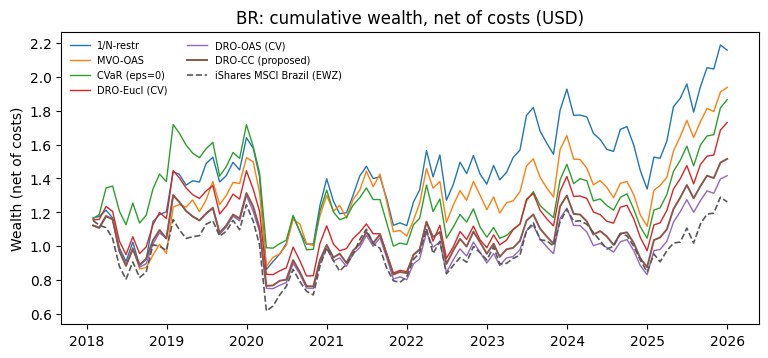

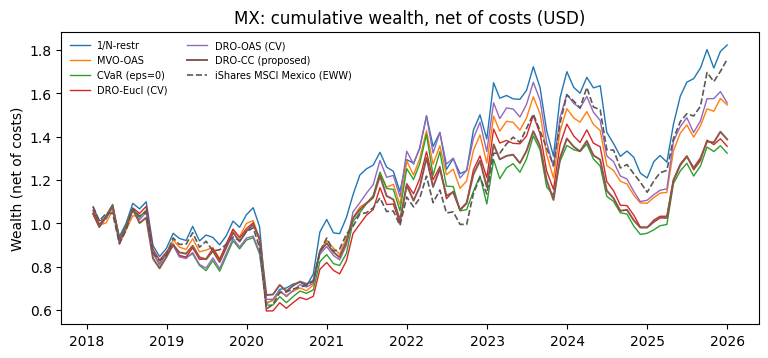

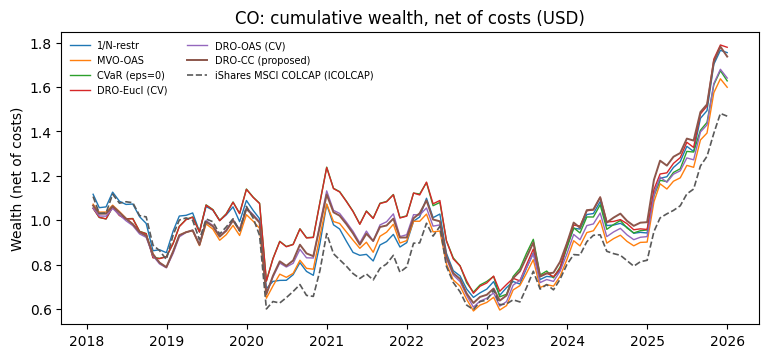

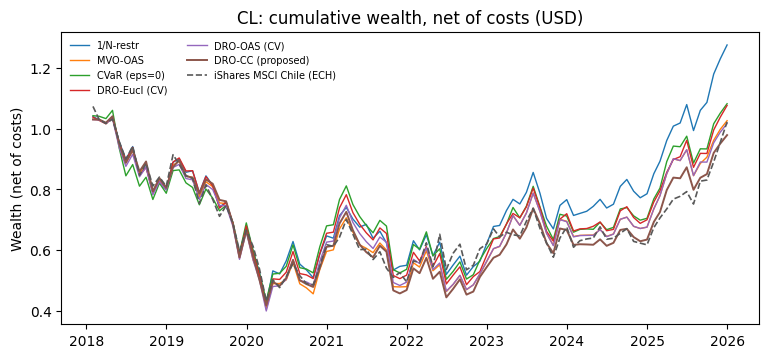

In [ ]:
def index_returns(c, start, end):
    # Monthly USD returns of the country ETF (EWZ, EWW, ECH already in USD; ICOLCAP in COP converted with COP=X)
    s_idx = load_reference_index(c, start, end)
    if s_idx is None: return None
    s_idx = to_month_end(s_idx)
    if MARKET_META[c].get('index_ccy', 'LOCAL') != 'USD':
        s_idx = s_idx / FX[MARKET_META[c]['fx']].reindex(s_idx.index)
    return s_idx.pct_change(fill_method=None).rename(INDEX_META[c][0])

def index_table(RES_, IDX_R_, start=None):
    rows = {}
    for c, r in RES_.items():
        ri = IDX_R_.get(c)
        if ri is None: continue
        dates = r['paths']['MVO-OAS'].loc[start:].index; ri = ri.reindex(dates)
        if ri.isna().any(): print(f'  [{c}] {INDEX_META[c][0]}: {int(ri.isna().sum())} months without data in the evaluation.')
        if ri.notna().sum() < 12: continue
        m = perf_metrics(ri.dropna(), RF, PARAMS['ALPHA']); m['Return type'] = INDEX_META[c][1]
        rows[(c, INDEX_META[c][0])] = m
    return pd.DataFrame(rows).T

IDX_R = {c: index_returns(c, START, END) for c in MARKET_META}
RES = {}
for c, md_ in MARKETS.items():
    print(f'=== {c} ==='); RES[c] = run_market(md_, PARAMS, verbose=False)
PERF = pd.concat({c: summarize(r, MARKETS[c]['rf']) for c, r in RES.items()})
display(PERF.round(3))
IDX_PERF = index_table(RES, IDX_R)
print('Country ETFs in USD (external reference; they do not satisfy the climate constraints):'); display(IDX_PERF)
for c in RES: fig_wealth(RES[c], f'{c}: cumulative wealth, net of costs (USD)', f'wealth_{c}.png',
                         index_r=IDX_R.get(c), index_label=INDEX_META[c][0])
print('Solver:', dict(SOLVER_STATS))

### F2. Weights, feasible set, selected radius and penalty regime
In addition to the mean weights and the feasible set, the notebook reports: the distribution of the selected radius and the frequency at the end of the grid; the share of the Wasserstein penalty in the objective at the selected radius (§7); the slope of the validation curve (relative difference between the best and the worst $\varepsilon$), which indicates whether the selection is informative; the frequency with which each constraint is active; and the diagnostics of the nominal measure (ESS, correlation of the weights with recency, share of the climate block in the metric).

,1/N-restr,MVO-OAS,CVaR (eps=0),DRO-Eucl (CV),DRO-OAS (CV),DRO-CC (proposed)
PETR4.SA,0.0001,0.0000,0.0000,0.0000,0.0000,0.0000
VALE3.SA,0.0083,0.0000,0.0000,0.0001,0.0000,0.0000
ITUB4.SA,0.1219,0.1295,0.3079,0.2508,0.2255,0.1939
BBDC4.SA,0.1279,0.0130,0.0694,0.0922,0.0249,0.0296
CPFE3.SA,0.0894,0.1309,0.1543,0.1178,0.1351,0.1657
CMIG4.SA,0.1025,0.0000,0.0000,0.0231,0.0000,0.0000
CSNA3.SA,0.0010,0.0000,0.0000,0.0000,0.0000,0.0000
WEGE3.SA,0.0399,0.0007,0.0000,0.0106,0.0000,0.0000
SUZB3.SA,0.0317,0.0882,0.1336,0.1099,0.1139,0.1052
GGBR4.SA,0.0010,0.0000,0.0000,0.0000,0.0000,0.0000


,1/N-restr,MVO-OAS,CVaR (eps=0),DRO-Eucl (CV),DRO-OAS (CV),DRO-CC (proposed)
FEMSAUBD.MX,0.0288,0.0027,0.0000,0.0096,0.0000,0.0000
GMEXICOB.MX,0.0000,0.0000,0.0034,0.0040,0.0050,0.0054
WALMEX.MX,0.1357,0.2880,0.3402,0.2892,0.3400,0.3330
GAPB.MX,0.1203,0.1082,0.0327,0.0591,0.0503,0.0752
AMXB.MX,0.1071,0.1961,0.2497,0.1719,0.2220,0.2400
RA.MX,0.1666,0.0801,0.0458,0.1124,0.0488,0.0546
GRUMAB.MX,0.0193,0.0228,0.0026,0.0071,0.0037,0.0141
KIMBERA.MX,0.0320,0.0020,0.0006,0.0124,0.0010,0.0020
CEMEXCPO.MX,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
GFNORTEO.MX,0.1666,0.1102,0.1171,0.1068,0.1175,0.1045


,1/N-restr,MVO-OAS,CVaR (eps=0),DRO-Eucl (CV),DRO-OAS (CV),DRO-CC (proposed)
ECOPETROL.CL,0.0015,0.0000,0.0000,0.0000,0.0000,0.0000
PFCIBEST.CL,0.1334,0.0022,0.0152,0.0632,0.0020,0.0012
PFGRUPOARG.CL,0.0120,0.0000,0.0000,0.0006,0.0000,0.0000
NUTRESA.CL,0.0431,0.0407,0.0250,0.0266,0.0445,0.0410
CELSIA.CL,0.1013,0.0509,0.0905,0.0932,0.0562,0.1031
GRUPOSURA.CL,0.0502,0.0312,0.0000,0.0006,0.0059,0.0053
TERPEL.CL,0.0666,0.1001,0.0673,0.0746,0.0919,0.0811
GEB.CL,0.1239,0.3116,0.3211,0.2566,0.3136,0.3063
CEMARGOS.CL,0.0039,0.0000,0.0089,0.0086,0.0004,0.0001
PFDAVVNDA.CL,0.1324,0.0160,0.0095,0.0629,0.0143,0.0127


,1/N-restr,MVO-OAS,CVaR (eps=0),DRO-Eucl (CV),DRO-OAS (CV),DRO-CC (proposed)
SQM-B.SN,0.0032,0.0000,0.0159,0.0046,0.0000,0.0000
BSANTANDER.SN,0.1640,0.3082,0.3248,0.2207,0.3002,0.3203
COPEC.SN,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
FALABELLA.SN,0.1476,0.0252,0.0015,0.0930,0.0239,0.0129
CENCOSUD.SN,0.1477,0.1409,0.1849,0.1697,0.1721,0.1484
CMPC.SN,0.0151,0.0215,0.0475,0.0419,0.0421,0.0542
COLBUN.SN,0.1623,0.2191,0.1806,0.1790,0.2042,0.1998
CCU.SN,0.0398,0.0800,0.0104,0.0288,0.0528,0.0351
LTM.SN,0.0000,0.0000,0.0033,0.0000,0.0000,0.0000
ENTEL.SN,0.1388,0.0239,0.0495,0.1020,0.0285,0.0517


BR | maximum feasible Neff at the start of the evaluation = 11.5
MX | maximum feasible Neff at the start of the evaluation = 10.21
CO | maximum feasible Neff at the start of the evaluation = 10.76
CL | maximum feasible Neff at the start of the evaluation = 9.07


,N_assets,n_library,lim_CI,lim_PHYS,Neff_max,n_w>=25%
BR,15.00,94.5,0.137,0.158,9.516,8.875
CL,13.00,94.5,0.111,0.289,7.458,7.156
CO,11.75,86.5,0.124,0.099,8.645,7.312
MX,14.00,94.5,0.129,0.320,7.885,8.188


... (12 outputs left out)

Mean turnover per rebalancing after the annual re-estimation of PHYS against the rest:


after re-estimation (January)   rest
BR DRO-CC (proposed)                          0.534  0.311
   MVO-OAS                                    0.439  0.194
   1/N-restr                                  0.235  0.168
MX DRO-CC (proposed)                          0.483  0.372
   MVO-OAS                                    0.399  0.198
   1/N-restr                                  0.199  0.156
CO DRO-CC (proposed)                          0.457  0.221
   MVO-OAS                                    0.501  0.163
   1/N-restr                                  0.250  0.113
CL DRO-CC (proposed)                          0.370  0.260
   MVO-OAS                                    0.177  0.150
   1/N-restr                                  0.101  0.084

Solver status by radius (all solves, including validation):


status,optimal
eps,
0.000,1265
0.010,1260
0.025,1260
0.050,1260
0.100,1260
0.200,1261
0.400,1260
0.800,1261
1.600,1261


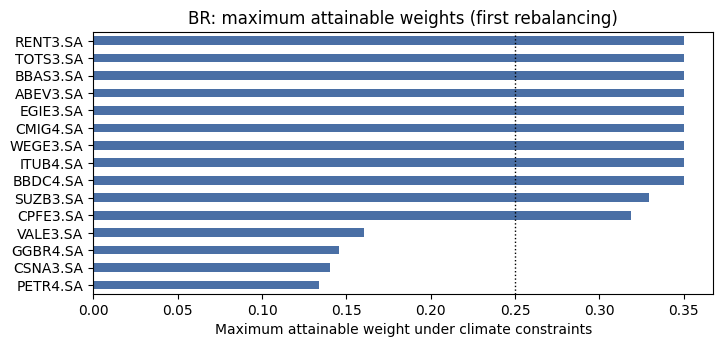

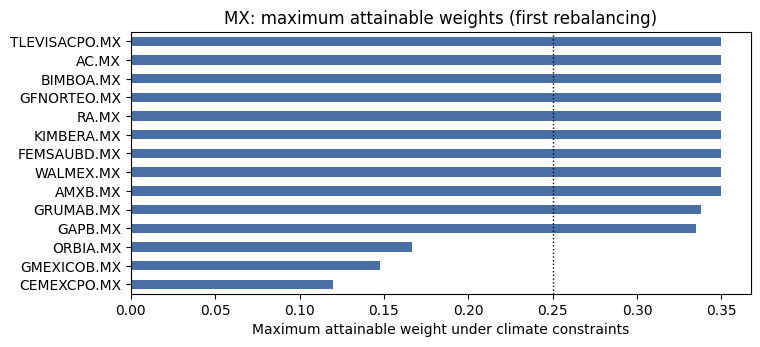

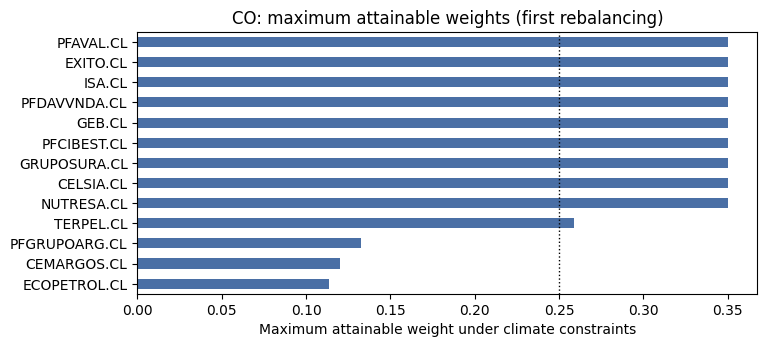

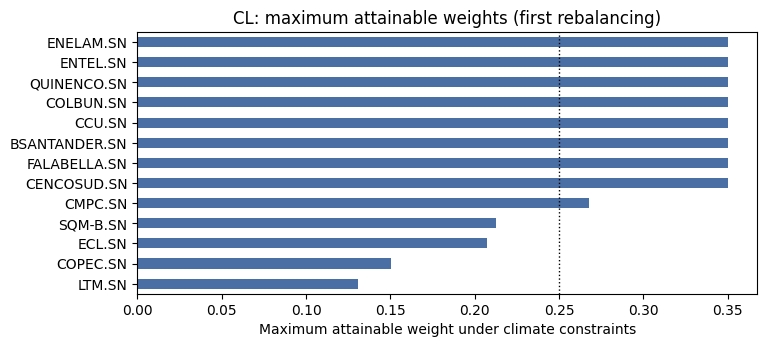

In [ ]:
AVGW = {c: average_weights(r) for c, r in RES.items()}
for c in AVGW: display(AVGW[c])
FEAS = {}
for c, md_ in MARKETS.items():
    chi = np.asarray(md_['chi']); n = chi.shape[1]
    lim = feasible_limits(chi, np.full(n, 1 / n), 0.0, PARAMS)
    FEAS[c], neff, _ = feasible_set_report(chi, lim, list(md_['R'].columns), PARAMS['W_MAX'])
    print(c, '| maximum feasible Neff at the start of the evaluation =', round(neff, 2))
    fig_feasible(FEAS[c], f'{c}: maximum attainable weights (first rebalancing)', f'feasible_{c}.png')
display(pd.concat({c: r['diag'] for c, r in RES.items()}).groupby(level=0).mean(numeric_only=True).round(3))

# Selected radius, upper end of the grid, penalty regime and slope of the validation curve
EPS_SUM = {}
for c, r in RES.items():
    sl = r['solve_log']
    for s, ser in r['eps_choice'].items():
        kind = CV_KIND[s]
        pen = [sl[(sl.date == t) & (sl.kind == kind) & (sl.eps == e)].eval('penalty / obj').iloc[0] for t, e in ser.items()]
        curves = [r['cv_curves'][(kind, t)] for t in ser.index if (kind, t) in r['cv_curves']]
        slope = [(cv.max() - cv.min()) / abs(cv.min()) for cv in curves]
        EPS_SUM[(c, s)] = {'median eps': ser.median(), 'mean eps': ser.mean(),
                           'at the upper end (%)': 100 * (ser >= max(PARAMS['EPS_GRID'])).mean(),
                           'at eps = 0 (%)': 100 * (ser == 0).mean(),
                           'penalty share (mean)': np.nanmean(pen),
                           'relative slope of the CV curve (median)': np.median(slope) if slope else np.nan}
print('Radius selected by cross-validation and penalty regime:'); display(pd.DataFrame(EPS_SUM).T.round(3))

# Active constraints
BITE = pd.concat({c: r['bite'].groupby('strategy')[['active_CI', 'active_PHYS', 'active_cap']].mean() * 100
                  for c, r in RES.items()})
print('Percentage of rebalancings with each constraint active:'); display(BITE.round(1))
print('Relaxations of the feasible set:'); display(pd.concat({c: r['relaxations'] for c, r in RES.items()}))
print('Dates with the physical limit bounded to the feasible range:')
display(pd.DataFrame({c: {'dates': len(r['phys_bounded']),
                          'first': r['phys_bounded']['date'].min() if len(r['phys_bounded']) else None,
                          'last': r['phys_bounded']['date'].max() if len(r['phys_bounded']) else None}
                      for c, r in RES.items()}).T)
print('Maximum mean weight by strategy (<= W_MAX except cap relaxations):')
display(pd.concat({c: average_weights(r).max() for c, r in RES.items()}, axis=1).round(3))

# Nominal measure and metric of the proposed model
print('Nominal measure and metric of DRO-CC at the rebalancing dates (summary):')
display(pd.concat({c: r['kernel'].astype(float).describe().loc[['mean', 'min', '50%', 'max']] for c, r in RES.items()}).round(3))

# Turnover after the annual re-estimation of PHYS against the rest
_rot = {}
for c, r in RES.items():
    for s_ in ['DRO-CC (proposed)', 'MVO-OAS', '1/N-restr']:
        tv = r['paths'][s_]['turnover']; tv = tv[tv > 0].iloc[1:]
        _rot[(c, s_)] = {'after re-estimation (January)': tv[tv.index.month == 1].mean(), 'rest': tv[tv.index.month != 1].mean()}
print('Mean turnover per rebalancing after the annual re-estimation of PHYS against the rest:'); display(pd.DataFrame(_rot).T.round(3))
SOLVES = pd.concat({c: r['solve_log'] for c, r in RES.items()})
print('Solver status by radius (all solves, including validation):')
display(SOLVES.groupby(['eps', 'status']).size().unstack(fill_value=0))

### F3. Inference by market and panel
Convention: $\Delta$ = DRO-CC minus the benchmark. The bootstrap block is chosen automatically for each comparison (§9); the sensitivity table reports the intervals with fixed blocks.

In [ ]:
REFS = ['MVO-OAS', 'DRO-OAS (CV)', 'CVaR (eps=0)', '1/N-restr', 'Country ETF']

def inference_table(RES_, IDX_R_, start=None, A='DRO-CC (proposed)', refs=REFS, P_=PARAMS):
    INF_ = {}
    for c, r in RES_.items():
        a = r['paths'][A]['net'].loc[start:]
        for b_name in refs:
            if b_name == 'Country ETF':
                if IDX_R_.get(c) is None: continue
                b = IDX_R_[c].reindex(a.index)
                if b.isna().any(): print(f'  [{c}] ETF with {int(b.isna().sum())} missing months; skipped.'); continue
            else:
                b = r['paths'][b_name]['net'].reindex(a.index)
            bt = bootstrap_differences(a.values, b.values, RF.reindex(a.index).values,
                                       B=P_['BOOT_B'], block=P_['BOOT_BLOCK'], alpha=P_['ALPHA'])
            dm = dm_hln(downside_loss(a.values), downside_loss(b.values))
            row = {f'{i} | {j}': bt.loc[i, j] for i in bt.index
                   for j in ['estimate', 'IC95_inf', 'IC95_sup', 'p_A_better', 'p_two_sided']}
            row['block'] = int(bt['block'].iloc[0])
            row.update({f'DM | {k}': v for k, v in dm.items()})
            INF_[(c, b_name)] = row
    INF_ = pd.DataFrame.from_dict(INF_, orient='index')
    for k in ['Delta CVaR', 'Delta Sharpe', 'DM']:          # Holm by family (markets x benchmarks)
        INF_[f'{k} | p_two_sided_Holm'] = holm_adjust(INF_[f'{k} | p_two_sided'].values)
    return INF_

INF = inference_table(RES, IDX_R)
print('Convention: Delta = DRO-CC minus benchmark. p_A_better = one-sided p in favour of DRO-CC. Holm over', len(INF),
      'comparisons. CI of Delta MaxDD descriptive only.')
display(INF.round(4))
POOL = pd.concat([pooled_bootstrap(RES, 'DRO-CC (proposed)', b) for b in ['MVO-OAS', 'DRO-OAS (CV)', '1/N-restr']], axis=1).T
print('Panel of the four markets:'); display(POOL.round(4))
BLOCKS = pd.concat({(c, b): block_sensitivity(r['paths']['DRO-CC (proposed)']['net'].values,
                                              r['paths'][b]['net'].values, RF.reindex(r['paths'][b].index).values,
                                              PARAMS['BOOT_BLOCK_SENS'], PARAMS['BOOT_B'], PARAMS['ALPHA'])
                    for c, r in RES.items() for b in ['DRO-OAS (CV)', 'MVO-OAS']})
print('Sensitivity of the intervals to the bootstrap block:'); display(BLOCKS.round(4))

Convention: Delta = DRO-CC minus benchmark. p_A_better = one-sided p in favour of DRO-CC. Holm over 20 comparisons. CI of Delta MaxDD descriptive only.


Delta CVaR | estimate  Delta CVaR | IC95_inf  Delta CVaR | IC95_sup  Delta CVaR | p_A_better  Delta CVaR | p_two_sided  Delta Sharpe | estimate  Delta Sharpe | IC95_inf  \
BR MVO-OAS                     -0.0093                -0.0249                 0.0080                   0.1180                     0.236                  -0.1012                  -0.2751   
   DRO-OAS (CV)                -0.0029                -0.0149                 0.0053                   0.1720                     0.344                   0.0271                  -0.0172   
   CVaR (eps=0)                 0.0078                -0.0162                 0.0344                   0.6390                     0.722                  -0.0849                  -0.2873   
   1/N-restr                   -0.0164                -0.0534                 0.0127                   0.2510                     0.502                  -0.1453                  -0.3302   
   Country ETF                 -0.0194                -0.0550                 0.0139                   0.1655                     0.331                   0.0613                  -0.1949   
MX MVO-OAS                     -0.0084                -0.0223                 0.0021                   0.0770                     0.154                  -0.0529                  -0.1790   
   DRO-OAS (CV)                 0.0039                -0.0089                 0.0193                   0.6415                     0.717                  -0.0518                  -0.1526   
   CVaR (eps=0)                -0.0065                -0.0231                 0.0074                   0.2020                     0.404                   0.0195                  -0.1169   
   1/N-restr                   -0.0168                -0.0529                 0.0116                   0.1935                     0.387                  -0.1297                  -0.3437   
   Country ETF                 -0.0025                -0.0274                 0.0245                   0.4975                     0.995                  -0.1171                  -0.3680   
CO MVO-OAS                      0.0041                -0.0145                 0.0198                   0.8440                     0.312                   0.0406                  -0.0341   
   DRO-OAS (CV)                 0.0022                -0.0153                 0.0205                   0.6980                     0.604                   0.0283                  -0.0276   
   CVaR (eps=0)                -0.0101                -0.0312                 0.0116                   0.1095                     0.219                   0.0310                  -0.0873   
   1/N-restr                   -0.0006                -0.0254                 0.0262                   0.5230                     0.954                  -0.0021                  -0.2025   
   Country ETF                 -0.0039                -0.0435                 0.0365                   0.3760                     0.752                   0.0774                  -0.2054   
CL MVO-OAS                     -0.0091                -0.0242                 0.0101                   0.2510                     0.502                  -0.0249                  -0.0759   
   DRO-OAS (CV)                -0.0092                -0.0223                 0.0056                   0.1590                     0.318                  -0.0223                  -0.0897   
   CVaR (eps=0)                 0.0017                -0.0088                 0.0104                   0.5660                     0.868                  -0.0488                  -0.1566   
   1/N-restr                    0.0101                -0.0177                 0.0416                   0.7045                     0.591                  -0.1209                  -0.2793   
   Country ETF                  0.0135                -0.0187                 0.0575                   0.7455                     0.509                  -0.0164                  -0.2816   

                 Delta Sharpe | IC95_sup  Delta

Panel of the four markets:


,Delta CVaR panel,IC95_inf,IC95_sup,p_A_better (Delta<0),p_two_sided,block,T months,N stacked obs.
DRO-CC (proposed) vs MVO-OAS,-0.0053,-0.0176,0.0038,0.212,0.424,4.0,96.0,384.0
DRO-CC (proposed) vs DRO-OAS (CV),-0.0003,-0.0055,0.0045,0.360,0.720,6.0,96.0,384.0
DRO-CC (proposed) vs 1/N-restr,-0.0038,-0.0180,0.0071,0.229,0.458,30.0,96.0,384.0


Sensitivity of the intervals to the bootstrap block:


Delta CVaR | IC95_inf  Delta CVaR | IC95_sup  Delta CVaR | p_two_sided  Delta Sharpe | IC95_inf  Delta Sharpe | IC95_sup  Delta Sharpe | p_two_sided
BR DRO-OAS (CV) block 3 (auto)                 -0.0149                 0.0053                     0.344                  -0.0172                   0.0733                       0.215
                block 3                        -0.0149                 0.0053                     0.344                  -0.0172                   0.0733                       0.215
                block 6                        -0.0135                 0.0063                     0.320                  -0.0103                   0.0637                       0.181
                block 12                       -0.0125                 0.0058                     0.262                  -0.0037                   0.0576                       0.074
   MVO-OAS      block 7 (auto)                 -0.0249                 0.0080                     0.236                  -0.2751                   0.0535                       0.205
                block 3                        -0.0286                 0.0088                     0.227                  -0.2797                   0.0508                       0.207
                block 6                        -0.0261                 0.0076                     0.209                  -0.2835                   0.0450                       0.212
                block 12                       -0.0267                 0.0055                     0.189                  -0.2706                   0.0447                       0.242
MX DRO-OAS (CV) block 2 (auto)                 -0.0089                 0.0193                     0.717                  -0.1526                   0.0657                       0.366
                block 3                        -0.0090                 0.0193                     0.722                  -0.1541                   0.0578                       0.384
                block 6                        -0.0090                 0.0193                     0.694                  -0.1584                   0.0674                       0.478
                block 12                       -0.0091                 0.0183                     0.707                  -0.1703                   0.0652                       0.495
   MVO-OAS      block 2 (auto)                 -0.0223                 0.0021                     0.154                  -0.1790                   0.0568                       0.355
                block 3                        -0.0221                 0.0022                     0.160                  -0.1764                   0.0474                       0.340
                block 6                        -0.0221                 0.0018                     0.147                  -0.1578                   0.0396                       0.271
                block 12                       -0.0216                 0.0018                     0.121                  -0.1417                   0.0303                       0.236
CO DRO-OAS (CV) block 3 (auto)                 -0.0153                 0.0205                     0.604                  -0.0276                   0.0978                       0.340
                block 3                        -0.0153                 0.0205                     0.604                  -0.0276                   0.0978                       0.340
                block 6                        -0.0136                 0.0211                     0.567                  -0.0239                   0.0882                       0.289
                block 12                       -0.0131                 0.0168                     0.519                  -0.0173                   0.0817                       0.245
   MVO-OAS      block 3 (auto)                 -0.0145                 0.0198                     0.312                  -0.0341                   0.1295                       0.252
                block 3      

### F4. Ablations, CVaR–$\varepsilon$ frontier and alternative specifications of the physical exposure
This is the most expensive section (see the running times in the introduction). With `RUN_F4 = False` it can be skipped and run later without repeating the previous cells. The ablations and the alternative PHYS specifications use a coarse radius grid, so their base rows do not coincide exactly with F1. The DRO-CC row "No climate ($\omega=0$, $\kappa=0$)" reproduces DRO-OAS with that grid and serves as a check of the nesting.

In [ ]:
RUN_F4 = True
if RUN_F4:
  ABL = {c: run_ablations(MARKETS[c]) for c in MARKETS}
  for c in ABL: print(c); display(ABL[c].round(3))
  FRONT = {c: eps_frontier(MARKETS[c]) for c in MARKETS}
  for c in FRONT:
      display(FRONT[c].round(3)); fig_eps_frontier(FRONT[c], f'{c}: out-of-sample CVaR vs fixed radius', f'eps_frontier_{c}.png')
  # Alternative specifications of the physical exposure (each with its own expanding path)
  ALT_SPECS = {'ENSO with 6 lags': {'enso_lags': 6}, 'ENSO without market control': {'market_control': False},
               'Water risk only (kappa = 0)': {'kappa': 0.0}, 'Headquarters rule for H issuers': {'hq_rule': 'hq'}}
  _S4 = ['MVO-OAS', 'DRO-OAS (CV)', 'DRO-CC (proposed)', '1/N-restr']; ALT = {}
  P_ALT = dict(PARAMS, EPS_GRID=ABLATION_EPS_GRID)          # coarse grid, as in the ablations
  for lab, sp in ALT_SPECS.items():
      path_, _ = build_phys_path(R_USD, MEI, AQ, EST_DATES, PARAMS['PRICE_START'], spec=dict(PHYS_SPEC_MAIN, **sp),
                                 min_obs=PARAMS['ENSO_MIN_OBS'])
      mk_ = build_markets('PHYS_data', phys_path=path_, verbose=False)
      ALT[lab] = pd.concat({c: summarize(run_market(m_, P_ALT, strategies=_S4, verbose=False), m_['rf'])
                            for c, m_ in mk_.items()})
  ALT['Full expert prior (CI and PHYS)'] = pd.concat({c: summarize(run_market(m_, P_ALT, strategies=_S4, verbose=False),
                                                                      m_['rf']) for c, m_ in MARKETS_PRIOR.items()})
  ALT = pd.concat(ALT); display(ALT.round(3))

  Note: physical limit bounded to the feasible range on 26 dates (rebalancing or validation) | first 2020-12-31, last 2025-08-31
  Note: physical limit bounded to the feasible range on 71 dates (rebalancing or validation) | first 2018-05-31, last 2025-09-30
  Note: physical limit bounded to the feasible range on 58 dates (rebalancing or validation) | first 2018-05-31, last 2025-09-30
  Note: physical limit bounded to the feasible range on 106 dates (rebalancing or validation) | first 2016-12-31, last 2025-09-30
  Note: physical limit bounded to the feasible range on 20 dates (rebalancing or validation) | first 2020-12-31, last 2022-11-30
  Note: physical limit bounded to the feasible range on 59 dates (rebalancing or validation) | first 2019-12-31, last 2025-09-30
  Note: physical limit bounded to the feasible range on 3 dates (rebalancing or validation) | first 2024-01-31, last 2025-08-31
  Note: physical limit bounded to the feasible range on 3 dates (rebalancing or validation) | fir

Annual geom. ret. (%)  Annual vol. (%)  Sharpe (annual)  CVaR5% monthly (%)  CVaR10% monthly (%)  MaxDD (%)  N months  \
Specification                              Strategy                                                                                                                                   
Base                                       MVO-OAS                            8.621           31.507            0.343              18.738               14.596    -42.181        96   
                                           DRO-CC (proposed)                  5.155           30.610            0.237              17.803               13.848    -42.390        96   
                                           1/N-restr                         10.089           32.826            0.387              19.446               14.629    -47.399        96   
CTB (30% reduction)                        MVO-OAS                            9.355           29.920            0.367              17.294               13.860    -40.192        96   
                                           DRO-CC (proposed)                  6.856           29.499            0.288              16.951               13.516    -39.130        96   
                                           1/N-restr                         10.493           31.979            0.401              19.224               14.586    -47.496        96   
70% reduction, 5% per year, no cap         MVO-OAS                            8.606           33.631            0.341              19.768               15.028    -42.506        96   
                                           DRO-CC (proposed)                  4.934           33.558            0.236              19.339               15.462    -41.788        96   
                                           1/N-restr                          9.772           35.416            0.376              20.943               15.616    -49.887        96   
PHYS -15% relative to the benchmark        MVO-OAS                            5.336           32.915            0.249              20.328               15.612    -45.986        96   
                                           DRO-CC (proposed)                  3.723           32.443            0.199              19.445               15.232    -44.082        96   
                                           1/N-restr                          6.425           34.665            0.285              20.505               15.855    -49.501        96   
PHYS -30% relative to the benchmark        MVO-OAS                            1.810           34.754            0.157              21.200               16.807    -53.794        96   
                                           DRO-CC (proposed)                  1.538           34.842            0.149              21.076               16.725    -55.544        96   
                                           1/N-restr                          3.262           36.043            0.202              20.912               16.553    -52.947        96   
No position cap                            MVO-OAS                            8.559           31.672            0.340              18.545               14.677    -41.371        96   
                                           DRO-CC (proposed)                  6.452           31.796            0.277              19.004               14.594    -41.548        96   
                                           1/N-restr                         10.089           32.826            0.387              19.446               14.629    -47.399        96   
No climate kernel (omega = 0)              MVO-OAS                            8.621           31.507            0.343              18.738               14.596    -42.181        96   
                                           DRO-CC (proposed)                  5.347           30.538            0.242              17.862               13.848    -42.420        96   
                                    

MX


Annual geom. ret. (%)  Annual vol. (%)  Sharpe (annual)  CVaR5% monthly (%)  CVaR10% monthly (%)  MaxDD (%)  N months  \
Specification                              Strategy                                                                                                                                   
Base                                       MVO-OAS                            5.603           27.375            0.248              17.650               13.471    -40.043        96   
                                           DRO-CC (proposed)                  3.753           26.740            0.180              17.349               13.193    -39.979        96   
                                           1/N-restr                          7.801           28.398            0.325              18.481               13.776    -42.702        96   
CTB (30% reduction)                        MVO-OAS                            4.104           24.822            0.188              16.766               12.427    -38.685        96   
                                           DRO-CC (proposed)                  2.668           25.170            0.134              16.805               12.788    -40.814        96   
                                           1/N-restr                          7.860           26.511            0.329              17.590               12.959    -41.091        96   
70% reduction, 5% per year, no cap         MVO-OAS                            6.836           29.688            0.294              19.058               14.069    -43.943        96   
                                           DRO-CC (proposed)                  5.853           27.511            0.258              18.043               13.412    -44.377        96   
                                           1/N-restr                          8.244           31.437            0.339              20.300               14.893    -47.703        96   
PHYS -15% relative to the benchmark        MVO-OAS                            4.935           27.790            0.225              18.185               13.684    -36.124        96   
                                           DRO-CC (proposed)                  4.611           27.454            0.214              18.265               13.767    -38.067        96   
                                           1/N-restr                          6.869           28.845            0.293              18.620               13.911    -39.902        96   
PHYS -30% relative to the benchmark        MVO-OAS                            5.186           27.690            0.233              18.016               13.599    -36.124        96   
                                           DRO-CC (proposed)                  5.317           27.263            0.238              18.006               13.638    -36.335        96   
                                           1/N-restr                          6.801           28.886            0.291              18.717               13.959    -40.512        96   
No position cap                            MVO-OAS                            3.990           26.890            0.191              17.470               13.275    -40.043        96   
                                           DRO-CC (proposed)                  5.731           26.438            0.250              16.665               12.972    -36.055        96   
                                           1/N-restr                          7.801           28.398            0.325              18.481               13.776    -42.702        96   
No climate kernel (omega = 0)              MVO-OAS                            5.603           27.375            0.248              17.650               13.471    -40.043        96   
                                           DRO-CC (proposed)                  5.753           26.979            0.249              16.435               12.881    -39.615        96   
                                    

CO


Annual geom. ret. (%)  Annual vol. (%)  Sharpe (annual)  CVaR5% monthly (%)  CVaR10% monthly (%)  MaxDD (%)  N months  \
Specification                              Strategy                                                                                                                                   
Base                                       MVO-OAS                            6.042           26.100            0.265              16.534               12.540    -44.854        96   
                                           DRO-CC (proposed)                  7.109           26.181            0.304              16.937               12.659    -43.783        96   
                                           1/N-restr                          7.284           26.612            0.308              16.998               12.739    -42.049        96   
CTB (30% reduction)                        MVO-OAS                            6.597           25.459            0.287              16.546               12.357    -46.125        96   
                                           DRO-CC (proposed)                  6.647           25.421            0.289              16.964               12.380    -46.538        96   
                                           1/N-restr                          7.233           26.681            0.306              17.066               12.783    -44.181        96   
70% reduction, 5% per year, no cap         MVO-OAS                            6.246           27.876            0.273              18.063               13.520    -46.473        96   
                                           DRO-CC (proposed)                  4.305           28.328            0.208              18.695               13.895    -50.842        96   
                                           1/N-restr                          7.124           27.618            0.300              17.260               13.073    -40.984        96   
PHYS -15% relative to the benchmark        MVO-OAS                            4.956           26.803            0.228              17.199               12.781    -45.124        96   
                                           DRO-CC (proposed)                  5.467           27.009            0.246              17.635               12.854    -44.907        96   
                                           1/N-restr                          6.823           27.664            0.292              17.786               13.202    -43.076        96   
PHYS -30% relative to the benchmark        MVO-OAS                            5.687           28.262            0.255              17.894               13.279    -45.026        96   
                                           DRO-CC (proposed)                  5.436           28.081            0.247              18.233               13.297    -46.093        96   
                                           1/N-restr                          7.255           28.829            0.307              18.713               13.727    -43.816        96   
No position cap                            MVO-OAS                            4.376           26.864            0.208              18.210               13.450    -48.313        96   
                                           DRO-CC (proposed)                  3.773           27.129            0.186              18.419               13.637    -50.332        96   
                                           1/N-restr                          7.284           26.612            0.308              16.998               12.739    -42.048        96   
No climate kernel (omega = 0)              MVO-OAS                            6.042           26.100            0.265              16.534               12.540    -44.854        96   
                                           DRO-CC (proposed)                  6.993           26.135            0.300              16.884               12.649    -44.213        96   
                                    

CL


Annual geom. ret. (%)  Annual vol. (%)  Sharpe (annual)  CVaR5% monthly (%)  CVaR10% monthly (%)  MaxDD (%)  N months  \
Specification                              Strategy                                                                                                                                   
Base                                       MVO-OAS                            0.320           27.866            0.062              17.583               14.106    -60.776        96   
                                           DRO-CC (proposed)                 -0.470           27.454            0.030              17.003               14.255    -60.597        96   
                                           1/N-restr                          3.081           27.829            0.158              15.658               13.369    -59.257        96   
CTB (30% reduction)                        MVO-OAS                           -0.492           26.807            0.022              15.771               13.118    -59.522        96   
                                           DRO-CC (proposed)                 -1.838           26.777           -0.028              16.047               13.546    -59.396        96   
                                           1/N-restr                          2.439           27.051            0.131              14.644               12.705    -58.126        96   
70% reduction, 5% per year, no cap         MVO-OAS                            2.610           29.341            0.150              18.044               14.582    -60.326        96   
                                           DRO-CC (proposed)                  2.494           29.420            0.146              17.390               14.428    -57.464        96   
                                           1/N-restr                          2.316           29.262            0.139              17.249               14.388    -61.276        96   
PHYS -15% relative to the benchmark        MVO-OAS                            1.533           27.849            0.104              15.865               12.920    -59.431        96   
                                           DRO-CC (proposed)                  1.884           28.083            0.117              15.324               12.916    -60.678        96   
                                           1/N-restr                          3.126           27.905            0.159              14.992               12.711    -58.228        96   
PHYS -30% relative to the benchmark        MVO-OAS                            3.383           28.310            0.170              15.158               12.920    -56.320        96   
                                           DRO-CC (proposed)                  2.362           28.547            0.137              15.924               13.506    -57.714        96   
                                           1/N-restr                          4.253           28.588            0.200              15.075               12.836    -55.414        96   
No position cap                            MVO-OAS                            0.901           28.131            0.084              17.347               13.900    -60.776        96   
                                           DRO-CC (proposed)                 -1.991           28.232           -0.017              17.591               14.422    -61.641        96   
                                           1/N-restr                          3.081           27.829            0.158              15.658               13.369    -59.257        96   
No climate kernel (omega = 0)              MVO-OAS                            0.320           27.866            0.062              17.583               14.106    -60.776        96   
                                           DRO-CC (proposed)                 -0.833           27.805            0.020              17.478               14.445    -60.796        96   
                                    

### F5. State-space model: components, conditioning and Riccati convergence

In [ ]:
print('Annual estimates of the state-space model in the backtest (components, conditioning and stability):')
display(pd.concat({c: r['state_log'].set_index('estimate') for c, r in RES.items()}).round(3))
fig, ax = plt.subplots(figsize=(7, 3.2)); RICCATI = {}
for c, md_ in MARKETS.items():
    Zt_ = transform_state(md_['Z_raw'].loc[PARAMS['CLIMATE_START']:]); Zt_ = Zt_.loc[Zt_.dropna(how='all').index]
    m_ = fit_climate_state(Zt_, month_shift(PARAMS['IS_END'], PARAMS['PUB_LAG']), PARAMS['STATE_TOL'])
    tr = riccati_report(m_, len(Zt_.loc[:PARAMS['IS_END']]))
    conv = int(np.argmax(np.abs(tr - tr[-1]) / tr[-1] < 0.01)) + 1
    RICCATI[c] = {'rho(Phi)': m_['rho'], 'initial tr(P)': tr[0], 'stationary tr(P)': tr[-1], 'months at 1%': conv}
    ax.plot(np.arange(1, len(tr) + 1), tr, label=c)
ax.set_xlabel('Month of the estimation sample'); ax.set_ylabel(r'tr$(P_{t|t})$'); ax.legend(frameon=False)
fig.savefig('riccati_trace.png', dpi=200, bbox_inches='tight')
display(pd.DataFrame(RICCATI).T.round(4))

### F6. Robustness: estimation 2014–2021, evaluation 2022–2025, fixed PHYS
Alternative design: PHYS is estimated once with the returns of 2014–2021 and evaluated over 2022–2025 (48 months). It is reported together with the main design restricted to the same 48 months, which separates the effect of the evaluation window from the effect of the way PHYS is estimated. With half the months, the intervals are about $\sqrt2\approx1.41$ times wider.

In [ ]:
RUN_F6 = True
if RUN_F6:
  P_ROB = dict(PARAMS, IS_END='2021-12-31', OOS_START='2022-01-01', PHYS_UPDATE='fixed')
  EXPO_ROB, _, _ = build_exposures(R_USD, MEI, AQ, is_start=PARAMS['PRICE_START'], is_end=P_ROB['IS_END'],
                                   spec=PHYS_SPEC_MAIN, min_obs=PARAMS['ENSO_MIN_OBS'])
  print('Spearman PHYS (2014-2021) vs PHYS (2014-2017):', round(EXPO_ROB['PHYS_data'].corr(EXPO['PHYS_data'], method='spearman'), 3))
  MARKETS_ROB = build_markets('PHYS_data', expo=EXPO_ROB, verbose=False)
  RES_ROB = {}
  for c, md_ in MARKETS_ROB.items():
      print(f'=== {c} (robustness) ==='); RES_ROB[c] = run_market(md_, P_ROB, verbose=False)
  PERF_ROB = pd.concat({c: summarize(r, MARKETS_ROB[c]['rf'], P_ROB) for c, r in RES_ROB.items()})
  print('Robustness design (estimation 2014-2021, evaluation 2022-2025):'); display(PERF_ROB.round(3))
  IDX_PERF_ROB = index_table(RES_ROB, IDX_R); display(IDX_PERF_ROB)
  PERF_MAIN_2225 = pd.concat({c: pd.DataFrame({s: perf_metrics(p['net'].loc['2022-01-01':], RF, PARAMS['ALPHA'])
                                               for s, p in r['paths'].items()}).T for c, r in RES.items()})
  print('Main design evaluated in 2022-2025:'); display(PERF_MAIN_2225.round(3))
  INF_ROB = inference_table(RES_ROB, IDX_R, P_=P_ROB)
  print('Inference of the robustness design (Holm over', len(INF_ROB), 'comparisons):'); display(INF_ROB.round(4))
  POOL_ROB = pd.concat([pooled_bootstrap(RES_ROB, 'DRO-CC (proposed)', b) for b in ['MVO-OAS', 'DRO-OAS (CV)']], axis=1).T
  display(POOL_ROB.round(4))
  for c in RES_ROB: fig_wealth(RES_ROB[c], f'{c}: cumulative wealth 2022-2025, robustness design (USD)', f'wealth_rob_{c}.png',
                               index_r=IDX_R.get(c), index_label=INDEX_META[c][0])

### F7. Absence of a detectable difference versus equivalence (TOST)
A confidence interval that contains zero does not show that two strategies are equivalent. Equivalence is tested with the two one-sided tests procedure (TOST; Schuirmann, 1987): for a margin $\delta>0$, $H_{01}:\Delta\le-\delta$ and $H_{02}:\Delta\ge\delta$ are both rejected at level $a$ when the $(1-2a)$ percentile interval of the bootstrap lies inside $(-\delta,\delta)$. The cell reports, for the panel and for each market, the 90% and 95% intervals of $\Delta\mathrm{CVaR}$, the TOST $p$-value for margins of 0.25, 0.50, 0.75 and 1.00 percentage points of monthly CVaR, and the equivalence bound $\delta^*_a=\max(|\text{lower}|,|\text{upper}|)$ of the $(1-2a)$ interval, the smallest margin for which equivalence is established at level $a$. The resampling is the same as in F3 (same seed, block and number of replications), so the 95% intervals coincide with those of F3.

In [ ]:
EQ_MARGINS = [0.0025, 0.005, 0.0075, 0.01]       # in return units: 0.25 to 1.00 percentage points of monthly CVaR

def equivalence_row(point, draws, margins=EQ_MARGINS):
    lo90, hi90 = np.percentile(draws, [5, 95]); lo95, hi95 = np.percentile(draws, [2.5, 97.5])
    row = {'Delta CVaR': point, 'IC90_inf': lo90, 'IC90_sup': hi90, 'IC95_inf': lo95, 'IC95_sup': hi95,
           'bound a=5% (max|IC90|)': max(abs(lo90), abs(hi90)), 'bound a=2.5% (max|IC95|)': max(abs(lo95), abs(hi95))}
    for d in margins:
        row[f'TOST p, margin {100 * d:.2f} pp'] = max((draws <= -d).mean(), (draws >= d).mean())
    return pd.Series(row)

EQ_PAIRS = ['DRO-OAS (CV)', 'MVO-OAS', '1/N-restr']
EQUIV = {}
for b in EQ_PAIRS:
    pt, dr = pooled_bootstrap(RES, 'DRO-CC (proposed)', b, return_draws=True)
    EQUIV[('Panel', b)] = equivalence_row(pt['Delta CVaR panel'], dr)
    assert np.isclose(pt['IC95_inf'], POOL.loc[f'DRO-CC (proposed) vs {b}', 'IC95_inf']), 'Resampling differs from F3.'
    for c, r in RES.items():
        a_ = r['paths']['DRO-CC (proposed)']['net']; b_ = r['paths'][b]['net'].reindex(a_.index)
        bt, drm = bootstrap_differences(a_.values, b_.values, RF.reindex(a_.index).values, B=PARAMS['BOOT_B'],
                                        block=PARAMS['BOOT_BLOCK'], alpha=PARAMS['ALPHA'], return_draws=True)
        EQUIV[(c, b)] = equivalence_row(bt.loc['Delta CVaR', 'estimate'], drm[:, 0])
EQUIV = pd.DataFrame(EQUIV).T
EQUIV.index.names = ['sample', 'benchmark']
print('Delta CVaR = DRO-CC minus benchmark (return units). Equivalence at level a is established for any margin above the bound.')
display((EQUIV * 100).round(2).assign(**{c: EQUIV[c].round(3) for c in EQUIV.columns if c.startswith('TOST')}))

### F8. Convergence of the EM algorithm and sensitivity of the climate innovations and of the portfolios
The state-space model is re-estimated at the end of each year with the information available at that date (40 estimations: 4 markets × 10 years). The cell (a) reports, for every estimation of the backtest, the stopping rule, the number of iterations, the iterations in which the spectral-radius projection was active and the decreases of the log-likelihood (the projected EM is not guaranteed to be monotone); (b) re-estimates every model with up to 2,000 iterations and a tolerance of $10^{-8}$ and reports the log-likelihood gained after iteration 200, together with the path $\ell_k$ of the capped estimations; (c) re-estimates every model under alternative initial conditions and spectral bounds and compares the filtered innovations and their EWMA covariance $\Lambda$ with those of the paper's specification; (d) reruns the DRO-CC strategy (cross-validated radius, full grid) under each alternative and reports the change in out-of-sample return, CVaR, the average distance between weights and the panel comparison with DRO-OAS. The other strategies do not use the state-space model and are not affected. `RUN_F8 = False` skips the section.

In [ ]:
RUN_F8 = True
EM_ALTERNATIVES = {
    'Paper (OLS init., rho<=0.97, 200 it.)': {},
    'Extended (2,000 it., tol 1e-8)': {'n_iter': 2000, 'tol': 1e-8},
    'rho <= 0.95': {'rho_max': 0.95},
    'rho <= 0.99': {'rho_max': 0.99},
    'rho <= 0.999 (practically unconstrained)': {'rho_max': 0.999},
    'Init. identity': {'init': 'identity'},
    'Init. signal (90% in Q)': {'init': 'signal'},
    'Init. noise (90% in R)': {'init': 'noise'},
}

def _zt(md_):
    Zt_ = transform_state(md_['Z_raw'].loc[PARAMS['CLIMATE_START']:]); return Zt_.loc[Zt_.dropna(how='all').index]

def _decreases(llp, tol=1e-8): return int((np.diff(llp) < -tol * (1 + np.abs(llp[:-1]))).sum())

if RUN_F8:
    # (a) Convergence of the estimations used in the backtest
    EM_CONV = []
    for c, r in RES.items():
        for Y, m in sorted(r['state_models'].items()):
            llp = m['ll_path']
            EM_CONV.append({'market': c, 'estimate': Y.year, 'iterations': m['n_iter'], 'converged': m['converged'],
                            'projection active (it.)': m['n_projections'], 'rho(Phi)': m['rho'], 'cond(Q)': m['cond_Q'],
                            'log-lik.': llp[-1], 'decreases': _decreases(llp),
                            'rel. change last it.': abs(llp[-1] - llp[-2]) / (1 + abs(llp[-2])) if len(llp) > 1 else np.nan,
                            'gain it. 100-200': llp[-1] - llp[min(99, len(llp) - 1)]})
    EM_CONV = pd.DataFrame(EM_CONV).set_index(['market', 'estimate'])
    print('(a) EM in the backtest. Stopping rule |l_k - l_{k-1}| < 1e-6 (1 + |l_{k-1}|) or 200 iterations:')
    display(EM_CONV.round(6))
    print('Capped at 200 iterations:', int((~EM_CONV.converged).sum()), 'of', len(EM_CONV),
          '| projection rho <= 0.97 active at the end:', int((EM_CONV['rho(Phi)'] >= 0.97 - 1e-9).sum()))

    # (b) and (c) Re-estimation under the alternatives; innovations compared with the paper's specification
    EM_FITS = {lab: {} for lab in EM_ALTERNATIVES}; INNOV_CMP = []
    for c, md_ in MARKETS.items():
        Zt_ = _zt(md_)
        for Y in sorted(RES[c]['state_models']):
            base = RES[c]['state_models'][Y]
            ti = month_shift(Y + pd.offsets.MonthEnd(12), PARAMS['PUB_LAG'])       # filtering up to the next estimation
            _, nu0, _ = filter_climate_state(base, Zt_, ti)
            lam0 = nu0.fillna(0.0).ewm(halflife=PARAMS['EWMA_HALFLIFE']).cov().loc[nu0.index[-1]].values
            for lab, opt in EM_ALTERNATIVES.items():
                if not opt: m = base
                else:
                    EM_OPTIONS.clear(); EM_OPTIONS.update(opt)
                    try: m = fit_climate_state(Zt_, Y, PARAMS['STATE_TOL'])
                    finally: EM_OPTIONS.clear()
                EM_FITS[lab][(c, Y)] = m
                _, nu1, _ = filter_climate_state(m, Zt_, ti)
                lam1 = nu1.fillna(0.0).ewm(halflife=PARAMS['EWMA_HALFLIFE']).cov().loc[nu1.index[-1]].values
                ok = nu0.notna() & nu1.notna()
                cors = [np.corrcoef(nu0.loc[ok[k], k], nu1.loc[ok[k], k])[0, 1] for k in nu0.columns if ok[k].sum() > 2]
                INNOV_CMP.append({'alternative': lab, 'market': c, 'estimate': Y.year, 'iterations': m['n_iter'],
                                  'converged': m['converged'], 'rho(Phi)': m['rho'], 'cond(Q)': m['cond_Q'],
                                  'rho binding': m['rho_max'] is not None and m['rho'] >= m['rho_max'] - 1e-9,
                                  'log-lik. - paper': m['loglik'] - base['loglik'],
                                  'min corr. innovations': np.min(cors), 'mean corr. innovations': np.mean(cors),
                                  'rel. diff. Lambda': np.linalg.norm(lam1 - lam0) / np.linalg.norm(lam0)})
    INNOV_CMP = pd.DataFrame(INNOV_CMP)
    EM_SENS = INNOV_CMP.groupby('alternative', sort=False).agg(
        **{'capped (of 40)': ('converged', lambda s: int((~s).sum())), 'median iterations': ('iterations', 'median'),
           'rho binding (of 40)': ('rho binding', 'sum'),
           'median cond(Q)': ('cond(Q)', 'median'), 'max cond(Q)': ('cond(Q)', 'max'),
           'median log-lik. gain': ('log-lik. - paper', 'median'), 'max log-lik. gain': ('log-lik. - paper', 'max'),
           'min corr. innovations': ('min corr. innovations', 'min'), 'mean corr. innovations': ('mean corr. innovations', 'mean'),
           'median rel. diff. Lambda': ('rel. diff. Lambda', 'median'), 'max rel. diff. Lambda': ('rel. diff. Lambda', 'max')})
    print('(b)-(c) Re-estimation of the 40 models under each alternative, compared with the paper (log-likelihood gain in'
          ' nats; correlation of the filtered innovations over the estimation sample and the following year):')
    display(EM_SENS.round(4))
    EXT = INNOV_CMP[INNOV_CMP.alternative == 'Extended (2,000 it., tol 1e-8)'].set_index(['market', 'estimate'])
    T_obs = {(c, Y.year): int(_zt(MARKETS[c]).loc[:Y].notna().sum().sum()) for c in RES for Y in RES[c]['state_models']}
    EXT['gain per observation'] = EXT['log-lik. - paper'] / pd.Series(T_obs).reindex(EXT.index)
    print('(b) Extended EM: iterations to the stopping rule and log-likelihood gained after iteration 200:')
    display(EXT[['iterations', 'converged', 'log-lik. - paper', 'gain per observation', 'mean corr. innovations',
                 'rel. diff. Lambda']].round(6))

    # Log-likelihood paths of the capped estimations: distance to the value reached by the extended EM
    fig, axes = plt.subplots(1, 4, figsize=(12, 3), sharey=True)
    for ax, c in zip(axes, RES):
        for Y, m in sorted(RES[c]['state_models'].items()):
            if m['converged']: continue
            llx = EM_FITS['Extended (2,000 it., tol 1e-8)'][(c, Y)]['ll_path']
            gap = np.maximum(llx[-1] - llx, 1e-10)
            ax.semilogy(np.arange(1, len(gap) + 1), gap, lw=0.8, label=str(Y.year))
        ax.axvline(200, color='0.5', ls=':', lw=0.8); ax.set_title(c); ax.set_xlabel('EM iteration')
    axes[0].set_ylabel(r'$\ell_{\mathrm{final}}-\ell_k$ (nats)'); axes[-1].legend(frameon=False, fontsize=6, ncol=2)
    fig.tight_layout(); fig.savefig('em_loglik_paths.png', dpi=200, bbox_inches='tight'); plt.show()

    # (d) DRO-CC under each alternative (cross-validated radius, full grid)
    _fit_climate_state_base = fit_climate_state
    EM_PORT = {}; EM_PATHS = {}
    for lab, opt in EM_ALTERNATIVES.items():
        if not opt:
            EM_PATHS[lab] = {c: RES[c] for c in RES}; continue
        EM_PATHS[lab] = {}
        for c in MARKETS:                # reuse the models estimated in (b)-(c): identical to re-estimating them
            fit_climate_state = (lambda Zt_, Y_, tol_=1e-10, _l=lab, _c=c:
                                 EM_FITS[_l][(_c, pd.Timestamp(Y_))] if (_c, pd.Timestamp(Y_)) in EM_FITS[_l]
                                 else _fit_climate_state_base(Zt_, Y_, tol_))
            EM_OPTIONS.clear(); EM_OPTIONS.update(opt)
            try: EM_PATHS[lab][c] = run_market(MARKETS[c], PARAMS, strategies=['DRO-CC (proposed)'], verbose=False)
            finally: EM_OPTIONS.clear(); fit_climate_state = _fit_climate_state_base
    for lab, rs in EM_PATHS.items():
        for c in RES:
            p1 = rs[c]['paths']['DRO-CC (proposed)']['net']; p0 = RES[c]['paths']['DRO-CC (proposed)']['net']
            w1 = rs[c]['weights']['DRO-CC (proposed)']; w0 = RES[c]['weights']['DRO-CC (proposed)']
            m1 = perf_metrics(p1, RF, PARAMS['ALPHA']); m0 = perf_metrics(p0, RF, PARAMS['ALPHA'])
            EM_PORT[(lab, c)] = {'Ret. (%)': m1['Annual geom. ret. (%)'], 'CVaR 5% (%)': m1['CVaR5% monthly (%)'],
                                 'Delta Ret. vs paper (pp)': m1['Annual geom. ret. (%)'] - m0['Annual geom. ret. (%)'],
                                 'Delta CVaR vs paper (pp)': m1['CVaR5% monthly (%)'] - m0['CVaR5% monthly (%)'],
                                 'mean 0.5|w - w_paper|_1': 0.5 * (w1 - w0).abs().sum(axis=1).mean()}
        comp = {c: {'paths': {'A': rs[c]['paths']['DRO-CC (proposed)'], 'B': RES[c]['paths']['DRO-OAS (CV)']}} for c in RES}
        pb = pooled_bootstrap(comp, 'A', 'B')
        EM_PORT[(lab, 'Panel vs DRO-OAS')] = {'Delta CVaR panel (pp)': 100 * pb['Delta CVaR panel'], 'IC95_inf (pp)': 100 * pb['IC95_inf'],
                                             'IC95_sup (pp)': 100 * pb['IC95_sup'], 'p_two_sided': pb['p_two_sided'], 'block': pb['block']}
    EM_PORT = pd.DataFrame(EM_PORT).T
    print('(d) DRO-CC under each EM alternative (levels in %, differences in percentage points relative to the paper):')
    display(EM_PORT.round(4))

### F9. Information available at each decision: Aqueduct 4.0 and the 2020 universe
Two inputs are retrospective. (i) The water component of PHYS uses the WRI Aqueduct 4.0 baseline, published in 2023, at decisions that start in December 2017. (ii) The universe of 55 issuers was selected with market capitalization in 2020. This section reports two sensitivities for (i), in which every input of the physical constraint is available at each decision: PHYS measured only with the ENSO response estimated with an expanding window ($\kappa=1$, no Aqueduct data), and no physical constraint (transition constraint and cap only). For (ii), the robustness design of F6 (decisions from December 2021) uses a universe selected with information available at its first decision; the table repeats its panel comparison. The DRO-OAS benchmark is rerun under each specification, because the feasible set is common to all strategies. `RUN_F9 = False` skips the section.

In [ ]:
RUN_F9 = True
if RUN_F9:
    _S9 = ['MVO-OAS', 'DRO-OAS (CV)', 'DRO-CC (proposed)', '1/N-restr']
    PATH_ENSO, _ = build_phys_path(R_USD, MEI, AQ, EST_DATES, PARAMS['PRICE_START'], spec=dict(PHYS_SPEC_MAIN, kappa=1.0),
                                   min_obs=PARAMS['ENSO_MIN_OBS'])
    LA_SPECS = {'PHYS = ENSO response only (no Aqueduct)': build_markets('PHYS_data', phys_path=PATH_ENSO, verbose=False),
                # PHYS = 0 for every issuer: the physical constraint 0 <= 0 never binds (the bounding note it may print is expected)
                'No physical constraint': build_markets('PHYS_data', phys_path=PHYS_PATH * 0.0, verbose=False)}
    LA_RES = {lab: {c: run_market(m_, PARAMS, strategies=_S9, verbose=False) for c, m_ in mk_.items()}
              for lab, mk_ in LA_SPECS.items()}
    LOOKAHEAD = {}
    for lab, rs in [('Paper (ENSO + Aqueduct 4.0)', RES)] + list(LA_RES.items()):
        for c in rs:
            for s in ['DRO-CC (proposed)', 'DRO-OAS (CV)']:
                p = rs[c]['paths'][s]['net']
                m_ = perf_metrics(p, RF, PARAMS['ALPHA'])
                LOOKAHEAD[(lab, c, s)] = {'Ret. (%)': m_['Annual geom. ret. (%)'], 'CVaR 5% (%)': m_['CVaR5% monthly (%)']}
        for b in ['DRO-OAS (CV)', 'MVO-OAS']:
            pb = pooled_bootstrap(rs, 'DRO-CC (proposed)', b)
            LOOKAHEAD[(lab, 'Panel', f'DRO-CC vs {b}')] = {'Delta CVaR panel (pp)': 100 * pb['Delta CVaR panel'],
                                                           'IC95_inf (pp)': 100 * pb['IC95_inf'], 'IC95_sup (pp)': 100 * pb['IC95_sup'],
                                                           'p_two_sided': pb['p_two_sided'], 'block': pb['block']}
    if 'POOL_ROB' in globals():
        for b in POOL_ROB.index:
            _r = POOL_ROB.loc[b]
            LOOKAHEAD[('Universe known at the first decision (F6, 2022-2025)', 'Panel', b.replace('DRO-CC (proposed)', 'DRO-CC'))] = {
                'Delta CVaR panel (pp)': 100 * _r['Delta CVaR panel'], 'IC95_inf (pp)': 100 * _r['IC95_inf'],
                'IC95_sup (pp)': 100 * _r['IC95_sup'], 'p_two_sided': _r['p_two_sided'], 'block': _r['block']}
    LOOKAHEAD = pd.DataFrame(LOOKAHEAD).T
    print('Sensitivity to the retrospective inputs (levels in %; panel differences in percentage points):'); display(LOOKAHEAD.round(4))
    FIRST_OBS = R_USD.apply(lambda s: s.first_valid_index()).rename('first monthly return')
    print('Issuers whose first monthly return is after the start of the sample:')
    display(FIRST_OBS[FIRST_OBS > R_USD.index[0]].to_frame())

### F10. Export of tables (LaTeX), data provenance, environment and saved results

In [ ]:
os.makedirs('tables', exist_ok=True)
params_table().to_latex('tables/params.tex', index=False)
PERF.round(3).to_latex('tables/performance.tex'); INF.round(4).to_latex('tables/inference.tex')
POOL.round(4).to_latex('tables/pooled.tex'); BLOCKS.round(4).to_latex('tables/block_sensitivity.tex')
EXPO.round(3).to_latex('tables/exposures.tex'); WSI_REGIONS.round(3).to_latex('tables/aqueduct_regions.tex', index=False)
CARBON_PROV.to_latex('tables/carbon_sources.tex', index=False); PRICE_REPORT.to_latex('tables/price_series.tex')
CARBON_AUDIT.round(3).to_latex('tables/carbon_audit.tex', index=False)
ENSO_DIAG.round(3).to_latex('tables/enso_diagnostics.tex'); DISP.round(3).to_latex('tables/phys_dispersion.tex')
pd.DataFrame(EPS_SUM).T.round(3).to_latex('tables/eps_choice.tex'); BITE.round(1).to_latex('tables/constraint_bite.tex')
pd.DataFrame(CHK).T.to_latex('tables/closed_form_check.tex')
for c in AVGW: AVGW[c].to_latex(f'tables/avg_weights_{c}.tex')
for c in FEAS: FEAS[c].round(3).to_latex(f'tables/feasible_{c}.tex')
IDX_PERF.to_latex('tables/index_performance.tex'); PHYS_PATH.round(3).to_latex('tables/phys_path.tex')
if 'PERF_ROB' in globals():
    PERF_ROB.round(3).to_latex('tables/performance_robustness.tex'); INF_ROB.round(4).to_latex('tables/inference_robustness.tex')
    PERF_MAIN_2225.round(3).to_latex('tables/performance_main_2022_2025.tex'); IDX_PERF_ROB.to_latex('tables/index_performance_robustness.tex')
if 'ABL' in globals():
    for c in ABL: ABL[c].round(3).to_latex(f'tables/ablations_{c}.tex')
    for c in FRONT: FRONT[c].round(3).to_latex(f'tables/eps_frontier_{c}.tex')
    ALT.round(3).to_latex('tables/phys_alternatives.tex')
# Reproducibility: environment, data vintage, solver status and the round-2 diagnostics
RUN_INFO['run finished'] = _utc_now()
with open('run_info.json', 'w') as f: json.dump(RUN_INFO, f, indent=1)
pd.DataFrame({'value': RUN_INFO}).to_latex('tables/environment.tex')
_aq_csv = locate_aqueduct_csv()
VINTAGE = pd.DataFrame([{'function': v['function'], 'downloaded': v['downloaded'], 'sha256': v['sha256'][:12]}
                        for v in SNAPSHOT_MANIFEST.values()])
VINTAGE = (VINTAGE.groupby('function').agg(calls=('sha256', 'size'), first_download=('downloaded', 'min'),
                                           last_download=('downloaded', 'max')) if len(VINTAGE) else VINTAGE)
VINTAGE.loc['Aqueduct 4.0 CSV (user file)', ['calls', 'first_download', 'last_download']] = \
    [1, os.path.basename(_aq_csv), 'sha256 ' + _sha256(_aq_csv)[:12]]
VINTAGE.loc['MEI v2: last month', 'last_download'] = f"{MEI.dropna().index.max():%Y-%m}"
VINTAGE.loc['GISTEMP: last month', 'last_download'] = f"{TANOM.dropna().index.max():%Y-%m}"
display(VINTAGE); VINTAGE.to_latex('tables/data_vintage.tex')
SOLVER_STATUS = pd.concat({c: r['solve_log'].groupby(['kind', 'solver', 'status']).size().rename('solves')
                           for c, r in RES.items()}).unstack(0).fillna(0).astype(int)
display(SOLVER_STATUS); SOLVER_STATUS.to_latex('tables/solver_status.tex')
pd.concat({c: r['state_log'].set_index('estimate') for c, r in RES.items()}).round(4).to_latex('tables/state_space_log.tex')
if 'EQUIV' in globals():                     # differences and bounds in percentage points, TOST p-values as such
    EQUIV.assign(**{c: 100 * EQUIV[c] for c in EQUIV.columns if not c.startswith('TOST')}).round(3).to_latex('tables/equivalence.tex')
if 'EM_CONV' in globals():
    EM_CONV.round(6).to_latex('tables/em_convergence.tex'); EM_SENS.round(4).to_latex('tables/em_sensitivity.tex')
    EXT.round(6).to_latex('tables/em_extended.tex'); EM_PORT.round(4).to_latex('tables/em_portfolios.tex')
if 'LOOKAHEAD' in globals(): LOOKAHEAD.round(4).to_latex('tables/lookahead.tex')
# Saved results: every table of the paper and of the supplementary material in one file
SAVED = {k: globals()[k] for k in ['PERF', 'INF', 'POOL', 'BLOCKS', 'EXPO', 'PHYS_PATH', 'IDX_PERF', 'AVGW', 'FEAS', 'BITE',
                                   'EPS_SUM', 'CHK', 'ENSO_DIAG', 'DISP', 'PERF_ROB', 'INF_ROB', 'POOL_ROB', 'PERF_MAIN_2225',
                                   'ABL', 'FRONT', 'ALT', 'RICCATI', 'EQUIV', 'EM_CONV', 'EM_SENS', 'EXT', 'EM_PORT',
                                   'LOOKAHEAD', 'SOLVER_STATUS', 'VINTAGE', 'RUN_INFO'] if k in globals()}
SAVED['returns'] = {c: pd.DataFrame({s: p['net'] for s, p in r['paths'].items()}) for c, r in RES.items()}
SAVED['weights'] = {c: r['weights'] for c, r in RES.items()}
SAVED['feasible_path'] = {c: r['feasible_path'] for c, r in RES.items()}
with open('results_saved.pkl', 'wb') as f: pickle.dump(SAVED, f)
print('Saved results: results_saved.pkl | run information: run_info.json, requirements_lock.txt | data: data_snapshot/')
for c, r in RES.items():                     # maximum attainable weights and weights of every strategy at each rebalancing
    r['feasible_path'].round(3).to_latex(f'tables/feasible_path_{c}.tex')
    for s_, w_ in r['weights'].items():
        w_.round(4).to_csv(f"tables/weights_{c}_{s_.split(' ')[0].replace('/', '').replace('-', '')}.csv")
print('Tables exported to ./tables')

## §G. Annex for the referees: specification of the submitted manuscript
This annex reproduces, with the same data, constraints and costs, the specification of the submitted manuscript, so that its differences with the proposed model can be documented. It does not enter §F.

DRO-KF strategy of the submitted manuscript (its Eq. 17). With a rolling window of `WINDOW` = 36 months, uniform measure and the fixed radius $\varepsilon_m$ of Table 5 of the submitted manuscript, it solves
$$\min_{w\in\mathcal W_t}\ \operatorname{CVaR}^{\hat P}_\alpha(\ell_w)+\varepsilon_m\,\|w\|_2 .$$
By the proposition of §7 with $G=I$, the exact Wasserstein-2 worst case with Euclidean cost is $\operatorname{CVaR}+(\varepsilon/\sqrt\alpha)\|w\|_2$: that equation omits the factor $\alpha^{-1/2}$ ($\approx4.47$ with $\alpha=0.05$), so its effective radius is $\sqrt\alpha\,\varepsilon_m$. Economic interpretation: with a Euclidean metric, $\|w\|_2$ is a concentration penalty, minimized by equal weights on the simplex ($\|w\|_2^2\ge1/N$), so the strategy tends towards the constrained 1/N portfolio as $\varepsilon_m$ grows.

Radius of the submitted manuscript (its Eq. 12). $\varepsilon_t=\varepsilon_{\min}+\kappa_1\operatorname{tr}(P_{t\mid t})+\kappa_2\sqrt{(\hat x_{t\mid t}-\bar x)^\top Q^{+}(\hat x_{t\mid t}-\bar x)}$, with the state normalized by min–max over the estimation sample of that design (2014–2022; evaluation 2023–2025) and transformed by a bounded logit. The notebook reports: (i) the share of each term in $\varepsilon_t$; because $\operatorname{tr}(P_{t\mid t})$ converges to its Riccati value regardless of the data (§3), the variation of the radius comes from the Mahalanobis term; (ii) the values outside the domain of the logit, separating the structural zeros of the carbon price (months without an explicit price, where $\operatorname{logit}(0)$ is undefined) from the out-of-sample excursions outside $[0,1]$, which are the ones the bounded support does not anticipate; (iii) the condition number of $Q$, which justifies the pseudoinverse $Q^{+}$ when a component is constant; and (iv) the number of months with $|\text{MEI}|/3>0.8$, the ENSO activation threshold of that design, which requires $|\text{MEI}|>2.4$.

### G1. DRO-KF strategy of the submitted manuscript against the proposed model

In [ ]:
EPS_PAPER = {'BR': 1.529, 'MX': 1.037, 'CO': 1.345, 'CL': 1.338}   # Table 5 of the submitted manuscript
RES_KF = {}
for c, md_ in MARKETS.items():
    print(f'=== {c} (DRO-KF original spec.) ==='); RES_KF[c] = run_market(md_, PARAMS, strategies=['DRO-KF (original spec.)'],
                                                                  verbose=False, paper_eps=EPS_PAPER[c])
_cmp = {}
for c in RES:
    paths = {**{s: RES[c]['paths'][s] for s in ['DRO-CC (proposed)', 'MVO-OAS', '1/N-restr']},
             'DRO-KF (original spec.)': RES_KF[c]['paths']['DRO-KF (original spec.)']}
    wts = {**{s: RES[c]['weights'][s] for s in ['DRO-CC (proposed)', 'MVO-OAS', '1/N-restr']},
           'DRO-KF (original spec.)': RES_KF[c]['weights']['DRO-KF (original spec.)']}
    for s, p_ in paths.items():
        m = perf_metrics(p_['net'], RF, PARAMS['ALPHA']); m['mean Neff'] = (1 / (wts[s] ** 2).sum(axis=1)).mean()
        m['effective radius sqrt(alpha) eps'] = np.sqrt(PARAMS['ALPHA']) * EPS_PAPER[c] if s == 'DRO-KF (original spec.)' else np.nan
        _cmp[(c, s)] = m
KF_PERF = pd.DataFrame(_cmp).T; display(KF_PERF.round(3))
INF_KF = {}
for c in RES:
    a = RES[c]['paths']['DRO-CC (proposed)']['net']; b = RES_KF[c]['paths']['DRO-KF (original spec.)']['net'].reindex(a.index)
    bt = bootstrap_differences(a.values, b.values, RF.reindex(a.index).values, B=PARAMS['BOOT_B'],
                               block=PARAMS['BOOT_BLOCK'], alpha=PARAMS['ALPHA'])
    dm = dm_hln(downside_loss(a.values), downside_loss(b.values))
    INF_KF[c] = {**{f'{i} | {j}': bt.loc[i, j] for i in ['Delta CVaR', 'Delta Sharpe']
                    for j in ['estimate', 'IC95_inf', 'IC95_sup', 'p_two_sided']},
                 'block': int(bt['block'].iloc[0]), 'DM_HLN': dm['DM_HLN'], 'DM p_two_sided': dm['p_two_sided']}
INF_KF = pd.DataFrame(INF_KF).T
for k in ['Delta CVaR | p_two_sided', 'Delta Sharpe | p_two_sided', 'DM p_two_sided']:
    INF_KF[k + ' (Holm)'] = holm_adjust(INF_KF[k].values)
print('Delta = DRO-CC minus DRO-KF (original spec.):'); display(INF_KF.round(4))

### G2. Radius of the submitted manuscript: decomposition, logit domain and ENSO threshold

In [ ]:
PAPER_IS_END = '2022-12-31'      # estimation sample of the submitted manuscript (evaluation 2023-2025)
REP = {}; REP_SUM = {}
for c, md_ in MARKETS.items():
    REP[c] = replicate_paper_radius(md_['Z_raw'].loc[PARAMS['PRICE_START']:PARAMS['OOS_END']], PAPER_IS_END)
    d = REP[c]['decomposition']; oos = d.index > pd.Timestamp(PAPER_IS_END)
    REP_SUM[c] = {'rho(Phi) VAR(1)': REP[c]['rho'], 'cond(Q)': REP[c]['cond_Q'],
                  'pairs excluded for missing data': REP[c]['excluded_pairs'],
                  'trace share': (d.trace_term / d.eps_t).mean(), 'Mahalanobis share': (d.mahal_term / d.eps_t).mean(),
                  'mean eps_t OOS': d.loc[oos, 'eps_t'].mean(), 'min eps_t OOS': d.loc[oos, 'eps_t'].min(),
                  'max eps_t OOS': d.loc[oos, 'eps_t'].max(),
                  'months |MEI|/3 > 0.8 (total)': REP[c]['enso_threshold_months'][0],
                  'months |MEI|/3 > 0.8 (OOS)': REP[c]['enso_threshold_months'][1]}
    print(c, '| values outside the logit domain:'); display(REP[c]['viol'])
    fig_radius_decomposition(d, PAPER_IS_END, f'{c}: decomposition of the submitted-manuscript radius', f'eps_decomp_{c}.png')
REP_SUM = pd.DataFrame(REP_SUM).T; display(REP_SUM.round(4))
print('Maximum |MEI| in 2023-2025 =', round(MEI.loc['2023-01-31':PARAMS['OOS_END']].abs().max(), 2))
os.makedirs('tables', exist_ok=True)
KF_PERF.round(3).to_latex('tables/annex_manuscript_strategy.tex'); INF_KF.round(4).to_latex('tables/annex_manuscript_inference.tex')
REP_SUM.round(4).to_latex('tables/annex_manuscript_radius.tex')
pd.concat({c: REP[c]['viol'] for c in REP}).to_latex('tables/annex_logit_domain.tex')

### G3. Summary of the annex
The figures of this section should be quoted as they result from the execution. The annex documents: the factor $\alpha^{-1/2}$ missing from the penalty of the submitted manuscript and its consequence (smaller effective radius and structural closeness to 1/N); the dependence of that radius on the Mahalanobis term; the values outside the domain of the logit, distinguishing structural zeros from excursions; and the frequency, possibly zero, with which the ENSO threshold of that design is activated in the sample.

## References
Blanchet, J., & Murthy, K. (2019). Quantifying distributional model risk via optimal transport. *Mathematics of Operations Research, 44*(2), 565–600. https://doi.org/10.1287/moor.2018.0936

Cashin, P., Mohaddes, K., & Raissi, M. (2017). Fair weather or foul? The macroeconomic effects of El Niño. *Journal of International Economics, 106*, 37–54. https://doi.org/10.1016/j.jinteco.2017.01.010

Chen, Y., Wiesel, A., Eldar, Y. C., & Hero, A. O. (2010). Shrinkage algorithms for MMSE covariance estimation. *IEEE Transactions on Signal Processing, 58*(10), 5016–5029. https://doi.org/10.1109/TSP.2010.2053029

Diebold, F. X., & Mariano, R. S. (1995). Comparing predictive accuracy. *Journal of Business & Economic Statistics, 13*(3), 253–263. https://doi.org/10.1080/07350015.1995.10524599

Durbin, J., & Koopman, S. J. (2012). *Time series analysis by state space methods* (2nd ed.). Oxford University Press. https://doi.org/10.1093/acprof:oso/9780199641178.001.0001

Gao, R., & Kleywegt, A. (2023). Distributionally robust stochastic optimization with Wasserstein distance. *Mathematics of Operations Research, 48*(2), 603–655. https://doi.org/10.1287/moor.2022.1275

Harvey, D., Leybourne, S., & Newbold, P. (1997). Testing the equality of prediction mean squared errors. *International Journal of Forecasting, 13*(2), 281–291. https://doi.org/10.1016/S0169-2070(96)00719-4

Holm, S. (1979). A simple sequentially rejective multiple test procedure. *Scandinavian Journal of Statistics, 6*(2), 65–70.

Hong, H., Li, F. W., & Xu, J. (2019). Climate risks and market efficiency. *Journal of Econometrics, 208*(1), 265–281. https://doi.org/10.1016/j.jeconom.2018.09.015

Kuhn, D., Mohajerin Esfahani, P., Nguyen, V. A., & Shafieezadeh-Abadeh, S. (2019). Wasserstein distributionally robust optimization: Theory and applications in machine learning. In *Operations Research & Management Science in the Age of Analytics* (INFORMS TutORials in Operations Research, pp. 130–166). https://doi.org/10.1287/educ.2019.0198

Kuzma, S., Bierkens, M. F. P., Lakshman, S., Luo, T., Saccoccia, L., Sutanudjaja, E. H., & Van Beek, R. (2023). *Aqueduct 4.0: Updated decision-relevant global water risk indicators* (Technical note). World Resources Institute. https://doi.org/10.46830/writn.23.00061

Nadaraya, E. A. (1964). On estimating regression. *Theory of Probability & Its Applications, 9*(1), 141–142. https://doi.org/10.1137/1109020

Newey, W. K., & West, K. D. (1987). A simple, positive semi-definite, heteroskedasticity and autocorrelation consistent covariance matrix. *Econometrica, 55*(3), 703–708. https://doi.org/10.2307/1913610

Patton, A., Politis, D. N., & White, H. (2009). Correction to "Automatic block-length selection for the dependent bootstrap" by D. Politis and H. White. *Econometric Reviews, 28*(4), 372–375. https://doi.org/10.1080/07474930802459016

Politis, D. N., & Romano, J. P. (1994). The stationary bootstrap. *Journal of the American Statistical Association, 89*(428), 1303–1313.

Politis, D. N., & White, H. (2004). Automatic block-length selection for the dependent bootstrap. *Econometric Reviews, 23*(1), 53–70. https://doi.org/10.1081/ETC-120028836

Rockafellar, R. T., & Uryasev, S. (2000). Optimization of conditional value-at-risk. *Journal of Risk, 2*(3), 21–41.

Schuirmann, D. J. (1987). A comparison of the two one-sided tests procedure and the power approach for assessing the equivalence of average bioavailability. *Journal of Pharmacokinetics and Biopharmaceutics, 15*(6), 657–680. https://doi.org/10.1007/BF01068419

Shumway, R. H., & Stoffer, D. S. (1982). An approach to time series smoothing and forecasting using the EM algorithm. *Journal of Time Series Analysis, 3*(4), 253–264. https://doi.org/10.1111/j.1467-9892.1982.tb00349.x

Watson, G. S. (1964). Smooth regression analysis. *Sankhyā: The Indian Journal of Statistics, Series A, 26*(4), 359–372.

European Commission (2020). Commission Delegated Regulation (EU) 2020/1818 of 17 July 2020 supplementing Regulation (EU) 2016/1011 as regards minimum standards for EU Climate Transition Benchmarks and EU Paris-aligned Benchmarks.

Data sources: NOAA Physical Sciences Laboratory (MEI v2; GISTEMP v4); World Bank, Carbon Pricing Dashboard; WRI Aqueduct 4.0; Yahoo Finance; DIAN Resolutions 000007 of 2021 and 000008 of 2025 (Colombia); Law 20,780 (Chile); Law 15,042 of 2024 (Brazil).